# Listings: Análisis Exploratorio de Datos (Entrega 2)

Continuación del pipeline de la entrega 1 sobre los anuncios de Airbnb en Ciudad de México (Inside Airbnb,
scrape del 25 de junio al 2 de julio de 2025). El punto de partida es la capa silver que dejó la entrega 1
(`data/silver/listings.csv`, 26,329 anuncios y 57 columnas), que se genera ejecutando primero
`notebook/listings_clean.ipynb`.

El notebook sigue la estructura de la guía del segundo momento evaluativo:

- **I.** Carga del dataset y continuación del tratamiento, limpieza y calidad de datos.
- **II.** Análisis exploratorio: (a) primeras filas, (b) información general, (c) subsets, (d) codificación de
  categóricas, (e) estadísticas descriptivas, (f) visualizaciones con su análisis y (g) normalización y
  estandarización.

Se ejecuta de arriba a abajo. Las figuras se exportan a `reports/figures/eda` y el dataset codificado a
`data/gold/listings_encoded.csv`.

In [66]:
import ast
import contextlib
import io
import json
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
matplotlib.rcParams["figure.dpi"] = 110
matplotlib.rcParams["axes.titleweight"] = "bold"

# Paleta coherente con la entrega 1 (azules) y un acento para resaltar
AZUL, AZUL_CLARO, ACENTO, GRIS = "steelblue", "skyblue", "firebrick", "#6b6b6b"
ORDEN_ROOM = ["Entire home/apt", "Private room", "Shared room", "Hotel room"]

FIG = Path("../reports/figures/eda")
FIG.mkdir(parents=True, exist_ok=True)
Path("../data/gold").mkdir(parents=True, exist_ok=True)


def guardar(fig, nombre):
    """Exporta la figura a reports/figures/eda con resolución de informe."""
    fig.savefig(FIG / nombre, bbox_inches="tight", dpi=150)


def eje_log_plano(ax, eje="y"):
    """Etiquetas legibles (1,000 en vez de 10^3) en ejes logarítmicos."""
    eje_obj = ax.yaxis if eje == "y" else ax.xaxis
    eje_obj.set_major_locator(mtick.FixedLocator([100, 200, 300, 500, 1000, 2000, 3000, 5000, 10000, 20000, 50000, 100000]))
    eje_obj.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    eje_obj.set_minor_formatter(mtick.NullFormatter())


def fmt_miles(ax, eje="y"):
    formato = mtick.FuncFormatter(lambda v, _: f"{v:,.0f}")
    (ax.yaxis if eje == "y" else ax.xaxis).set_major_formatter(formato)

## I. Carga del dataset del proyecto

El insumo es la capa silver generada en la entrega 1: 26,329 anuncios y 57 columnas, resultado de depurar el
scrape de Inside Airbnb para Ciudad de México (26,401 filas y 77 columnas en bronze). La capa bronze se vuelve a
consultar solo en un punto, para auditar la columna `amenities` (sección 1.1.e).

Como `data/silver/*.csv` está en el `.gitignore` del repositorio, la rama `main` solo trae el archivo bronze
(`data/bronze/listings.csv`). Por eso la celda de carga revisa si existe `data/silver/listings.csv` y, si no
existe, lo genera ejecutando `notebook/listings_clean.ipynb` (el pipeline de la entrega 1) antes de continuar.
Así el notebook funciona sobre un clon limpio del repositorio sin pasos manuales.

In [67]:
SILVER = Path("../data/silver/listings.csv")

# data/silver/*.csv está en el .gitignore del repositorio: si la capa silver aún no existe,
# se genera ejecutando el notebook de la entrega 1 (listings_clean.ipynb) sobre data/bronze/listings.csv.
if not SILVER.exists():
    print("No existe data/silver/listings.csv -> se ejecuta notebook/listings_clean.ipynb para generarlo...")
    nb_entrega1 = json.loads(Path("listings_clean.ipynb").read_text(encoding="utf-8"))
    entorno = {"display": lambda *args, **kwargs: None, "__name__": "__main__"}
    with contextlib.redirect_stdout(io.StringIO()):   # se omite la salida de la entrega 1
        for celda in nb_entrega1["cells"]:
            if celda["cell_type"] == "code":
                codigo = "".join(celda["source"]).replace("plt.show()", "plt.close('all')")
                exec(codigo, entorno)
    del nb_entrega1, entorno
    print("Capa silver generada.")

df = pd.read_csv(SILVER, sep=",", encoding="utf-8", low_memory=False)
print(f"Dataset silver cargado: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Dataset silver cargado: 26,329 filas x 57 columnas


### 1.0 Atención a la retroalimentación de la entrega 1

La revisión del informe 1 dejó cinco oportunidades de mejora. Antes de continuar con la limpieza se atienden una a
una, con código que verifica cada afirmación sobre la capa bronze (`data/bronze/listings.csv`):

1. **Patrón de faltantes de reseñas:** corregir la afirmación para que coincida con los resultados reales.
2. **Fecha del dataset:** indicar la fecha real del snapshot analizado.
3. **Selección final de columnas:** distinguir la eliminación por alta ausencia de la eliminación por baja
   utilidad analítica.
4. **Apartado de duplicados:** precisar la redacción (deduplicación, no "reduplicación").
5. **Criterio de outliers:** fundamentar los límites de \$100,000 MXN y de 15 baños, recámaras o camas.

**a) Fecha real del snapshot.**

- **Observación:** el informe 1 citaba Inside Airbnb como 2026, pero los datos corresponden a 2025.
- **Verificación:** el archivo contiene un único `scrape_id` (20250625031918) y las fechas de `last_scraped` y
  `calendar_last_scraped` van del 25 de junio al 2 de julio de 2025.
- **Corrección:** en esta entrega el dataset se cita como "Inside Airbnb (2025), snapshot del 25 de junio de 2025",
  capturado entre el 25 de junio y el 2 de julio de 2025.

In [68]:
# Capa bronze: se usa para atender la retroalimentación (fecha del snapshot, patrón de nulos de reseñas,
# criterios de selección de columnas y de outliers) y, más adelante, para auditar amenities.
bronze = pd.read_csv("../data/bronze/listings.csv", low_memory=False)

snapshot = pd.Series({
    "scrape_id distintos": ", ".join(map(str, bronze["scrape_id"].unique())),
    "last_scraped (mínimo)": bronze["last_scraped"].min(),
    "last_scraped (máximo)": bronze["last_scraped"].max(),
    "calendar_last_scraped (mínimo)": bronze["calendar_last_scraped"].min(),
    "calendar_last_scraped (máximo)": bronze["calendar_last_scraped"].max(),
}, name="valor").to_frame()
snapshot

,valor
scrape_id distintos,20250625031918
last_scraped (mínimo),2025-06-25
last_scraped (máximo),2025-07-02
calendar_last_scraped (mínimo),2025-06-25
calendar_last_scraped (máximo),2025-07-02


**b) Patrón de faltantes de las reseñas.**

- **Observación:** el informe 1 afirmaba que los 3,373 anuncios sin reseñas concentraban el 100% de los nulos de
  `review_scores_*`, `first_review` y `last_review`, pero al ejecutar el notebook `first_review` y `last_review`
  no mostraban nulos y algunas `review_scores_*` tenían 2 faltantes en anuncios con reseñas.

In [69]:
sin_resenas = bronze["number_of_reviews"] == 0
subs = [c for c in bronze.columns if c.startswith("review_scores_") and c != "review_scores_rating"]
cols_resenas = ["first_review", "last_review", "review_scores_rating"] + subs + ["reviews_per_month"]

print(f"Anuncios sin ninguna reseña en bronze: {sin_resenas.sum():,}")
print("Valor de first_review en esos anuncios:",
      bronze.loc[sin_resenas, "first_review"].astype(str).value_counts().to_dict())

filas = []
for c in cols_resenas:
    real = pd.to_datetime(bronze[c], errors="coerce") if c in ("first_review", "last_review") else bronze[c]
    filas.append({"columna": c,
                  "isnull() sobre el dato crudo": int(bronze[c].isna().sum()),
                  "nulos reales": int(real.isna().sum()),
                  "en anuncios sin reseñas": int(real[sin_resenas].isna().sum()),
                  "en anuncios con reseñas": int(real[~sin_resenas].isna().sum())})
patron_resenas = pd.DataFrame(filas).set_index("columna")
display(patron_resenas)

# Anuncios CON reseñas a los que les falta alguna sub-calificación
display(bronze.loc[~sin_resenas & bronze[subs].isna().any(axis=1),
                   ["id", "number_of_reviews", "review_scores_rating"] + subs])

Anuncios sin ninguna reseña en bronze: 3,373
Valor de first_review en esos anuncios: {'NaT': 3373}


,isnull() sobre el dato crudo,nulos reales,en anuncios sin reseñas,en anuncios con reseñas
columna,,,,
first_review,0,3373,3373,0
last_review,0,3373,3373,0
review_scores_rating,3373,3373,3373,0
review_scores_accuracy,3375,3375,3373,2
review_scores_cleanliness,3375,3375,3373,2
review_scores_checkin,3375,3375,3373,2
review_scores_communication,3375,3375,3373,2
review_scores_location,3375,3375,3373,2
review_scores_value,3375,3375,3373,2


,id,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value
2215,20456127,1,4.00,NaN,2.00,NaN,NaN,NaN,NaN
18202,1061785583158729969,1,1.00,1.00,NaN,1.00,3.00,2.00,1.00
25548,1421392402152459105,1,4.00,NaN,NaN,NaN,NaN,NaN,NaN


- **Por qué `first_review` y `last_review` no mostraban nulos:** en el archivo bronze, esas fechas vienen como el
  texto literal "NaT" en los 3,373 anuncios sin reseñas (herencia de la exportación desde MongoDB). Para
  pandas es una cadena, no un nulo, así que `isnull()` devuelve 0. Al convertirlas a fecha aparecen los 3,373
  nulos reales, todos en anuncios sin reseñas. Este es también el motivo de la duda sobre el mapa de calor de
  nulos del informe 1: esas dos columnas no aparecían como faltantes.
- **Afirmación corregida:** los 3,373 anuncios sin reseñas concentran el 100% de los nulos de
  `review_scores_rating`, `reviews_per_month` (antes de su imputación) y, una vez convertidas a fecha,
  `first_review` y `last_review`. Las seis sub-calificaciones (`accuracy`, `cleanliness`, `checkin`,
  `communication`, `location`, `value`) tienen 3,375 nulos: 3,373 de anuncios sin reseñas y 2 de anuncios que sí
  tienen reseñas. Son 3 anuncios con una sola reseña en los que el huésped no calificó todas las dimensiones.
- **Efecto en esta entrega:** la conversión a fecha se hace explícitamente en la sección 1.1.a, y los nulos de
  sub-calificaciones de anuncios con reseñas se reportan por separado (en el dataset del EDA son 3,335 anuncios
  sin reseñas y 2 nulos adicionales en las sub-calificaciones).

**c) Justificación de la selección final de columnas.**

- **Observación:** el paso de 77 a 57 columnas estaba bien implementado, pero el informe enfatizaba el umbral de
  45% de nulos cuando la mayoría de las columnas se descartaron por decisión analítica.
- **Verificación:** las 57 columnas de silver son 42 columnas originales que se conservaron + 15 creadas en la
  limpieza (10 binarias de amenities, `amenities_count`, 3 binarias de verificación y `host_response_category`).
  Las 35 columnas eliminadas se clasifican en seis criterios:

In [70]:
# Clasificación de las 35 columnas que la entrega 1 eliminó al pasar de bronze (77) a silver (57)
eliminadas = [c for c in bronze.columns if c not in df.columns]
nuevas = [c for c in df.columns if c not in bronze.columns]

criterios = {
    "1. Alta ausencia (más de 45% de nulos)": ["host_neighbourhood", "neighborhood_overview"],
    "2. Identificadores y metadatos del scrape": ["_id", "listing_url", "scrape_id", "source", "picture_url",
                                                  "host_url", "host_thumbnail_url", "host_picture_url",
                                                  "calendar_last_scraped"],
    "3. Texto libre no estructurado": ["description", "host_about", "host_name", "host_location"],
    "4. Reemplazadas por variables derivadas": ["host_response_time", "host_verifications", "amenities",
                                               "bathrooms_text"],
    "5. Redundantes con otra columna conservada": [
        "host_total_listings_count", "calculated_host_listings_count",
        "calculated_host_listings_count_entire_homes", "calculated_host_listings_count_private_rooms",
        "calculated_host_listings_count_shared_rooms", "minimum_minimum_nights", "maximum_minimum_nights",
        "minimum_maximum_nights", "maximum_maximum_nights", "minimum_nights_avg_ntm", "maximum_nights_avg_ntm",
        "availability_60", "availability_eoy", "number_of_reviews_l30d", "number_of_reviews_ly"],
    "6. Sin variabilidad útil": ["host_has_profile_pic"],
}
clasificadas = [c for cols in criterios.values() for c in cols]
assert sorted(clasificadas) == sorted(eliminadas), "Hay columnas eliminadas sin criterio asignado"

pct_nulos_bronze = bronze.isna().mean() * 100
tabla_criterios = pd.DataFrame({
    "columnas": [len(cols) for cols in criterios.values()],
    "% nulos (máx.)": [round(pct_nulos_bronze[cols].max(), 1) for cols in criterios.values()],
    "detalle": [", ".join(cols) for cols in criterios.values()],
}, index=list(criterios))

print(f"Bronze: {bronze.shape[1]} columnas = {bronze.shape[1] - len(eliminadas)} conservadas + {len(eliminadas)} eliminadas")
print(f"Silver: {df.shape[1]} columnas = {bronze.shape[1] - len(eliminadas)} conservadas + {len(nuevas)} creadas en la limpieza")
print(f"host_about (texto libre) tiene {pct_nulos_bronze['host_about']:.1f}% de nulos: no supera el 45%; se eliminó por decisión analítica")
print(f"host_has_profile_pic = True en {bronze['host_has_profile_pic'].mean():.1%} de los anuncios con dato")
tabla_criterios

Bronze: 77 columnas = 42 conservadas + 35 eliminadas
Silver: 57 columnas = 42 conservadas + 15 creadas en la limpieza
host_about (texto libre) tiene 42.6% de nulos: no supera el 45%; se eliminó por decisión analítica
host_has_profile_pic = True en 97.8% de los anuncios con dato


,columnas,% nulos (máx.),detalle
1. Alta ausencia (más de 45% de nulos),2,48.60,"host_neighbourhood, neighborhood_overview"
2. Identificadores y metadatos del scrape,9,3.50,"_id, listing_url, scrape_id, source, picture_u..."
3. Texto libre no estructurado,4,42.60,"description, host_about, host_name, host_location"
4. Reemplazadas por variables derivadas,4,17.70,"host_response_time, host_verifications, amenit..."
5. Redundantes con otra columna conservada,15,3.50,"host_total_listings_count, calculated_host_lis..."
6. Sin variabilidad útil,1,3.50,host_has_profile_pic


- **Solo 2 de las 35 columnas** se eliminaron por alta ausencia (`host_neighbourhood` con 48.6% y
  `neighborhood_overview` con 47.1%). Las otras 33 se eliminaron por baja utilidad analítica para predecir el
  precio, aunque estuvieran completas o casi completas: identificadores y URLs que no describen el alojamiento (9),
  texto libre que requeriría procesamiento de lenguaje natural (4), columnas cuya información ya quedó en una
  variable derivada (4), columnas redundantes con otra que se conserva (15) y una casi constante (1).
- **Ejemplos:** `host_about` tiene 42.6% de nulos, por debajo del umbral, y aun así se eliminó por ser
  texto libre; `host_has_profile_pic` está completa en 96.5% de los anuncios, pero vale `True` en el 97.8% de los que
  tienen dato y no distingue entre anuncios.

**d) Redacción del apartado de duplicados.**

- **Observación:** el informe 1 decía "se conserva la reduplicación en el pipeline".
- **Corrección:** la expresión correcta es que se conserva la etapa de deduplicación (ordenar por `id` y fecha
  de scrape y quedarse con la captura más reciente), aunque en este snapshot no elimine ningún registro porque no
  hay duplicados. En esta entrega la unicidad de `id` se vuelve a verificar en la tabla de reglas de consistencia
  (sección 1.1.b): 0 duplicados.

**e) Fundamento de los límites de outliers.**

- **Observación:** la eliminación de 16 registros por precio y 56 por capacidad era correcta, pero faltaba explicar
  por qué los límites son \$100,000 MXN y 15 baños, recámaras o camas.

In [71]:
precio_bronze = pd.to_numeric(bronze["price"].astype(str).str.replace("$", "", regex=False)
                              .str.replace(",", "", regex=False), errors="coerce")
display(precio_bronze.quantile([0.50, 0.99, 0.999]).set_axis(["P50", "P99", "P99.9"])
        .rename("price (MXN)").to_frame())
print(f"Precios <= 0: {(precio_bronze <= 0).sum()}")
print(f"Precios > $100,000 (eliminados): {(precio_bronze > 100000).sum()}")
display(precio_bronze[precio_bronze > 100000].astype(int).value_counts().sort_index()
        .rename_axis("price (MXN)").rename("anuncios").to_frame())
print(f"Precios entre el P99.9 y $100,000 (se conservan): "
      f"{((precio_bronze > precio_bronze.quantile(0.999)) & (precio_bronze <= 100000)).sum()}")

print(f"\nCapacidad máxima publicada en Airbnb (accommodates): {bronze['accommodates'].max()}")
espacio = pd.concat([np.ceil(bronze["bathrooms"]), bronze["bedrooms"], bronze["beds"]], axis=1)
excede = (espacio > 15).any(axis=1)
print(f"Anuncios con baños, recámaras o camas > 15: {excede.sum()}")
display(bronze.loc[excede, ["accommodates", "bedrooms", "beds", "bathrooms"]]
        .describe().loc[["50%", "max"]].rename(index={"50%": "mediana", "max": "máximo"}))
display(bronze.loc[excede, "room_type"].value_counts().rename("anuncios").to_frame())
print(f"De ellos, {(bronze.loc[excede, 'accommodates'] <= 4).sum()} reciben 4 huéspedes o menos")

,price (MXN)
P50,"1,039.00"
P99,"10,000.00"
P99.9,"59,221.16"


Precios <= 0: 0
Precios > $100,000 (eliminados): 16


,anuncios
price (MXN),
115940,1
121600,1
135000,1
759762,12
900000,1


Precios entre el P99.9 y $100,000 (se conservan): 8

Capacidad máxima publicada en Airbnb (accommodates): 16
Anuncios con baños, recámaras o camas > 15: 56


,accommodates,bedrooms,beds,bathrooms
mediana,16.00,14.00,20.00,5.50
máximo,16.00,50.00,50.00,49.00


,anuncios
room_type,
Entire home/apt,34
Private room,15
Shared room,4
Hotel room,3


De ellos, 8 reciben 4 huéspedes o menos


- **Límite de precio [\$1, \$100,000]:** el percentil 99 del precio es \$10,000 y el 99.9 es \$59,221. Los 16 anuncios
  eliminados cobran entre \$115,940 y \$900,000 por noche, es decir, más de 11 veces el percentil 99 y del
  orden de US\$6,000 o más por noche: tarifas que no corresponden al mercado de alojamiento de la ciudad. Además, 12 de los 16
  tienen exactamente el mismo precio, \$759,762, señal de un valor de relleno y no de una tarifa real. El límite se fijó por encima del percentil 99.9 para no eliminar el lujo real:
  los 8 anuncios entre \$59,221 y \$100,000 se conservan. El límite inferior de \$1 solo exige que el precio sea
  positivo (no había precios en 0 ni negativos).
- **Límite de capacidad (más de 15 baños, recámaras o camas):** Airbnb permite publicar como máximo 16
  huéspedes (`accommodates` llega a 16 y no más). Un alojamiento para 16 personas puede tener, como mucho, una
  recámara, una cama y un baño por huésped; por eso 15 deja margen para los alojamientos grandes reales. Los 56
  anuncios eliminados tienen una mediana de 14 recámaras y 20 camas, con máximos de 49 baños y 50 recámaras y
  camas; 22 de ellos son habitaciones privadas, compartidas o de hotel, donde el valor describe el edificio y no
  el espacio que se renta, y 8 reciben 4 huéspedes o menos. Son datos incompatibles con la capacidad del anuncio.
- **En esta entrega** los atípicos de precio que sí son posibles se marcan con la regla de Tukey (1.5 × IQR) en
  lugar de eliminarse (sección 1.1.g), para separar con claridad lo que es un error de captura (se elimina) de lo
  que es variación real del mercado (se conserva y se señala).

### 1.1 Tratamiento, limpieza y calidad de datos (proceso continuo)

La guía pide que la limpieza sea una acción continua. Antes de explorar, la capa silver se auditó de nuevo con
reglas que la entrega 1 no había revisado, y durante el propio EDA aparecieron anomalías que obligaron a volver a
la fuente. Cada punto se documenta con el mismo formato de la entrega 1: hallazgo y transformación.

**a) Tipos de dato al releer el CSV.**

- **Hallazgo:** al guardar la capa silver en CSV y volver a leerla, las cuatro fechas regresan como texto (y en
  `first_review` / `last_review` los anuncios sin reseñas traen la cadena "NaT", no un nulo), tres
  banderas booleanas como `object` (mezcla de `True`/`False` con `NaN`) y las variables categóricas como texto
  libre.
- **Transformación:** las fechas se convierten a `datetime`, las banderas al tipo `boolean` de pandas (que admite
  nulos) y `room_type`, `property_type`, `neighbourhood_cleansed` y `host_response_category` a `category`, que
  fija el conjunto de categorías y reduce memoria.

In [72]:
# Al releer el CSV las fechas vuelven como texto y las banderas booleanas como 'object'
# (mezcla de bool y NaN). Se restituye el tipo correcto antes de cualquier análisis.
tipos_antes = df.dtypes.astype(str)

cols_fecha = ["host_since", "first_review", "last_review", "last_scraped"]
for col in cols_fecha:
    df[col] = pd.to_datetime(df[col], errors="coerce")

cols_bool = ["host_is_superhost", "host_identity_verified", "has_availability", "instant_bookable"]
for col in cols_bool:
    df[col] = df[col].astype("boolean")

cols_cat = ["host_response_category", "neighbourhood_cleansed", "property_type", "room_type"]
for col in cols_cat:
    df[col] = df[col].astype("category")

cambios = pd.DataFrame({"antes": tipos_antes, "después": df.dtypes.astype(str)})
display(cambios[cambios["antes"] != cambios["después"]])

,antes,después
host_since,str,datetime64[us]
host_is_superhost,object,boolean
host_identity_verified,object,boolean
host_response_category,str,category
neighbourhood_cleansed,str,category
property_type,str,category
room_type,str,category
has_availability,object,boolean
instant_bookable,bool,boolean
first_review,str,datetime64[us]


**b) Reglas de consistencia lógica entre columnas.**

- **Hallazgo:** se verificaron 12 reglas: duplicados por `id` y por fila, disponibilidades anidadas
  (30 ≤ 90 ≤ 365 días), reseñas de los últimos 12 meses ≤ reseñas totales, orden de las fechas de reseña, estancia
  mínima ≤ estancia máxima, calificaciones en [1, 5] y coordenadas dentro de la CDMX. Diez reglas se cumplen sin
  excepción; dos tienen violaciones: 7 anuncios con estancia mínima superior a 365 noches y 199 anuncios
  cuya primera reseña es anterior al registro del anfitrión.
- **Transformación:** se tratan en el punto siguiente.

In [73]:
# Reglas de consistencia lógica entre columnas: cada una debería tener 0 violaciones.
reglas = {
    "id duplicado":                               df["id"].duplicated(),
    "fila duplicada completa":                    df.duplicated(),
    "availability_30 > availability_90":          df["availability_30"] > df["availability_90"],
    "availability_90 > availability_365":         df["availability_90"] > df["availability_365"],
    "reviews últimos 12 meses > reviews totales": df["number_of_reviews_ltm"] > df["number_of_reviews"],
    "first_review posterior a last_review":       df["first_review"] > df["last_review"],
    "last_review posterior a la fecha de scrape": df["last_review"] > df["last_scraped"],
    "minimum_nights > maximum_nights":            df["minimum_nights"] > df["maximum_nights"],
    "minimum_nights > 365 (más de un año)":       df["minimum_nights"] > 365,
    "review_scores fuera de [1, 5]":              ~df["review_scores_rating"].dropna().between(1, 5).reindex(df.index, fill_value=True),
    "coordenadas fuera de la CDMX":               ~(df["latitude"].between(19.0, 19.6) & df["longitude"].between(-99.4, -98.9)),
    "first_review anterior a host_since":         df["first_review"] < df["host_since"],
}
tabla_reglas = pd.DataFrame({"violaciones": {k: int(v.sum()) for k, v in reglas.items()}})
display(tabla_reglas)

,violaciones
id duplicado,0
fila duplicada completa,0
availability_30 > availability_90,0
availability_90 > availability_365,0
reviews últimos 12 meses > reviews totales,0
first_review posterior a last_review,0
last_review posterior a la fecha de scrape,0
minimum_nights > maximum_nights,0
minimum_nights > 365 (más de un año),7
"review_scores fuera de [1, 5]",0


**c) Estancia mínima mayor a un año.**

- **Hallazgo:** los 7 anuncios exigen entre 500 y 1,125 noches de estancia mínima y 6 de ellos ni siquiera tienen
  precio. El calendario de Airbnb solo abarca 365 días, así que son anuncios imposibles de reservar: el valor es un
  relleno del anfitrión para bloquear el anuncio.
- **Transformación:** se eliminan (0.03% del dataset). Los 199 anuncios con primera reseña anterior al registro
  del anfitrión no se eliminan: el caso es posible cuando un anuncio cambia de cuenta de anfitrión. Se marcan en
  la columna `flag_review_antes_host` para poder auditarlos.

In [74]:
display(df.loc[df["minimum_nights"] > 365,
               ["id", "room_type", "price", "minimum_nights", "maximum_nights", "number_of_reviews"]])

filas_antes = len(df)
df = df[df["minimum_nights"] <= 365].copy().reset_index(drop=True)
print(f"Filas eliminadas por minimum_nights > 365: {filas_antes - len(df)}")

# first_review < host_since no se elimina: se marca para poder auditarlo.
df["flag_review_antes_host"] = (df["first_review"] < df["host_since"]).astype("int8")

,id,room_type,price,minimum_nights,maximum_nights,number_of_reviews
154,2666125,Entire home/apt,NaN,500,1000,94
220,3987218,Entire home/apt,NaN,600,1125,8
1179,14574270,Entire home/apt,NaN,1125,1125,4
1543,16927189,Entire home/apt,NaN,600,1125,16
1847,18600564,Entire home/apt,NaN,500,1125,64
5313,37095670,Private room,717.00,729,1125,17
8404,49566488,Entire home/apt,NaN,500,1125,3


Filas eliminadas por minimum_nights > 365: 7


**d) `neighbourhood` no aporta información geográfica.**

- **Hallazgo:** la entrega 1 conservó `neighbourhood` como la referencia geográfica escrita por el anfitrión. Al
  revisarla de nuevo: el 47.1% es nulo y, de los valores no nulos, el 92.9% es genérico ("mexico city,
  mexico" y variantes). Solo 984 anuncios (3.7%) indican una zona real. En cambio, `neighbourhood_cleansed` está
  completa al 100% y asigna cada anuncio a una de las 16 alcaldías a partir de sus coordenadas.
- **Transformación:** se elimina `neighbourhood` y todo el análisis de ubicación usa `neighbourhood_cleansed`, la
  latitud y la longitud. Es una decisión de la entrega 1 que se corrige con evidencia nueva.

In [75]:
# neighbourhood (texto libre del anfitrión, ya normalizado en la entrega 1) frente a
# neighbourhood_cleansed (alcaldía asignada por Inside Airbnb a partir de las coordenadas).
nb = df["neighbourhood"]
genericos = nb.isin(["mexico city, mexico", "mexico city, federal district, mexico",
                     "mexico city, ciudad de mexico, mexico", "ciudad de mexico, mexico"])
print(f"Nulos en neighbourhood:            {nb.isna().sum():,} ({nb.isna().mean():.1%})")
print(f"Valores genéricos (solo 'ciudad'): {genericos.sum():,} ({genericos.sum() / nb.notna().sum():.1%} de los no nulos)")
print(f"Filas con zona útil en neighbourhood: {(nb.notna() & ~genericos).sum():,} ({(nb.notna() & ~genericos).mean():.1%})")
print(f"Nulos en neighbourhood_cleansed:   {df['neighbourhood_cleansed'].isna().sum()} | categorías: {df['neighbourhood_cleansed'].nunique()}")
display(nb.value_counts().head(6).rename_axis("neighbourhood").reset_index(name="filas"))

df = df.drop(columns=["neighbourhood"])

Nulos en neighbourhood:            12,408 (47.1%)
Valores genéricos (solo 'ciudad'): 12,930 (92.9% de los no nulos)
Filas con zona útil en neighbourhood: 984 (3.7%)
Nulos en neighbourhood_cleansed:   0 | categorías: 16


,neighbourhood,filas
0,"mexico city, mexico",12675
1,"centro, ciudad de mexico, mexico",195
2,"mexico city, federal district, mexico",155
3,"juarez, ciudad de mexico, mexico",141
4,"mexico city, ciudad de mexico, mexico",83
5,"del valle norte, ciudad de mexico, mexico",37


**e) Auditoría de las binarias de amenities.**

- **Hallazgo:** durante el EDA, la gráfica de la figura 11 mostró que los anuncios con wifi eran 6% más baratos
  que los que no lo tenían, un resultado sin sentido de negocio. Se volvió a la capa bronze para revisar cómo se
  construyeron las binarias `amen_*` en la entrega 1: por coincidencia exacta del nombre. La tabla compara la
  coincidencia exacta con la búsqueda por contenido para los 10 amenities.

In [76]:
# Las binarias amen_* de la entrega 1 se construyeron por coincidencia EXACTA del nombre del servicio.
# Se vuelve a la capa bronze (columna amenities, cargada en la sección 1.0) para auditar si existen
# variantes del mismo servicio.
amen_listas = (bronze.set_index("id")["amenities"]
               .map(lambda x: [a.strip().lower() for a in ast.literal_eval(x)] if isinstance(x, str) else []))

top10 = ["wifi", "kitchen", "hot water", "hangers", "essentials", "dishes and silverware",
         "iron", "cooking basics", "dedicated workspace", "bed linens"]
auditoria = pd.DataFrame({
    "coincidencia exacta": [amen_listas.map(lambda l, t=t: t in l).sum() for t in top10],
    "contiene el texto": [amen_listas.map(lambda l, t=t: any(t in a for a in l)).sum() for t in top10],
    "variantes más comunes": [", ".join(f"{a} ({n})" for a, n in Counter(a for l in amen_listas for a in l
                                                                        if t in a and a != t).most_common(3))
                              for t in top10],
}, index=top10)
display(auditoria)

,coincidencia exacta,contiene el texto,variantes más comunes
wifi,23052,26061,"pocket wifi (2009), fast wifi – 52 mbps (60), ..."
kitchen,22868,23463,"kitchenette (538), outdoor kitchen (343), shar..."
hot water,21404,21590,hot water kettle (5861)
hangers,20034,20034,
essentials,19737,19738,beach essentials (26)
dishes and silverware,19182,19182,
iron,19105,19105,
cooking basics,19072,19072,
dedicated workspace,17682,17682,
bed linens,17570,17570,


- Solo `wifi` tiene variantes del mismo servicio: cientos de anuncios lo declaran como "fast wifi – 52 mbps",
  "fast wifi – 93 mbps", etc. Las demás diferencias son servicios distintos ("kitchenette" no es cocina
  completa, "hot water kettle" es un hervidor y "pocket wifi" es un módem portátil).
- **Transformación:** `amen_wifi` vale 1 si el anuncio declara "wifi" o cualquier variante que comience con
  "fast wifi". Se reclasificaron 2,477 anuncios y los anuncios sin wifi bajaron de 3,348 a 871. Con el dato
  corregido, la diferencia de precio pasa de −5.9% a +17.6%: un error de codificación había invertido la
  conclusión.

In [77]:
# "fast wifi – XX mbps" es el mismo servicio de wifi con la velocidad declarada; se corrige amen_wifi.
# "pocket wifi" (módem portátil) y "kitchenette" / "hot water kettle" son servicios distintos y no se suman.
tiene_wifi = amen_listas.map(lambda l: int(any(a == "wifi" or a.startswith("fast wifi") for a in l)))
wifi_corregido = df["id"].map(tiene_wifi).astype("int8")
assert wifi_corregido.notna().all()

corregidos = ((df["amen_wifi"] == 0) & (wifi_corregido == 1)).sum()
print(f"Anuncios con amen_wifi = 0 antes:   {(df['amen_wifi'] == 0).sum():,}")
print(f"Reclasificados a 1 (fast wifi):     {corregidos:,}")
print(f"Anuncios con amen_wifi = 0 después: {(wifi_corregido == 0).sum():,}")

con_precio = df["price"].notna()
for etiqueta, serie in [("antes", df["amen_wifi"]), ("después", wifi_corregido)]:
    con = df.loc[con_precio & (serie == 1), "price"].median()
    sin = df.loc[con_precio & (serie == 0), "price"].median()
    print(f"Precio mediano con/sin wifi ({etiqueta}): ${con:,.0f} / ${sin:,.0f} -> diferencia {con / sin - 1:+.1%}")
df["amen_wifi"] = wifi_corregido

Anuncios con amen_wifi = 0 antes:   3,348
Reclasificados a 1 (fast wifi):     2,477
Anuncios con amen_wifi = 0 después: 871
Precio mediano con/sin wifi (antes): $1,028 / $1,093 -> diferencia -5.9%
Precio mediano con/sin wifi (después): $1,043 / $887 -> diferencia +17.6%


**f) Anuncios sin precio.**

- **Hallazgo:** 3,265 anuncios (12.4%) no tienen precio. El faltante no es aleatorio: en ese grupo
  `bathrooms`, `beds` y `estimated_revenue_l365d` también son nulos al 100%, y la mediana de días disponibles, de
  reseñas en los últimos 12 meses y de ocupación estimada es 0, frente a 290 días, 9 reseñas y 60 noches en los
  anuncios con precio. Son anuncios inactivos o no reservables en la fecha del scrape.
- **Transformación:** no se imputan: inventar un precio contaminaría justamente la variable objetivo. Se crea
  la marca `tiene_precio` y se trabaja con dos vistas: `df` (26,322 anuncios, para describir la composición del
  mercado) y `df_p` (23,057 anuncios con precio, para todo análisis que involucre `price`).

In [78]:
sin_precio = df["price"].isna()
print(f"Anuncios sin precio: {sin_precio.sum():,} ({sin_precio.mean():.1%})")

# ¿El faltante es aislado o arrastra otras columnas?
bloque = ["bathrooms", "beds", "estimated_revenue_l365d"]
display(df.loc[sin_precio, bloque].isna().mean().mul(100).round(1).rename("% nulos en anuncios sin precio").to_frame())

comparacion = pd.DataFrame({
    "sin precio": df.loc[sin_precio, ["availability_365", "number_of_reviews_ltm", "estimated_occupancy_l365d"]].median(),
    "con precio": df.loc[~sin_precio, ["availability_365", "number_of_reviews_ltm", "estimated_occupancy_l365d"]].median(),
})
display(comparacion.rename_axis("mediana de").round(1))

df["tiene_precio"] = (~sin_precio).astype("int8")

Anuncios sin precio: 3,265 (12.4%)


,% nulos en anuncios sin precio
bathrooms,100.00
beds,100.00
estimated_revenue_l365d,100.00


,sin precio,con precio
mediana de,,
availability_365,0.00,290.00
number_of_reviews_ltm,0.00,9.00
estimated_occupancy_l365d,0.00,60.00


**g) Variables derivadas y marca de atípicos.**

- `log_price` (log10 del precio), `price_per_guest` (precio por huésped), `host_years` (antigüedad del anfitrión en
  años), `first_review_year` y `host_since_year`.
- `host_segment`: anfitrión con 1 anuncio, 2–5, 6–20 o 21 o más, según `host_listings_count`.
- `property_group`: `property_type` tiene 80 categorías con una cola larga; las de menos de 1% se agrupan en
  "Otro" y quedan 12 categorías.
- `outlier_price_iqr`: marca los precios fuera de Q1 − 1.5·IQR y Q3 + 1.5·IQR (Q1 = \$630, Q3 = \$1,639,
  IQR = \$1,009, límite superior = \$3,152). Son 1,724 anuncios (7.5%). Los atípicos se marcan pero no se
  eliminan: son tarifas posibles de propiedades de lujo, y la decisión de excluirlos o transformarlos se toma
  según la técnica de modelado.

In [79]:
# Variables derivadas para el EDA
df["log_price"] = np.log10(df["price"])
df["price_per_guest"] = (df["price"] / df["accommodates"]).round(2)
df["host_years"] = ((df["last_scraped"] - df["host_since"]).dt.days / 365.25).round(2)
df["first_review_year"] = df["first_review"].dt.year.astype("Int64")
df["host_since_year"] = df["host_since"].dt.year.astype("Int64")

# Segmento de anfitrión según cuántos anuncios administra
df["host_segment"] = pd.cut(df["host_listings_count"], bins=[0, 1, 5, 20, np.inf],
                            labels=["1 anuncio", "2-5", "6-20", "21+"])

# property_type tiene 80 categorías con cola larga: se agrupan las de menos de 1% en "Otro"
freq_prop = df["property_type"].value_counts(normalize=True)
tipos_frecuentes = freq_prop[freq_prop >= 0.01].index
df["property_group"] = (df["property_type"].astype(str)
                        .where(df["property_type"].isin(tipos_frecuentes), "Otro")
                        .astype("category"))
print(f"property_type: {df['property_type'].nunique()} categorías -> property_group: {df['property_group'].nunique()}")

# Marca de atípico en price por el criterio de Tukey (1.5 * IQR). No se elimina: se señala.
q1, q3 = df["price"].quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
df["outlier_price_iqr"] = ((df["price"] < lim_inf) | (df["price"] > lim_sup)).astype("int8")
print(f"Q1 = {q1:,.0f} | Q3 = {q3:,.0f} | IQR = {iqr:,.0f} | límite superior = {lim_sup:,.0f}")
print(f"Atípicos de price por IQR: {df['outlier_price_iqr'].sum():,} "
      f"({df['outlier_price_iqr'].sum() / df['price'].notna().sum():.1%} de los anuncios con precio)")

property_type: 80 categorías -> property_group: 12
Q1 = 630 | Q3 = 1,639 | IQR = 1,009 | límite superior = 3,152
Atípicos de price por IQR: 1,724 (7.5% de los anuncios con precio)


**Resultado del tratamiento continuo.** El dataset pasa de 26,329 × 57 a 26,322 × 66: se eliminaron 7
filas y una columna, se corrigió una binaria y se agregaron 10 columnas (6 derivadas, 3 marcas de calidad y
`property_group`). El subconjunto con precio tiene 23,057 anuncios.

In [80]:
# df   -> todos los anuncios (composición del mercado: tipos, zonas, anfitriones)
# df_p -> solo anuncios con precio (todo análisis que involucre price)
df_p = df[df["tiene_precio"] == 1].copy()
print(f"df  : {df.shape[0]:,} filas x {df.shape[1]} columnas")
print(f"df_p: {df_p.shape[0]:,} filas x {df_p.shape[1]} columnas (anuncios con precio)")

df  : 26,322 filas x 66 columnas
df_p: 23,057 filas x 66 columnas (anuncios con precio)


## II. Análisis Exploratorio de Datos

### a. Primeras filas del dataset

`df.head()` muestra las 66 columnas de los primeros cinco anuncios y una segunda vista se enfoca en las 12
columnas centrales del problema. Ya en estas filas aparecen los patrones que se analizan después: anuncios sin
precio (filas 5 y 9, con `price` nulo), un anuncio sin reseñas con calificación nula (fila 0) y precios que van de
\$315 a \$18,000 por noche.

In [81]:
df.head()

,id,name,host_id,host_since,host_is_superhost,host_identity_verified,host_response_category,host_response_rate,host_acceptance_rate,host_listings_count,verif_email,verif_phone,verif_work_email,neighbourhood_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bedrooms,beds,amenities_count,price,minimum_nights,maximum_nights,has_availability,availability_30,availability_90,availability_365,instant_bookable,number_of_reviews,number_of_reviews_ltm,reviews_per_month,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,estimated_occupancy_l365d,estimated_revenue_l365d,last_scraped,amen_bed_linens,amen_cooking_basics,amen_dedicated_workspace,amen_dishes_and_silverware,amen_essentials,amen_hangers,amen_hot_water,amen_iron,amen_kitchen,amen_wifi,flag_review_antes_host,tiene_precio,log_price,price_per_guest,host_years,first_review_year,host_since_year,host_segment,property_group,outlier_price_iqr
0,35797,Villa Dante,153786,2010-06-28,False,True,NaN,NaN,NaN,1.00,1,1,1,Cuajimalpa de Morelos,19.38,-99.27,Entire villa,Entire home/apt,2,1.00,1.00,1.00,12,"3,799.00",1,7,True,29,89,364,False,0,0,0.00,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0.00,2025-06-26,1,0,0,0,0,0,1,0,1,1,0,1,3.58,"1,899.50",15.00,<NA>,2010,1 anuncio,Otro,1
1,44616,Condesa Haus,196253,2010-08-09,False,True,Fast,100.00,91.00,13.00,1,1,1,Cuauhtémoc,19.41,-99.18,Entire home,Entire home/apt,14,6.00,5.00,8.00,26,"18,000.00",1,180,True,29,89,360,False,65,1,0.39,2011-11-09,2025-01-01,4.59,4.56,4.70,4.87,4.78,4.98,4.47,6,"108,000.00",2025-07-01,0,1,0,1,1,1,0,1,1,1,0,1,4.26,"1,285.71",14.89,2011,2010,6-20,Entire home,1
2,56074,Great space in historical San Rafael,265650,2010-10-19,False,True,Fast,100.00,100.00,1.00,1,1,0,Cuauhtémoc,19.44,-99.16,Entire condo,Entire home/apt,2,1.00,1.00,1.00,28,585.00,15,250,True,3,63,338,False,84,1,0.48,2011-04-02,2025-02-27,4.87,4.95,4.88,4.98,4.94,4.76,4.79,30,"17,550.00",2025-07-01,1,1,0,1,1,1,1,1,1,1,0,1,2.77,292.50,14.70,2011,2010,1 anuncio,Entire condo,0
3,67703,"2 bedroom apt. deco bldg, Condesa",334451,2011-01-04,False,True,Fast,100.00,47.00,3.00,1,1,0,Cuauhtémoc,19.41,-99.17,Entire rental unit,Entire home/apt,4,1.00,2.00,2.00,21,"1,696.00",2,30,True,3,32,267,False,50,1,0.30,2011-11-17,2024-10-30,4.90,4.82,4.76,4.94,4.92,4.98,4.92,6,"10,176.00",2025-07-01,1,0,1,1,1,1,1,1,1,1,0,1,3.23,424.00,14.49,2011,2011,2-5,Entire rental unit,0
4,70644,Beautiful light Studio Coyoacan- full equipped !,212109,2010-08-24,True,True,Fast,100.00,85.00,3.00,1,1,1,Coyoacán,19.35,-99.16,Entire rental unit,Entire home/apt,2,1.00,1.00,1.00,50,"1,004.00",3,180,True,10,25,211,False,132,8,0.81,2012-02-14,2024-12-28,4.92,4.91,4.96,4.96,4.98,4.96,4.92,48,"48,192.00",2025-07-01,1,1,1,1,1,1,1,1,1,1,0,1,3.00,502.00,14.85,2012,2010,2-5,Entire rental unit,0


In [82]:
# Vista enfocada en las variables centrales del problema
cols_clave = ["id", "name", "neighbourhood_cleansed", "room_type", "property_type",
              "accommodates", "bedrooms", "bathrooms", "price", "review_scores_rating",
              "number_of_reviews", "host_is_superhost"]
df[cols_clave].head(10)

,id,name,neighbourhood_cleansed,room_type,property_type,accommodates,bedrooms,bathrooms,price,review_scores_rating,number_of_reviews,host_is_superhost
0,35797,Villa Dante,Cuajimalpa de Morelos,Entire home/apt,Entire villa,2,1.00,1.00,"3,799.00",NaN,0,False
1,44616,Condesa Haus,Cuauhtémoc,Entire home/apt,Entire home,14,5.00,6.00,"18,000.00",4.59,65,False
2,56074,Great space in historical San Rafael,Cuauhtémoc,Entire home/apt,Entire condo,2,1.00,1.00,585.00,4.87,84,False
3,67703,"2 bedroom apt. deco bldg, Condesa",Cuauhtémoc,Entire home/apt,Entire rental unit,4,2.00,1.00,"1,696.00",4.90,50,False
4,70644,Beautiful light Studio Coyoacan- full equipped !,Coyoacán,Entire home/apt,Entire rental unit,2,1.00,1.00,"1,004.00",4.92,132,True
5,131610,MARIA DEL ALMA,Coyoacán,Private room,Private room,2,2.00,NaN,NaN,NaN,0,False
6,165772,BEST 5 Bedroom HOUSE IN S. Miguel Chapultepec,Miguel Hidalgo,Entire home/apt,Entire home,16,5.00,5.00,"4,071.00",4.88,383,True
7,171109,Cool room near WTC and Metrobus,Benito Juárez,Private room,Private room in rental unit,2,1.00,1.00,315.00,4.84,117,True
8,180808,"Huge Luxurious Suite 70's style, perfectly loc...",Cuauhtémoc,Entire home/apt,Entire loft,2,1.00,2.00,"1,412.00",4.82,60,True
9,187030,Spacious apt with the best rooftop in Condesa,Cuauhtémoc,Entire home/apt,Entire rental unit,4,1.00,NaN,NaN,4.57,103,True


### b. Información general del dataset

- **Cantidad de registros:** 26,322 anuncios (uno por fila, `id` único) publicados por 11,882 anfitriones;
  23,057 tienen precio.
- **Variables:** 66 columnas, agrupadas en 8 bloques temáticos (tabla de diccionario).
- **Tipos de datos:** 24 `int64`, 21 `float64`, 6 `category`, 4 `datetime64`, 4 `boolean`, 4 `int8`
  (marcas binarias y la binaria corregida de wifi), 2 `Int64` (años con nulos) y 1 texto (`name`). Ya no queda ninguna columna con números o
  fechas guardados como texto.
- **Valores faltantes:** 74,684 celdas nulas de 1,737,252 (4.30%); 28 columnas tienen algún nulo y 17,301
  filas (65.7%) están completas. Los nulos no están dispersos: forman cuatro bloques estructurales, cada uno con
  un significado:
  1. **Respuesta del anfitrión (17.8%):** anfitriones sin historial de respuesta.
  2. **Reseñas (12.7%):** 3,335 anuncios que nunca recibieron una reseña explican todos los nulos de
     `first_review`, `last_review` y `review_scores_rating`; las seis sub-calificaciones tienen 2 nulos más, de
     anuncios con una sola reseña (sección 1.0.b).
  3. **Precio y espacio (12.4%):** anuncios inactivos sin precio (sección 1.1.f).
  4. **Perfil del anfitrión (3.5%):** 913 anuncios cuyo perfil de anfitrión no está disponible en el scrape.

Ninguno de estos faltantes se imputa con la media, porque en todos el nulo significa "no existe el dato" y no
"se perdió el dato".

In [83]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 26322 entries, 0 to 26321
Data columns (total 66 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   id                           26322 non-null  int64         
 1   name                         26322 non-null  str           
 2   host_id                      26322 non-null  int64         
 3   host_since                   25409 non-null  datetime64[us]
 4   host_is_superhost            24964 non-null  boolean       
 5   host_identity_verified       25409 non-null  boolean       
 6   host_response_category       21645 non-null  category      
 7   host_response_rate           21645 non-null  float64       
 8   host_acceptance_rate         22733 non-null  float64       
 9   host_listings_count          25409 non-null  float64       
 10  verif_email                  26322 non-null  int64         
 11  verif_phone                  26322 non-null  int64  

In [84]:
print(f"Registros (anuncios):        {df.shape[0]:,}")
print(f"Variables:                   {df.shape[1]}")
print(f"Anfitriones distintos:       {df['host_id'].nunique():,}")
print(f"Celdas nulas:                {df.isna().sum().sum():,} de {df.size:,} ({df.isna().sum().sum() / df.size:.2%})")
print(f"Filas completas (sin nulos): {df.notna().all(axis=1).sum():,}")
print(f"Memoria:                     {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MB")

resumen_tipos = df.dtypes.astype(str).value_counts().rename_axis("tipo").reset_index(name="columnas")
display(resumen_tipos)

Registros (anuncios):        26,322
Variables:                   66
Anfitriones distintos:       11,882
Celdas nulas:                74,684 de 1,737,252 (4.30%)
Filas completas (sin nulos): 17,301
Memoria:                     13.4 MB


,tipo,columnas
0,int64,24
1,float64,21
2,category,6
3,datetime64[us],4
4,boolean,4
5,int8,4
6,Int64,2
7,str,1


Columnas con nulos: 28 de 66


,nulos,pct
host_response_category,4677,17.77
host_response_rate,4677,17.77
host_acceptance_rate,3589,13.63
review_scores_value,3337,12.68
review_scores_location,3337,12.68
review_scores_communication,3337,12.68
review_scores_checkin,3337,12.68
review_scores_cleanliness,3337,12.68
review_scores_accuracy,3337,12.68
review_scores_rating,3335,12.67


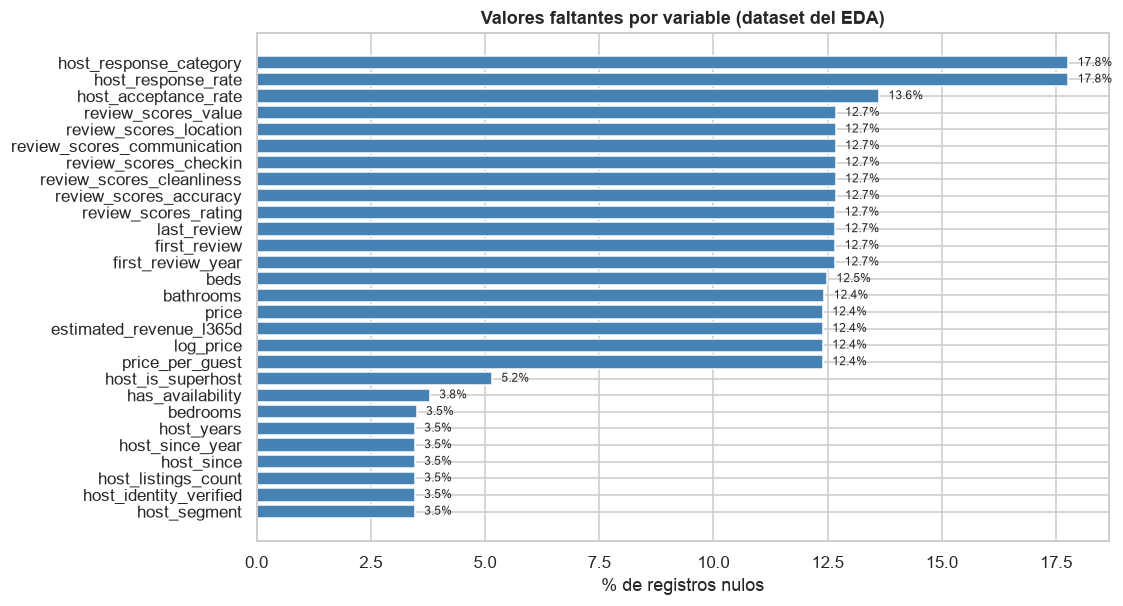

In [85]:
tabla_nulos = (pd.DataFrame({"nulos": df.isna().sum(), "pct": df.isna().mean().mul(100).round(2)})
               .query("nulos > 0").sort_values("nulos", ascending=False))
print(f"Columnas con nulos: {len(tabla_nulos)} de {df.shape[1]}")
display(tabla_nulos)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(tabla_nulos.index[::-1], tabla_nulos["pct"][::-1], color=AZUL)
for y, v in enumerate(tabla_nulos["pct"][::-1]):
    ax.text(v + 0.2, y, f"{v:.1f}%", va="center", fontsize=8)
ax.set_title("Valores faltantes por variable (dataset del EDA)")
ax.set_xlabel("% de registros nulos")
guardar(fig, "00_nulos_por_variable.png")
plt.show()

El diccionario resume cada variable con su bloque, tipo, número de nulos y valores únicos.

In [86]:
bloques = {
    "Identificación":        ["id", "name", "host_id", "last_scraped"],
    "Anfitrión":             ["host_since", "host_years", "host_is_superhost", "host_identity_verified",
                              "host_response_category", "host_response_rate", "host_acceptance_rate",
                              "host_listings_count", "host_segment", "verif_email", "verif_phone", "verif_work_email"],
    "Ubicación":             ["neighbourhood_cleansed", "latitude", "longitude"],
    "Propiedad":             ["property_type", "property_group", "room_type", "accommodates", "bathrooms",
                              "bedrooms", "beds", "amenities_count"] + [c for c in df.columns if c.startswith("amen_")],
    "Precio y estancia":     ["price", "log_price", "price_per_guest", "minimum_nights", "maximum_nights", "outlier_price_iqr", "tiene_precio"],
    "Disponibilidad":        ["has_availability", "availability_30", "availability_90", "availability_365", "instant_bookable"],
    "Demanda y reputación":  ["number_of_reviews", "number_of_reviews_ltm", "reviews_per_month", "first_review",
                              "first_review_year", "last_review", "review_scores_rating", "review_scores_accuracy",
                              "review_scores_cleanliness", "review_scores_checkin", "review_scores_communication",
                              "review_scores_location", "review_scores_value", "estimated_occupancy_l365d",
                              "estimated_revenue_l365d"],
    "Control de calidad":    ["flag_review_antes_host", "host_since_year"],
}
filas = []
for bloque, cols in bloques.items():
    for c in cols:
        filas.append({"bloque": bloque, "variable": c, "tipo": str(df[c].dtype),
                      "nulos": int(df[c].isna().sum()), "valores_unicos": int(df[c].nunique())})
diccionario = pd.DataFrame(filas)
assert set(diccionario["variable"]) == set(df.columns), "Hay variables sin clasificar"
display(diccionario.groupby("bloque", sort=False).size().rename("variables").to_frame())
diccionario

,variables
bloque,
Identificación,4
Anfitrión,12
Ubicación,3
Propiedad,18
Precio y estancia,7
Disponibilidad,5
Demanda y reputación,15
Control de calidad,2


,bloque,variable,tipo,nulos,valores_unicos
0,Identificación,id,int64,0,26322
1,Identificación,name,str,0,24905
2,Identificación,host_id,int64,0,11882
3,Identificación,last_scraped,datetime64[us],0,8
4,Anfitrión,host_since,datetime64[us],913,4127
...,...,...,...,...,...
61,Demanda y reputación,review_scores_value,float64,3337,155
62,Demanda y reputación,estimated_occupancy_l365d,int64,0,89
63,Demanda y reputación,estimated_revenue_l365d,float64,3265,11556
64,Control de calidad,flag_review_antes_host,int8,0,2


### c. Consulta de subsets de variables específicas y aleatorios

Se muestran cuatro formas de consultar subsets específicos y tres de obtener subsets aleatorios:

1. **Selección de columnas por nombre** (`df_p[[...]]`): subset de ubicación, tipo, capacidad y precio.
2. **Filtro booleano con `.loc`**: departamentos completos en Coyoacán por debajo de \$1,000; hay 321.
3. **Consulta con `.query()`**: alojamientos para 6 o más huéspedes con calificación de 4.9 o más y al menos 20
   reseñas: 536 anuncios, de los cuales 295 están en Cuauhtémoc (mediana \$2,930) y 91 en Miguel Hidalgo
   (mediana \$4,038).
4. **Selección posicional con `.iloc`**: filas 100 a 104 y primeras 6 columnas.

In [87]:
# 1) Selección de columnas específicas por nombre
subset_precio = df_p[["neighbourhood_cleansed", "room_type", "accommodates", "price", "price_per_guest"]]
print(f"Subset de precio y capacidad: {subset_precio.shape}")
subset_precio.head()

Subset de precio y capacidad: (23057, 5)


,neighbourhood_cleansed,room_type,accommodates,price,price_per_guest
0,Cuajimalpa de Morelos,Entire home/apt,2,"3,799.00","1,899.50"
1,Cuauhtémoc,Entire home/apt,14,"18,000.00","1,285.71"
2,Cuauhtémoc,Entire home/apt,2,585.00,292.50
3,Cuauhtémoc,Entire home/apt,4,"1,696.00",424.00
4,Coyoacán,Entire home/apt,2,"1,004.00",502.00


In [88]:
# 2) Filtro booleano con .loc: departamentos completos en Coyoacán por debajo de $1,000 la noche
filtro = ((df_p["room_type"] == "Entire home/apt")
          & (df_p["neighbourhood_cleansed"] == "Coyoacán")
          & (df_p["price"] < 1000))
coyoacan_economico = df_p.loc[filtro, ["name", "property_type", "accommodates", "price", "review_scores_rating"]]
print(f"Departamentos completos en Coyoacán con precio < $1,000: {len(coyoacan_economico):,}")
coyoacan_economico.sort_values("price").head(8)

Departamentos completos en Coyoacán con precio < $1,000: 321


,name,property_type,accommodates,price,review_scores_rating
24086,Loft a 10 min centro de Coyoacán,Entire rental unit,1,210.00,NaN
14292,Departamento con estacionamiento,Entire rental unit,2,259.00,NaN
5287,Hospedaje zona segura con vigilancia,Entire rental unit,1,300.00,NaN
6391,VILLA LUCIANA CDMX,Entire rental unit,2,345.00,4.80
21321,¡El Hogar de Tita!,Entire home,3,359.00,4.60
14846,"Cuarto Para Huésped es cómodo,tranquilo y seguro.",Entire condo,1,360.00,4.86
21537,Casa Tita,Entire home,2,360.00,4.80
3788,Departamento privado en planta baja,Tiny home,2,361.00,4.69


In [89]:
# 3) Consulta con .query: alojamientos grupales (>= 6 huéspedes) con calificación >= 4.9 y al menos 20 reseñas
grupales_top = df_p.query("accommodates >= 6 and review_scores_rating >= 4.9 and number_of_reviews >= 20")
print(f"Alojamientos grupales top: {len(grupales_top):,}")
display(grupales_top.groupby("neighbourhood_cleansed", observed=True)["price"]
        .agg(anuncios="count", precio_mediano="median")
        .sort_values("anuncios", ascending=False).head(6))

Alojamientos grupales top: 536


,anuncios,precio_mediano
neighbourhood_cleansed,,
Cuauhtémoc,295,"2,930.00"
Miguel Hidalgo,91,"4,038.00"
Benito Juárez,49,"1,775.00"
Coyoacán,36,"2,040.00"
Iztacalco,12,"1,027.00"
Venustiano Carranza,11,"1,408.00"


In [90]:
# 4) Selección posicional con .iloc: filas 100 a 104 y las primeras 6 columnas
df.iloc[100:105, :6]

,id,name,host_id,host_since,host_is_superhost,host_identity_verified
100,1676923,Two Floor apartment in Porfirian Town House,18979393,2014-07-27,False,True
101,1727725,"Descansa en la suite del geógrafo, San Angel CDMX",2518152,2012-06-01,True,True
102,1736063,"Cómodo Estudio del Botánico, San Angel CDMX",2518152,2012-06-01,True,True
103,1826212,nice apartment in colonia del Valle,9556116,2013-10-21,True,True
104,1850394,xolo stays / PH with roof garden and AC,456052310,2022-04-25,True,True


5. **Muestra aleatoria simple de filas** con `sample(n=8, random_state=42)`; la semilla hace la muestra
   reproducible.
6. **Subset aleatorio de variables:** se eligen al azar 6 columnas numéricas con `numpy.random.default_rng` y 5
   filas al azar.
7. **Muestra aleatoria estratificada** del 1% de cada `room_type` (231 anuncios). Mantiene las proporciones de la
   población (67.4% completos, 31.5% habitaciones privadas) y garantiza que los tipos minoritarios aparezcan, algo
   que una muestra simple de ese tamaño no asegura.

In [91]:
# 5) Muestra aleatoria simple de filas (reproducible con random_state)
muestra = df_p.sample(n=8, random_state=42)
muestra[["neighbourhood_cleansed", "room_type", "accommodates", "price", "review_scores_rating", "host_segment"]]

,neighbourhood_cleansed,room_type,accommodates,price,review_scores_rating,host_segment
20147,Miguel Hidalgo,Entire home/apt,4,523.00,4.33,21+
8195,Cuauhtémoc,Entire home/apt,3,900.00,4.92,2-5
12138,Miguel Hidalgo,Entire home/apt,2,"1,322.00",4.66,21+
24603,Miguel Hidalgo,Entire home/apt,4,"1,530.00",5.00,1 anuncio
9448,Cuauhtémoc,Entire home/apt,2,913.00,4.80,6-20
4274,Cuauhtémoc,Entire home/apt,5,"11,858.00",4.80,1 anuncio
23374,Benito Juárez,Private room,2,543.00,NaN,1 anuncio
14150,Venustiano Carranza,Private room,2,480.00,4.86,1 anuncio


In [92]:
# 6) Subset aleatorio de variables: se eligen 6 columnas numéricas al azar y 5 filas al azar
rng = np.random.default_rng(seed=7)
numericas = df.select_dtypes(include="number").columns.drop(["id", "host_id"])
cols_azar = sorted(rng.choice(numericas, size=6, replace=False))
print("Columnas elegidas al azar:", cols_azar)
df[cols_azar].sample(n=5, random_state=7)

Columnas elegidas al azar: ['amen_bed_linens', 'amen_iron', 'flag_review_antes_host', 'review_scores_location', 'review_scores_value', 'tiene_precio']


,amen_bed_linens,amen_iron,flag_review_antes_host,review_scores_location,review_scores_value,tiene_precio
20550,0,0,0,4.54,4.79,1
17614,1,0,0,3.75,4.25,1
8166,0,1,0,4.89,4.84,1
60,0,0,0,4.72,4.82,1
12594,1,0,0,4.27,4.36,0


In [93]:
# 7) Muestra aleatoria estratificada: 1% de cada room_type, para que los tipos minoritarios
#    (Shared room, Hotel room) no desaparezcan de la muestra como pasaría en un muestreo simple.
estratificada = df_p.groupby("room_type", observed=True, group_keys=False).sample(frac=0.01, random_state=42)
comp = pd.DataFrame({
    "% población": df_p["room_type"].value_counts(normalize=True).mul(100).round(2),
    "% muestra estratificada": estratificada["room_type"].value_counts(normalize=True).mul(100).round(2),
    "filas en muestra": estratificada["room_type"].value_counts(),
})
print(f"Tamaño de la muestra estratificada: {len(estratificada)}")
comp

Tamaño de la muestra estratificada: 231


,% población,% muestra estratificada,filas en muestra
room_type,,,
Entire home/apt,67.37,67.10,155
Private room,31.52,31.60,73
Shared room,0.87,0.87,2
Hotel room,0.23,0.43,1


### d. Conversión de variables categóricas a numéricas

**Diferencia conceptual entre las dos técnicas.**

- **Label Encoding** reemplaza cada categoría por un número entero (0, 1, 2, …) dentro de una sola columna. Es
  compacto, pero introduce un orden y unas distancias que no existen: un modelo interpretará que la categoría 3
  es "mayor" que la 1 y que la distancia entre 0 y 2 es el doble que entre 0 y 1. Solo es adecuado para variables
  ordinales (o para modelos de árboles, que no usan distancias).
- **One-Hot Encoding** crea una columna binaria por categoría (1 si la fila pertenece a esa categoría, 0 si no).
  No impone ningún orden, por lo que es la técnica estándar para variables nominales; su costo es que aumenta el
  número de columnas, lo que la vuelve poco práctica con cientos de categorías.

**Técnica seleccionada: One-Hot Encoding.** Las variables categóricas del proyecto son nominales (no existe un
orden entre Coyoacán y Tlalpan, ni entre un loft y un condominio) y tienen una cardinalidad manejable: 4 tipos de
alojamiento, 16 alcaldías y 12 grupos de propiedad. `host_response_category` sí tiene un orden (Fast > Moderate >
Slow), pero sus 4,677 nulos significan "sin historial de respuesta", una categoría que no cabe en esa escala; con
One-Hot se conserva como columna propia sin inventar su posición. Por eso se aplica One-Hot a las cuatro variables.

In [94]:
cat_cols = ["room_type", "neighbourhood_cleansed", "property_group", "host_response_category"]
cardinalidad = pd.DataFrame({
    "categorías": [df[c].nunique() for c in cat_cols],
    "nulos": [int(df[c].isna().sum()) for c in cat_cols],
    "tipo de variable": ["nominal", "nominal", "nominal", "ordinal (Fast > Moderate > Slow)"],
    "ejemplo": [", ".join(map(str, df[c].dropna().unique()[:3])) for c in cat_cols],
}, index=cat_cols)
cardinalidad

,categorías,nulos,tipo de variable,ejemplo
room_type,4,0,nominal,"Entire home/apt, Private room, Hotel room"
neighbourhood_cleansed,16,0,nominal,"Cuajimalpa de Morelos, Cuauhtémoc, Coyoacán"
property_group,12,0,nominal,"Otro, Entire home, Entire condo"
host_response_category,3,4677,ordinal (Fast > Moderate > Slow),"Fast, Moderate, Slow"


**Contraejemplo: qué pasaría con Label Encoding.** `LabelEncoder` asigna los códigos en orden alfabético:
Entire home/apt = 0, Hotel room = 1, Private room = 2 y Shared room = 3. Un modelo lineal entendería que Hotel room
está "entre" un departamento completo y una habitación privada, y que una habitación compartida "vale" el triple
que un hotel. Las medianas reales (\$1,275, \$1,693, \$562 y \$252) no siguen ese orden, así que el código numérico
introduciría una relación falsa con el precio.

In [95]:
# Contraejemplo: qué haría Label Encoding con room_type
le = LabelEncoder()
codigos = le.fit_transform(df["room_type"].astype(str))
mapa_label = pd.DataFrame({"room_type": le.classes_, "código asignado": range(len(le.classes_))})
display(mapa_label)

# El código es alfabético, no tiene relación con el precio ni con ningún orden real:
display(df_p.assign(codigo=le.transform(df_p["room_type"].astype(str)))
            .groupby(["codigo", "room_type"], observed=True)["price"].median()
            .rename("precio mediano").to_frame())

,room_type,código asignado
0,Entire home/apt,0
1,Hotel room,1
2,Private room,2
3,Shared room,3


,,precio mediano
codigo,room_type,
0,Entire home/apt,"1,275.00"
1,Hotel room,"1,693.00"
2,Private room,562.00
3,Shared room,252.00


**Proceso detallado de la conversión.**

1. **One-Hot con pandas sobre `room_type`** (`pd.get_dummies`): genera 4 columnas `room_*`. Se valida que cada
   fila tenga exactamente un 1 y que la suma de cada columna coincida con el conteo de su categoría (17,193;
   8,844; 204 y 81).
2. **One-Hot con scikit-learn sobre las 4 variables** (`OneHotEncoder`): los nulos de `host_response_category`
   se convierten antes en la categoría "Sin historial". Se generan 36 columnas (4 + 16 + 12 + 4). Se usa
   `handle_unknown="ignore"` para que una categoría nueva en datos futuros no rompa el pipeline, y se valida que
   por cada variable original haya un único 1 por fila.
3. **Ejemplo de una fila antes y después:** el anuncio 35797 (`Entire home/apt`, Cuajimalpa de Morelos, tipo
   "Otro", sin historial de respuesta) queda representado por un 1 en `room_type_Entire home/apt`,
   `neighbourhood_cleansed_Cuajimalpa de Morelos`, `property_group_Otro` y `host_response_category_Sin historial`,
   y 0 en las otras 32 columnas.
4. **Integración:** las booleanas se convierten a 0/1 y se unen con las numéricas, las binarias de amenities y
   verificaciones y las 36 dummies. El resultado es un dataset 100% numérico de 26,322 × 67 que se guarda en
   `data/gold/listings_encoded.csv`. Para modelos lineales se deja documentada la variante `drop="first"` (32
   columnas), que elimina una dummy por variable para evitar la trampa de la variable ficticia (colinealidad
   perfecta entre las dummies de un mismo grupo).

In [96]:
# Paso 1: One-Hot Encoding de room_type con pandas, mostrando el antes y el después
antes = df[["id", "room_type"]].head(6)
dummies_room = pd.get_dummies(df["room_type"], prefix="room", dtype="int8")
despues = pd.concat([antes, dummies_room.head(6)], axis=1)
display(despues)

# Validación: cada fila tiene exactamente un 1 entre las columnas generadas
assert (dummies_room.sum(axis=1) == 1).all()
print("Columnas generadas:", dummies_room.columns.tolist())
print("Frecuencia de cada columna (debe coincidir con value_counts):")
display(dummies_room.sum().rename("filas con 1").to_frame())

,id,room_type,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,35797,Entire home/apt,1,0,0,0
1,44616,Entire home/apt,1,0,0,0
2,56074,Entire home/apt,1,0,0,0
3,67703,Entire home/apt,1,0,0,0
4,70644,Entire home/apt,1,0,0,0
5,131610,Private room,0,0,1,0


Columnas generadas: ['room_Entire home/apt', 'room_Hotel room', 'room_Private room', 'room_Shared room']
Frecuencia de cada columna (debe coincidir con value_counts):


,filas con 1
room_Entire home/apt,17193
room_Hotel room,81
room_Private room,8844
room_Shared room,204


In [97]:
# Paso 2: One-Hot Encoding con scikit-learn sobre todas las variables categóricas.
# Los nulos de host_response_category significan "sin historial de respuesta": se convierten
# en una categoría explícita en lugar de imputarlos.
X_cat = df[cat_cols].astype(object).fillna("Sin historial")

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore", dtype=np.int8)
matriz = ohe.fit_transform(X_cat)
nombres = ohe.get_feature_names_out(cat_cols)
df_ohe = pd.DataFrame(matriz, columns=nombres, index=df.index)

resumen_ohe = pd.DataFrame({
    "categorías": [len(c) for c in ohe.categories_],
    "columnas generadas": [sum(n.startswith(c + "_") for n in nombres) for c in cat_cols],
}, index=cat_cols)
display(resumen_ohe)
print(f"Total de columnas dummy: {df_ohe.shape[1]}")

# Validación: por cada variable original, la suma de sus dummies es 1 en todas las filas
for c in cat_cols:
    bloque = [n for n in nombres if n.startswith(c + "_")]
    assert (df_ohe[bloque].sum(axis=1) == 1).all(), c
print("Validación OK: cada fila tiene un único 1 por variable codificada")

,categorías,columnas generadas
room_type,4,4
neighbourhood_cleansed,16,16
property_group,12,12
host_response_category,4,4


Total de columnas dummy: 36
Validación OK: cada fila tiene un único 1 por variable codificada


In [98]:
# Paso 3: Ejemplo de una fila antes y después de la codificación
fila = 0
print("Antes:")
display(df.loc[[fila], cat_cols])
print("Después (solo columnas con valor 1):")
display(df_ohe.loc[[fila], df_ohe.columns[df_ohe.loc[fila] == 1]])

Antes:


,room_type,neighbourhood_cleansed,property_group,host_response_category
0,Entire home/apt,Cuajimalpa de Morelos,Otro,NaN


Después (solo columnas con valor 1):


,room_type_Entire home/apt,neighbourhood_cleansed_Cuajimalpa de Morelos,property_group_Otro,host_response_category_Sin historial
0,1,1,1,1


In [99]:
# Paso 4: Booleanas a 0/1 e integración en un dataset 100% numérico
bool_num = df[cols_bool].astype("Int8").add_prefix("is_")

cols_num_modelo = ["accommodates", "bedrooms", "beds", "bathrooms", "amenities_count",
                   "minimum_nights", "availability_365", "number_of_reviews", "reviews_per_month",
                   "review_scores_rating", "host_listings_count", "host_years", "price"]
cols_bin = [c for c in df.columns if c.startswith(("amen_", "verif_"))]

df_encoded = pd.concat([df[["id"]], df[cols_num_modelo], df[cols_bin], bool_num, df_ohe], axis=1)
no_numericas = df_encoded.select_dtypes(exclude="number").columns.tolist()
print(f"Dataset codificado: {df_encoded.shape[0]:,} filas x {df_encoded.shape[1]} columnas")
print("Columnas no numéricas restantes:", no_numericas)

# Para modelos lineales se elimina una dummy por variable (categoría de referencia) para evitar
# la trampa de la variable ficticia (colinealidad perfecta entre dummies de un mismo grupo).
ohe_lineal = OneHotEncoder(sparse_output=False, drop="first", handle_unknown="ignore", dtype=np.int8).fit(X_cat)
print(f"Columnas dummy con drop='first': {len(ohe_lineal.get_feature_names_out(cat_cols))} "
      f"(una menos por cada una de las {len(cat_cols)} variables)")

df_encoded.to_csv("../data/gold/listings_encoded.csv", index=False)
print("Guardado en ../data/gold/listings_encoded.csv")

Dataset codificado: 26,322 filas x 67 columnas
Columnas no numéricas restantes: []
Columnas dummy con drop='first': 32 (una menos por cada una de las 4 variables)
Guardado en ../data/gold/listings_encoded.csv


### e. Estadísticas descriptivas

Se calcularon las medidas pedidas (media, mediana, moda, desviación estándar, varianza, mínimo, máximo, rango,
cuartiles y percentiles) más el rango intercuartílico (IQR), el coeficiente de variación, la asimetría y la
curtosis para las 16 variables numéricas más importantes del proyecto, sobre los 23,057 anuncios con precio.

In [100]:
VARS_CLAVE = ["price", "price_per_guest", "accommodates", "bedrooms", "beds", "bathrooms",
              "amenities_count", "minimum_nights", "availability_365", "number_of_reviews",
              "reviews_per_month", "review_scores_rating", "host_listings_count", "host_years",
              "estimated_occupancy_l365d", "estimated_revenue_l365d"]


def descriptivas(serie):
    s = serie.dropna().astype(float)
    moda = s.mode()
    return pd.Series({
        "n": len(s),
        "media": s.mean(),
        "mediana": s.median(),
        "moda": moda.iloc[0] if len(moda) else np.nan,
        "desv_std": s.std(),
        "varianza": s.var(),
        "mínimo": s.min(),
        "máximo": s.max(),
        "rango": s.max() - s.min(),
        "Q1 (P25)": s.quantile(0.25),
        "Q2 (P50)": s.quantile(0.50),
        "Q3 (P75)": s.quantile(0.75),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "P5": s.quantile(0.05),
        "P10": s.quantile(0.10),
        "P90": s.quantile(0.90),
        "P95": s.quantile(0.95),
        "P99": s.quantile(0.99),
        "coef_variación": s.std() / s.mean() if s.mean() else np.nan,
        "asimetría": stats.skew(s),
        "curtosis": stats.kurtosis(s),
    })


tabla_desc = pd.DataFrame({v: descriptivas(df_p[v]) for v in VARS_CLAVE}).T
tabla_desc.round(2)

,n,media,mediana,moda,desv_std,varianza,mínimo,máximo,rango,Q1 (P25),Q2 (P50),Q3 (P75),IQR,P5,P10,P90,P95,P99,coef_variación,asimetría,curtosis
price,"23,057.00","1,506.50","1,037.00",450.00,"2,432.12","5,915,226.34",66.00,"99,000.00","98,934.00",630.00,"1,037.00","1,639.00","1,009.00",329.00,410.00,"2,700.00","3,896.80","9,149.76",1.61,15.85,422.44
price_per_guest,"23,057.00",486.74,366.50,300.00,898.18,"806,725.58",18.94,"49,500.00","49,481.06",250.00,366.50,550.00,300.00,147.33,180.00,808.00,"1,050.20","2,180.30",1.85,33.00,"1,507.56"
accommodates,"23,057.00",3.35,2.00,2.00,2.29,5.26,1.00,16.00,15.00,2.00,2.00,4.00,2.00,1.00,2.00,6.00,7.00,14.00,0.69,2.49,9.06
bedrooms,"22,977.00",1.50,1.00,1.00,0.94,0.89,0.00,15.00,15.00,1.00,1.00,2.00,1.00,1.00,1.00,3.00,3.00,5.00,0.63,3.16,19.13
beds,"23,034.00",1.91,1.00,1.00,1.44,2.08,0.00,15.00,15.00,1.00,1.00,2.00,1.00,1.00,1.00,3.00,4.00,8.00,0.75,2.91,13.57
bathrooms,"23,050.00",1.49,1.00,1.00,0.92,0.85,0.00,15.00,15.00,1.00,1.00,2.00,1.00,1.00,1.00,2.00,3.00,5.00,0.62,3.44,21.73
amenities_count,"23,057.00",32.57,33.00,35.00,15.49,239.92,0.00,102.00,102.00,21.00,33.00,44.00,23.00,7.00,10.00,52.00,57.00,69.00,0.48,0.12,-0.44
minimum_nights,"23,057.00",3.84,2.00,1.00,17.64,311.02,1.00,365.00,364.00,1.00,2.00,2.00,1.00,1.00,1.00,4.00,7.00,30.00,4.60,16.51,313.16
availability_365,"23,057.00",256.23,290.00,365.00,106.62,"11,368.75",0.00,365.00,365.00,178.00,290.00,351.00,173.00,52.00,83.00,364.00,365.00,365.00,0.42,-0.79,-0.62
number_of_reviews,"23,057.00",56.68,24.00,0.00,85.71,"7,346.92",0.00,"1,342.00","1,342.00",5.00,24.00,73.00,68.00,0.00,0.00,151.00,220.00,413.44,1.51,3.36,18.49


**Interpretación por variable.**

- **Precio (`price`):** media de \$1,507 frente a mediana de \$1,037 y moda de \$450. La desviación
  estándar (\$2,432) supera a la media (coeficiente de variación 1.61) y la varianza (5.9 millones de MXN²) es poco
  interpretable por estar en unidades al cuadrado. El rango es de \$98,934 (de \$66 a \$99,000), pero el 90% central
  está entre \$329 (P5) y \$3,897 (P95). Una asimetría de 15.85 y una curtosis de 422 indican colas extremadamente
  pesadas: la mediana y el IQR (\$630–\$1,639) son las medidas representativas.
- **Precio por huésped:** mediana de \$367; el 90% de los anuncios cobra menos de \$808 por persona.
- **Capacidad (`accommodates`, `bedrooms`, `beds`, `bathrooms`):** mediana y moda coinciden en 2 huéspedes, 1
  recámara, 1 cama y 1 baño: el anuncio típico es un departamento pequeño para una pareja. El 75% recibe 4
  huéspedes o menos y el P99 llega a 14.
- **Amenities:** la única variable casi simétrica (media 32.6, mediana 33, asimetría 0.12) y con curtosis negativa,
  es decir, sin colas pesadas; el 50% central declara entre 21 y 44 servicios.
- **Estancia mínima:** mediana de 2 noches y moda de 1; el P99 es 30 y el máximo 365. Con un coeficiente de
  variación de 4.60 es la variable más dispersa en términos relativos.
- **Disponibilidad a 365 días:** asimetría negativa (−0.79), con moda de 365 y mediana de 290 días: la mitad de
  los anuncios tiene al menos 290 días libres en el año.
- **Reseñas:** mediana de 24 y media de 56.7, con moda 0; el P90 es 151 y el máximo 1,342. Las reseñas por mes
  tienen mediana de 1.13.
- **Calificación:** media 4.75, mediana 4.84 y moda 5.0; el coeficiente de variación (0.08) es el más bajo de todas
  las variables y el 75% de los anuncios está por encima de 4.70.
- **Anuncios por anfitrión:** mediana de 5 frente a media de 26.7 (5.3 veces), P95 de 102 y máximo de 896: unos
  pocos operadores grandes inflan la media.
- **Antigüedad del anfitrión:** mediana de 7.4 años, distribución casi simétrica (asimetría −0.21).
- **Ocupación e ingreso estimados:** ocupación mediana de 60 noches (moda 0, P90 en el tope de 255); ingreso
  mediano de \$58,320 al año frente a una media de \$129,888, con P99 de \$937,034.

**Conclusión general:** en 12 de las 16 variables la media supera a la mediana; la mayoría de las variables del
proyecto tiene asimetría positiva, por lo que la mediana, el IQR y los percentiles describen mejor el
"anuncio típico" que la media y la desviación estándar.

In [101]:
# Comparación de las medidas de tendencia central: cuando media >> mediana la distribución
# tiene cola a la derecha y la mediana es la medida representativa.
central = tabla_desc[["media", "mediana", "moda", "asimetría"]].copy()
central["media / mediana"] = (central["media"] / central["mediana"]).round(2)
central.round(2)

,media,mediana,moda,asimetría,media / mediana
price,"1,506.50","1,037.00",450.00,15.85,1.45
price_per_guest,486.74,366.50,300.00,33.00,1.33
accommodates,3.35,2.00,2.00,2.49,1.67
bedrooms,1.50,1.00,1.00,3.16,1.50
beds,1.91,1.00,1.00,2.91,1.91
bathrooms,1.49,1.00,1.00,3.44,1.49
amenities_count,32.57,33.00,35.00,0.12,0.99
minimum_nights,3.84,2.00,1.00,16.51,1.92
availability_365,256.23,290.00,365.00,-0.79,0.88
number_of_reviews,56.68,24.00,0.00,3.36,2.36


In [102]:
# Estadísticas del precio por tipo de alojamiento y por alcaldía
precio_room = (df_p.groupby("room_type", observed=True)["price"]
               .agg(anuncios="count", media="mean", mediana="median", desv_std="std",
                    Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75), P90=lambda s: s.quantile(0.90))
               .reindex(ORDEN_ROOM))
display(precio_room.round(0))

precio_alcaldia = (df_p.groupby("neighbourhood_cleansed", observed=True)["price"]
                   .agg(anuncios="count", media="mean", mediana="median", desv_std="std")
                   .sort_values("mediana", ascending=False))
display(precio_alcaldia.round(0))

,anuncios,media,mediana,desv_std,Q1,Q3,P90
room_type,,,,,,,
Entire home/apt,15534,"1,823.00","1,275.00","2,685.00",899.00,"1,943.00","3,118.00"
Private room,7268,845.00,562.00,"1,565.00",405.00,856.00,"1,427.00"
Shared room,201,320.00,252.00,242.00,197.00,333.00,558.00
Hotel room,54,"3,846.00","1,693.00","4,935.00",666.00,"5,049.00","10,330.00"


,anuncios,media,mediana,desv_std
neighbourhood_cleansed,,,,
Miguel Hidalgo,3897,"1,911.00","1,299.00","3,250.00"
Cuajimalpa de Morelos,358,"2,165.00","1,250.00","5,901.00"
Cuauhtémoc,10858,"1,696.00","1,209.00","2,225.00"
Álvaro Obregón,792,"1,192.00",908.00,"1,646.00"
Benito Juárez,2599,"1,070.00",809.00,"1,661.00"
La Magdalena Contreras,105,"1,115.00",763.00,935.00
Coyoacán,1410,"1,189.00",750.00,"2,525.00"
Milpa Alta,22,"1,226.00",725.00,"1,369.00"
Iztacalco,412,864.00,718.00,583.00


**Estadísticas del precio por grupo.** Por tipo de alojamiento, el 50% central de los espacios completos cobra
entre \$899 y \$1,943, y el de las habitaciones privadas entre \$405 y \$856; en Hotel room la media (\$3,846) más que
duplica la mediana (\$1,693). Por alcaldía, la mediana va de \$1,299 en Miguel Hidalgo a \$342 en Tláhuac, y la
desviación estándar supera a la media en 11 de las 16 alcaldías, señal de colas largas en casi todas las zonas
(el caso extremo es Cuajimalpa: \$5,901 frente a una media de \$2,165).

### f. Visualizaciones y análisis

Se diseñaron 21 visualizaciones agrupadas en seis temas: (1) precio y tipo de alojamiento (figuras 1–2),
(2) ubicación (3–5), (3) características del alojamiento (6–11), (4) reputación y anfitriones (12–16),
(5) demanda y operación (17–20) y (6) relaciones multivariadas (21). Para cada una
se responden los cuatro incisos de la guía: (i) tipo de gráfico y observaciones, (ii) atípicos o anomalías,
(iii) tendencias y patrones y (iv) comparaciones entre grupos. Al final de cada una se anotan las implicaciones para el
proyecto.
Las figuras que comparan distribuciones de precio usan escala logarítmica por la asimetría descrita en el punto e.

#### Figura 1. Distribución del precio por noche (variable objetivo)

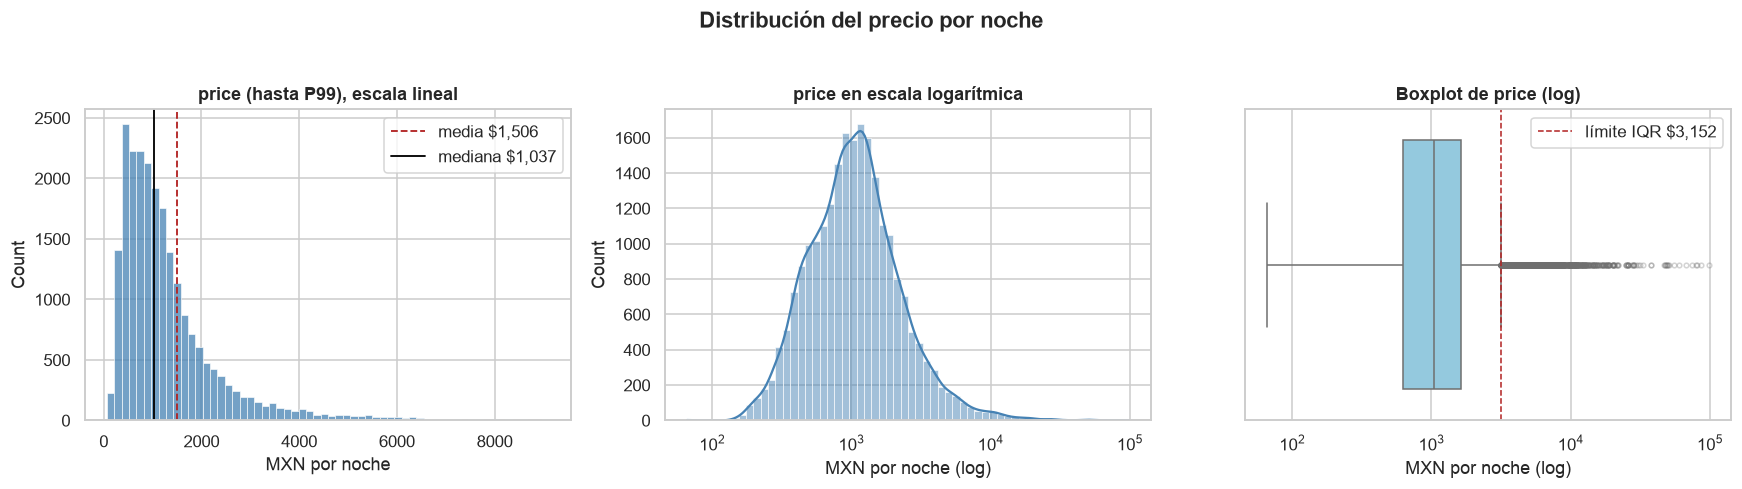

Asimetría price: 15.85 | asimetría log10(price): 0.52
Atípicos por IQR (> $3,152): 1,724 (7.5%)
Anuncios entre $500 y $2,000: 66.0%


In [103]:
p = df_p["price"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))

sns.histplot(p[p <= p.quantile(0.99)], bins=60, color=AZUL, ax=axes[0])
axes[0].axvline(p.mean(), color=ACENTO, ls="--", lw=1.2, label=f"media ${p.mean():,.0f}")
axes[0].axvline(p.median(), color="black", ls="-", lw=1.2, label=f"mediana ${p.median():,.0f}")
axes[0].set_title("price (hasta P99), escala lineal")
axes[0].set_xlabel("MXN por noche"); axes[0].legend()

sns.histplot(p, bins=60, log_scale=(True, False), color=AZUL, kde=True, ax=axes[1])
axes[1].set_title("price en escala logarítmica")
axes[1].set_xlabel("MXN por noche (log)")

sns.boxplot(x=p, color=AZUL_CLARO, ax=axes[2], flierprops={"marker": ".", "alpha": 0.3})
axes[2].set_xscale("log")
axes[2].axvline(lim_sup, color=ACENTO, ls="--", lw=1, label=f"límite IQR ${lim_sup:,.0f}")
axes[2].set_title("Boxplot de price (log)")
axes[2].set_xlabel("MXN por noche (log)"); axes[2].legend()
fig.suptitle("Distribución del precio por noche", y=1.03, fontweight="bold")
fig.tight_layout()
guardar(fig, "01_distribucion_price.png")
plt.show()

print(f"Asimetría price: {stats.skew(p):.2f} | asimetría log10(price): {stats.skew(np.log10(p)):.2f}")
print(f"Atípicos por IQR (> ${lim_sup:,.0f}): {df_p['outlier_price_iqr'].sum():,} ({df_p['outlier_price_iqr'].mean():.1%})")
print(f"Anuncios entre $500 y $2,000: {p.between(500, 2000).mean():.1%}")

**i. Tipo de gráfico y observaciones.** Se combinan tres vistas de la misma variable continua: un histograma en escala lineal (recortado en el percentil 99 para que la cola no aplaste la figura), un histograma en escala logarítmica con curva de densidad (KDE) y un boxplot logarítmico con el límite de Tukey. El histograma es la forma natural de ver la forma de una distribución continua; la escala log se eligió porque el precio abarca tres órdenes de magnitud (\$66 a \$99,000) y el boxplot resume cuartiles y atípicos en un solo trazo. La mediana es \$1,037 y la media \$1,506: la media supera a la mediana en 45%, señal de una cola larga a la derecha (asimetría de 15.85). En escala logarítmica la distribución se vuelve casi simétrica (asimetría 0.52) y unimodal, es decir, el precio se comporta aproximadamente como una variable log-normal. El 50% central de los anuncios está entre \$630 (Q1) y \$1,639 (Q3), y el 66% cobra entre \$500 y \$2,000 por noche.

**ii. Valores atípicos o anomalías.** Con la regla de 1.5 × IQR, 1,724 anuncios (7.5%) superan \$3,152 y se marcan en la columna `outlier_price_iqr`. Hay 202 anuncios a \$10,000 o más y 10 por encima de \$50,000; en el extremo bajo, 150 anuncios cobran menos de \$200. Estos valores inflan la media y hacen que la desviación estándar (\$2,432) sea mayor que la propia media: cualquier métrica basada en promedios o en errores al cuadrado quedaría dominada por un puñado de propiedades de lujo. No se eliminan porque son tarifas posibles del mercado.

**iii. Tendencias, patrones o agrupaciones.** La forma log-normal es el patrón típico de precios: los factores (tamaño, zona, tipo) actúan de manera multiplicativa sobre la tarifa. La masa de anuncios se agrupa alrededor de \$1,000 y decae de forma gradual hacia las tarifas altas.

**iv. Comparaciones entre grupos.** Esta vista mezcla segmentos muy distintos (departamentos completos, habitaciones, hoteles; zonas céntricas y periféricas), por lo que la cola larga anticipa que el precio debe analizarse por segmento: las siguientes visualizaciones comparan por tipo de alojamiento, alcaldía y capacidad.

**Implicaciones para el proyecto.** Para el objetivo del proyecto (predecir `price`) conviene modelar log10(price) en lugar del precio crudo, reportar la mediana como medida central y evaluar los modelos con métricas robustas (por ejemplo, error absoluto mediano) para que los atípicos no definan el resultado.

#### Figura 2. Tipo de alojamiento: volumen y precio

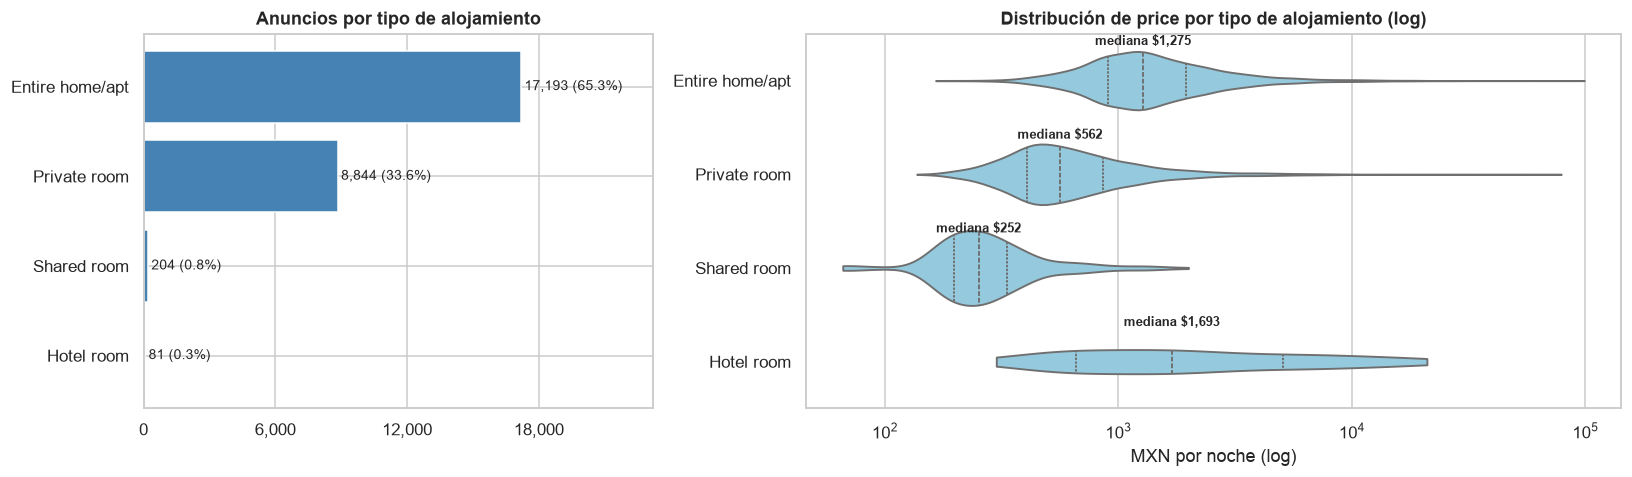

Kruskal-Wallis price ~ room_type: H = 6,682.8, p < 0.001


In [104]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
conteo = df["room_type"].value_counts().reindex(ORDEN_ROOM)
axes[0].barh(conteo.index[::-1], conteo.values[::-1], color=AZUL)
for y, v in enumerate(conteo.values[::-1]):
    axes[0].text(v + 150, y, f"{v:,} ({v / conteo.sum():.1%})", va="center", fontsize=9)
axes[0].set_title("Anuncios por tipo de alojamiento")
axes[0].set_xlim(0, conteo.max() * 1.35); fmt_miles(axes[0], "x")
axes[0].xaxis.set_major_locator(mtick.MaxNLocator(4))

sns.violinplot(data=df_p, x="price", y="room_type", order=ORDEN_ROOM, color=AZUL_CLARO,
               log_scale=True, inner="quartile", cut=0, ax=axes[1])
for y, r in enumerate(ORDEN_ROOM):
    med = df_p.loc[df_p["room_type"] == r, "price"].median()
    axes[1].text(med, y - 0.38, f"mediana ${med:,.0f}", ha="center", fontsize=8.5, fontweight="bold")
axes[1].set_title("Distribución de price por tipo de alojamiento (log)")
axes[1].set_ylabel(""); axes[1].set_xlabel("MXN por noche (log)")
fig.tight_layout()
guardar(fig, "02_room_type_conteo_precio.png")
plt.show()

prueba = stats.kruskal(*[df_p.loc[df_p["room_type"] == r, "price"] for r in ORDEN_ROOM])
print(f"Kruskal-Wallis price ~ room_type: H = {prueba.statistic:,.1f}, p {'< 0.001' if prueba.pvalue < 0.001 else f'= {prueba.pvalue:.3f}'}")

**i. Tipo de gráfico y observaciones.** Barras horizontales para el conteo de una variable categórica nominal con etiquetas largas, y diagrama de violín en escala log para comparar la distribución completa del precio entre los cuatro grupos; el violín muestra, además de los cuartiles (líneas punteadas), la forma de cada distribución, algo que un boxplot oculta. Entire home/apt concentra el 65.3% de la oferta (17,193 anuncios) y Private room el 33.6% (8,844); Shared room (0.8%) y Hotel room (0.3%) son marginales. Las medianas de precio son \$1,275 (completo), \$562 (privada), \$252 (compartida) y \$1,693 (hotel). Un espacio completo cuesta 2.3 veces lo que una habitación privada. La prueba de Kruskal-Wallis (H = 6,683; p < 0.001) confirma que las diferencias entre grupos no se deben al azar.

**ii. Valores atípicos o anomalías.** Private room tiene una cola que llega cerca de \$80,000, una tarifa poco creíble para una habitación y candidata a error de captura o de clasificación del anuncio. Hotel room es el grupo más disperso (Q1 \$666, Q3 \$5,049) con solo 54 anuncios con precio: su mediana es inestable y no debe generalizarse.

**iii. Tendencias, patrones o agrupaciones.** Se observa un gradiente claro de privacidad: compartida < privada < completa. En escala log las distribuciones se desplazan casi sin cambiar de forma, lo que confirma el efecto multiplicativo del tipo de alojamiento sobre el precio.

**iv. Comparaciones entre grupos.** La comparación más importante es completo vs. habitación privada, que juntos suman el 98.9% del mercado. Hotel room no es comparable con los demás: es más caro que un departamento completo pero con muy pocas observaciones y una mezcla de hoteles boutique y económicos.

**Implicaciones para el proyecto.** `room_type` es la primera variable de segmentación del proyecto: cualquier comparación de precios (por zona, capacidad o amenities) debe hacerse dentro del mismo tipo de alojamiento, y el modelo de precio debe incluirla (codificada con One-Hot, punto II.d).

#### Figura 3. Oferta de anuncios por alcaldía

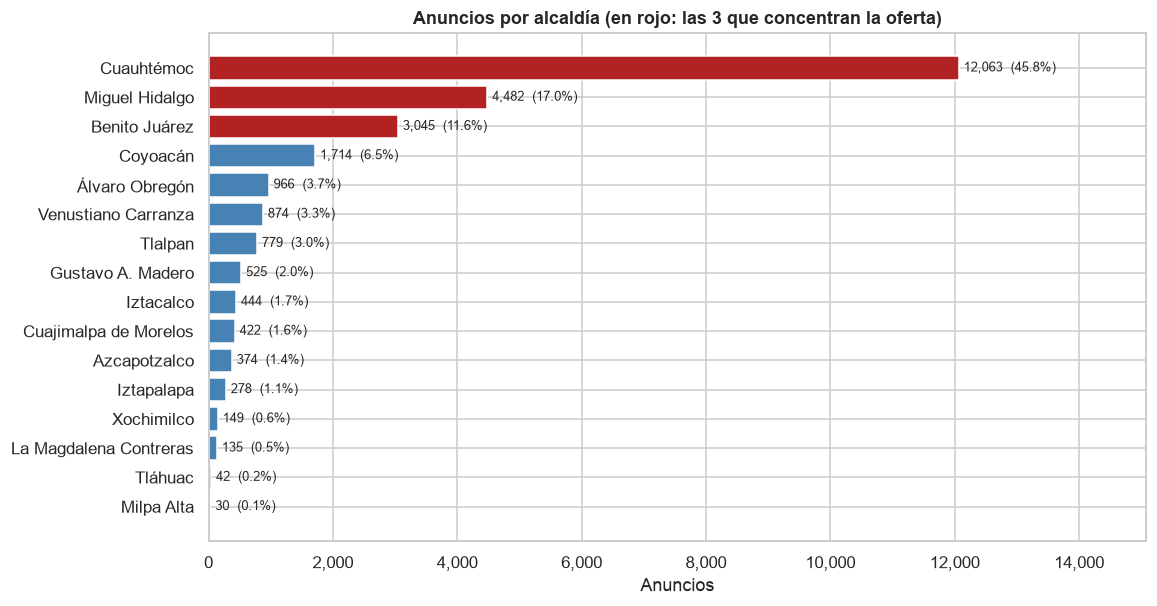

Top 3 alcaldías: 74.4% de la oferta | 8 alcaldías con menos anuncios: 7.1%


In [105]:
conteo_alc = df["neighbourhood_cleansed"].value_counts()
acum = conteo_alc.cumsum() / conteo_alc.sum()

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(conteo_alc.index[::-1], conteo_alc.values[::-1],
        color=[ACENTO if a in conteo_alc.index[:3] else AZUL for a in conteo_alc.index[::-1]])
for y, (alc, v) in enumerate(zip(conteo_alc.index[::-1], conteo_alc.values[::-1])):
    ax.text(v + 80, y, f"{v:,}  ({v / conteo_alc.sum():.1%})", va="center", fontsize=8.5)
ax.set_xlim(0, conteo_alc.max() * 1.25); fmt_miles(ax, "x")
ax.set_title("Anuncios por alcaldía (en rojo: las 3 que concentran la oferta)")
ax.set_xlabel("Anuncios")
guardar(fig, "03_anuncios_por_alcaldia.png")
plt.show()

print(f"Top 3 alcaldías: {acum.iloc[2]:.1%} de la oferta | 8 alcaldías con menos anuncios: "
      f"{conteo_alc.tail(8).sum() / conteo_alc.sum():.1%}")

**i. Tipo de gráfico y observaciones.** Barras horizontales ordenadas de mayor a menor: con 16 categorías y nombres largos es la forma más legible de comparar magnitudes; se resaltan en rojo las tres alcaldías que concentran la oferta y se rotula cada barra con su conteo y porcentaje. La oferta está muy concentrada: Cuauhtémoc (45.8%), Miguel Hidalgo (17.0%) y Benito Juárez (11.6%) suman el 74.4% de los anuncios. Las ocho alcaldías con menos oferta, juntas, apenas llegan al 7.1%; Milpa Alta (30 anuncios) y Tláhuac (42) son casi inexistentes en la plataforma.

**ii. Valores atípicos o anomalías.** No hay valores atípicos en sentido numérico, pero sí categorías con muy pocas observaciones (Milpa Alta, Tláhuac, La Magdalena Contreras, Xochimilco con menos de 150). Cualquier estadística por alcaldía en esos grupos tiene alta varianza y puede cambiar mucho con unos pocos anuncios.

**iii. Tendencias, patrones o agrupaciones.** La oferta decrece del centro hacia la periferia: las alcaldías centrales y con mayor actividad turística y de negocios dominan, mientras que las del oriente y del sur tienen presencia mínima.

**iv. Comparaciones entre grupos.** El contraste relevante es centro vs. periferia. Cuauhtémoc sola tiene más anuncios que las otras 13 alcaldías fuera del top 3 juntas, lo que implica un mercado más competido y con más alternativas para el huésped.

**Implicaciones para el proyecto.** El desbalance obliga a usar muestreo o validación estratificada por alcaldía al entrenar modelos y a agrupar las alcaldías pequeñas si se usan como variable; de lo contrario, el modelo aprenderá casi exclusivamente el comportamiento de Cuauhtémoc.

#### Figura 4. Precio por alcaldía

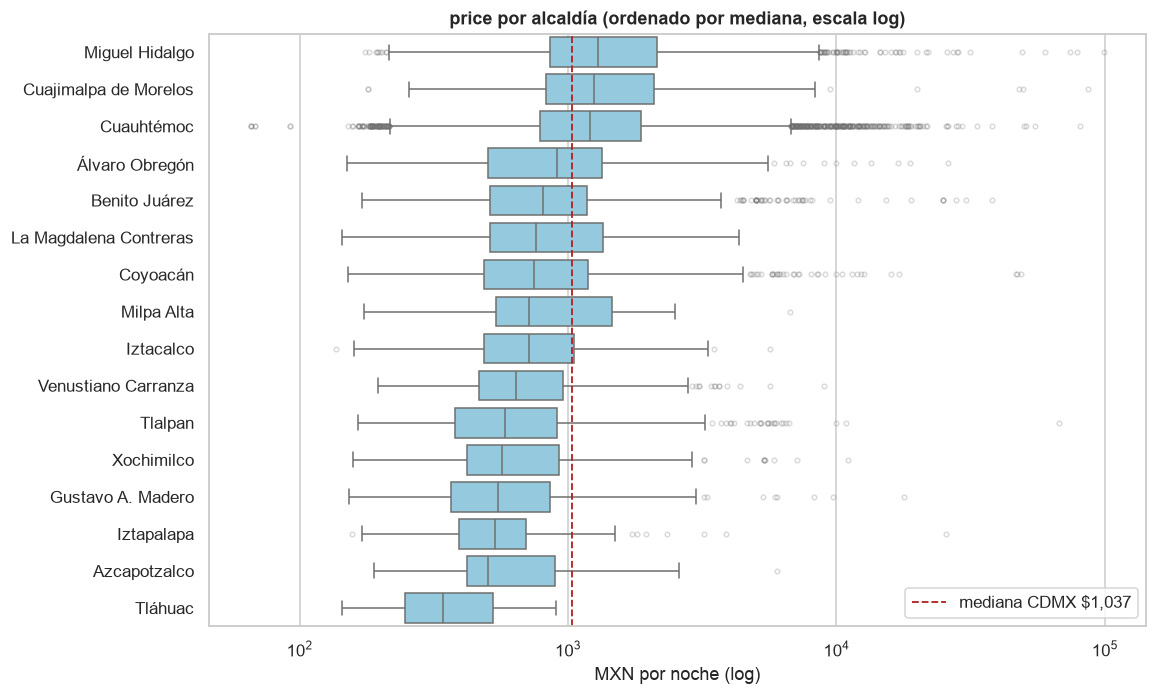

neighbourhood_cleansed,Miguel Hidalgo,Cuajimalpa de Morelos,Cuauhtémoc,Álvaro Obregón,Benito Juárez,La Magdalena Contreras,Coyoacán,Milpa Alta,Iztacalco,Venustiano Carranza,Tlalpan,Xochimilco,Gustavo A. Madero,Iztapalapa,Azcapotzalco,Tláhuac
median,"1,299.00","1,250.00","1,209.00",908.00,809.00,763.00,750.00,725.00,718.00,638.00,585.00,569.00,550.00,536.00,502.00,342.00
count,"3,897.00",358.00,"10,858.00",792.00,"2,599.00",105.00,"1,410.00",22.00,412.00,795.00,616.00,124.00,467.00,229.00,338.00,35.00


Kruskal-Wallis price ~ alcaldía: H = 3,321.2, p < 0.001


In [106]:
orden_alc = df_p.groupby("neighbourhood_cleansed", observed=True)["price"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(11, 7))
sns.boxplot(data=df_p, y="neighbourhood_cleansed", x="price", order=orden_alc, color=AZUL_CLARO,
            log_scale=True, showfliers=True, flierprops={"marker": ".", "alpha": 0.25}, ax=ax)
ax.axvline(df_p["price"].median(), color=ACENTO, ls="--", lw=1.2, label=f"mediana CDMX ${df_p['price'].median():,.0f}")
ax.set_title("price por alcaldía (ordenado por mediana, escala log)")
ax.set_xlabel("MXN por noche (log)"); ax.set_ylabel(""); ax.legend(loc="lower right")
guardar(fig, "04_price_por_alcaldia.png")
plt.show()

med_alc = df_p.groupby("neighbourhood_cleansed", observed=True)["price"].agg(["median", "count"]).sort_values("median", ascending=False)
display(med_alc.round(0).T)
prueba = stats.kruskal(*[g["price"].values for _, g in df_p.groupby("neighbourhood_cleansed", observed=True)])
print(f"Kruskal-Wallis price ~ alcaldía: H = {prueba.statistic:,.1f}, p {'< 0.001' if prueba.pvalue < 0.001 else f'= {prueba.pvalue:.3f}'}")

**i. Tipo de gráfico y observaciones.** Boxplots horizontales ordenados por mediana en escala logarítmica: permiten comparar a la vez la mediana, la dispersión (IQR) y los atípicos de 16 grupos; la línea roja marca la mediana de toda la ciudad como referencia. Solo tres alcaldías superan la mediana de la ciudad (\$1,037): Miguel Hidalgo (\$1,299), Cuajimalpa (\$1,250) y Cuauhtémoc (\$1,209). En el otro extremo están Tláhuac (\$342), Azcapotzalco (\$502) e Iztapalapa (\$536). La mediana más alta es 3.8 veces la más baja. Kruskal-Wallis: H = 3,321, p < 0.001.

**ii. Valores atípicos o anomalías.** Cuauhtémoc y Miguel Hidalgo concentran los atípicos altos (hasta cerca de \$99,000) y Cuauhtémoc también tiene los más bajos (mínimo \$66). Cuajimalpa tiene una desviación estándar de \$5,901 frente a una mediana de \$1,250: unas pocas residencias de lujo disparan su media (\$2,165), por lo que en estas zonas la media no es representativa.

**iii. Tendencias, patrones o agrupaciones.** Hay un gradiente espacial: las alcaldías del poniente y del centro (Miguel Hidalgo, Cuajimalpa, Cuauhtémoc, Álvaro Obregón) son más caras, y las del norte y oriente (Gustavo A. Madero, Iztapalapa, Azcapotzalco, Tláhuac) más baratas.

**iv. Comparaciones entre grupos.** Benito Juárez es la tercera alcaldía en oferta pero su mediana (\$809) es 33% menor que la de Cuauhtémoc; Coyoacán (\$750) también queda por debajo de la mediana de la ciudad pese a ser una zona turística. Milpa Alta (22 anuncios con precio) aparece en mitad de la tabla, pero su posición no es confiable por el tamaño de muestra.

**Implicaciones para el proyecto.** La ubicación es un determinante fuerte del precio, pero la alcaldía es una unidad gruesa: dentro de cada una el IQR es amplio. Para el modelo conviene sumar variables de ubicación más finas (coordenadas, distancia a zonas de alta demanda o la colonia).

#### Figura 5. Distribución geográfica de la oferta y del precio

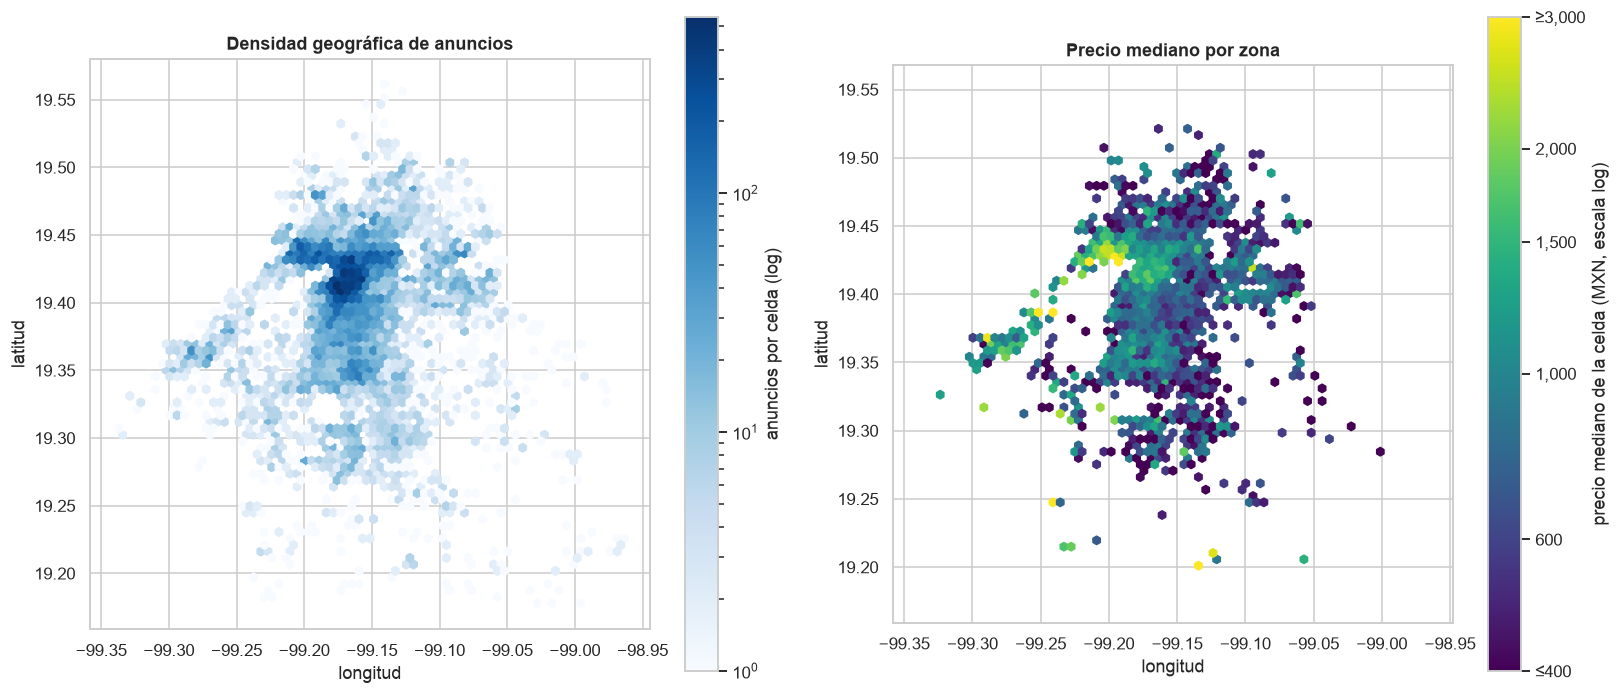

In [107]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
hb = axes[0].hexbin(df["longitude"], df["latitude"], gridsize=70, bins="log", cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=axes[0], label="anuncios por celda (log)")
axes[0].set_title("Densidad geográfica de anuncios")

# Cada celda se colorea con la MEDIANA del precio de los anuncios que contiene (mínimo 3),
# así ningún punto caro tapa a los baratos por el orden de dibujo.
hb2 = axes[1].hexbin(df_p["longitude"], df_p["latitude"], C=df_p["log_price"], reduce_C_function=np.median,
                     gridsize=70, cmap="viridis", mincnt=3, vmin=np.log10(400), vmax=np.log10(3000))
cb = fig.colorbar(hb2, ax=axes[1], label="precio mediano de la celda (MXN, escala log)")
cb.set_ticks(np.log10([400, 600, 1000, 1500, 2000, 3000]))
cb.set_ticklabels(["≤400", "600", "1,000", "1,500", "2,000", "≥3,000"])
axes[1].set_title("Precio mediano por zona")
for ax in axes:
    ax.set_xlabel("longitud"); ax.set_ylabel("latitud"); ax.set_aspect("equal")
fig.tight_layout()
guardar(fig, "05_mapa_densidad_precio.png")
plt.show()

**i. Tipo de gráfico y observaciones.** Dos mapas de hexágonos (hexbin) con longitud y latitud: con más de 26,000 puntos un gráfico de dispersión se satura, mientras que el hexbin agrega en celdas. El primero cuenta anuncios por celda (escala log); el segundo colorea cada celda con la mediana del precio de los anuncios que contiene (mínimo 3), de modo que el resultado no depende del orden en que se dibujan los puntos. La densidad máxima está en un núcleo entre las latitudes 19.40–19.44 y longitudes −99.20 a −99.15, que corresponde a Cuauhtémoc y Miguel Hidalgo (zona de colonias como Roma, Condesa, Juárez y Polanco). En el mapa de precios, las celdas con medianas de \$2,000 o más se concentran en el extremo poniente de ese núcleo (zona de Polanco, en Miguel Hidalgo) y en el corredor del poniente hacia Lomas y Santa Fe (Cuajimalpa y Álvaro Obregón); el resto del núcleo se ubica entre \$1,000 y \$1,500, y la periferia norte, oriente y sur queda mayormente por debajo de \$600.

**ii. Valores atípicos o anomalías.** Aparecen celdas aisladas en el sur (Tlalpan, Xochimilco) con medianas altas: son pocas casas grandes en zonas de baja densidad y no representan el nivel de precios de esas alcaldías. También hay anuncios dispersos lejos del núcleo que, por estar solos en su celda, no se muestran en el mapa de precios.

**iii. Tendencias, patrones o agrupaciones.** El precio presenta autocorrelación espacial: las celdas caras están juntas y el precio decae a medida que uno se aleja del núcleo central y del corredor del poniente.

**iv. Comparaciones entre grupos.** Dentro de una misma alcaldía conviven celdas de colores distintos (por ejemplo, el norte y el sur de Cuauhtémoc), lo que confirma lo observado en el boxplot anterior: la alcaldía agrupa zonas con niveles de precio diferentes.

**Implicaciones para el proyecto.** Las coordenadas deben aprovecharse en el modelado mediante variables derivadas (distancia al núcleo de mayor demanda, agrupamientos espaciales o la colonia), porque aportan información que la alcaldía sola no captura.

#### Figura 6. Tipo de propiedad: volumen y precio mediano

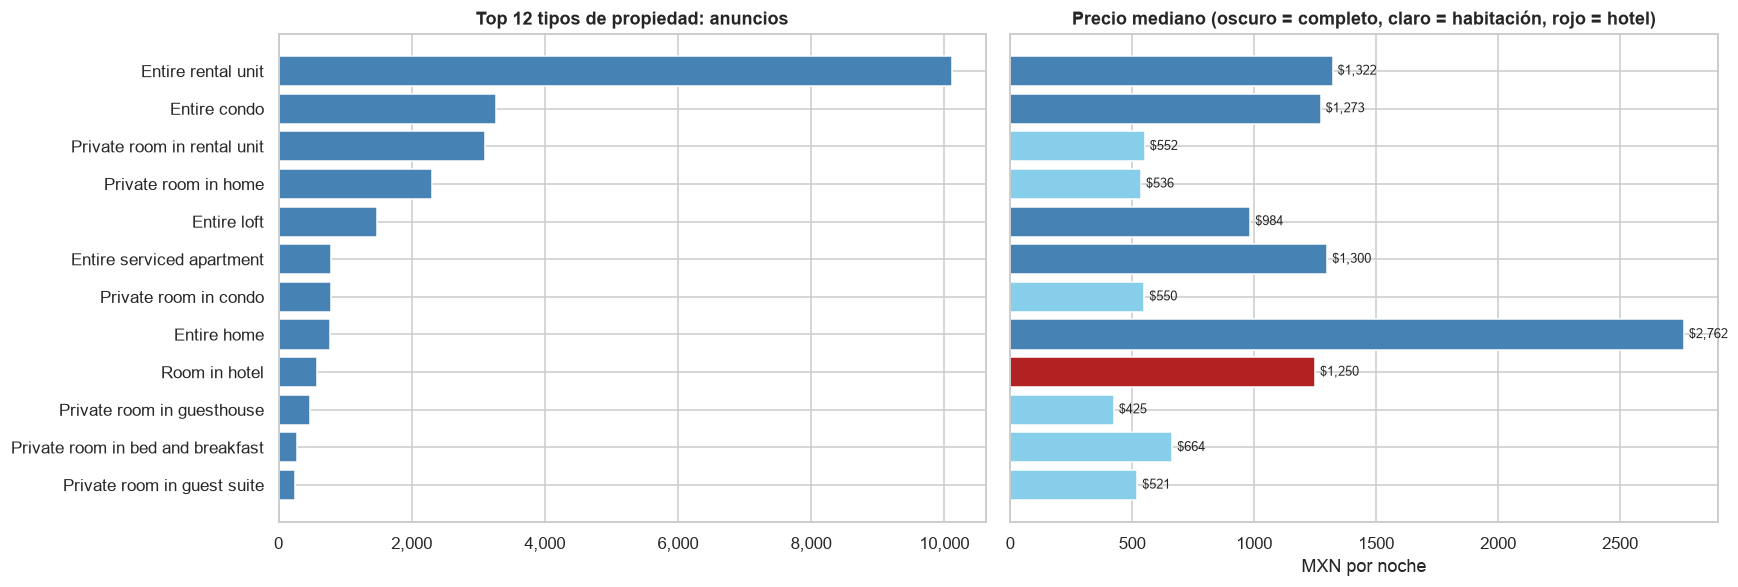

Los 12 tipos más frecuentes cubren 91.9% de los anuncios (80 tipos en total)


In [108]:
top_prop = df["property_type"].value_counts().head(12)
stats_prop = (df_p[df_p["property_type"].isin(top_prop.index)]
              .groupby("property_type", observed=True)["price"].median().reindex(top_prop.index))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), sharey=True)
axes[0].barh(top_prop.index[::-1], top_prop.values[::-1], color=AZUL)
axes[0].set_title("Top 12 tipos de propiedad: anuncios"); fmt_miles(axes[0], "x")
colores = [AZUL if t.startswith("Entire") else (ACENTO if "hotel" in t.lower() else AZUL_CLARO) for t in stats_prop.index[::-1]]
axes[1].barh(stats_prop.index[::-1], stats_prop.values[::-1], color=colores)
for y, v in enumerate(stats_prop.values[::-1]):
    axes[1].text(v + 20, y, f"${v:,.0f}", va="center", fontsize=8.5)
axes[1].set_title("Precio mediano (oscuro = completo, claro = habitación, rojo = hotel)")
axes[1].set_xlabel("MXN por noche")
fig.tight_layout()
guardar(fig, "06_property_type.png")
plt.show()
print(f"Los 12 tipos más frecuentes cubren {top_prop.sum() / len(df):.1%} de los anuncios "
      f"({df['property_type'].nunique()} tipos en total)")

**i. Tipo de gráfico y observaciones.** Dos barras horizontales con eje compartido: a la izquierda cuántos anuncios hay de cada tipo y a la derecha su precio mediano, con color según si es espacio completo, habitación u hotel. Se muestran los 12 tipos más frecuentes porque cubren el 91.9% de la oferta (de 80 tipos en total). Entire rental unit domina con 10,124 anuncios (38%), seguido de Entire condo (3,269) y Private room in rental unit (3,098). En precio, Entire home (\$2,762) es por mucho el más caro; los demás espacios completos rondan entre \$984 (loft) y \$1,322 (rental unit), y las habitaciones privadas entre \$425 (guesthouse) y \$664 (bed and breakfast).

**ii. Valores atípicos o anomalías.** La variable original tiene una cola de 69 tipos poco frecuentes (menos de 1% cada uno), como contenedores, domos, cabañas o casas diminutas (tiny homes); con tan pocas observaciones sus estadísticas no son confiables y por eso se agruparon en la categoría Otro (`property_group`, 12 categorías).

**iii. Tendencias, patrones o agrupaciones.** El color revela el patrón: el precio lo define primero si el espacio es completo o compartido, y luego el tamaño. Dentro de los espacios completos, la casa (Entire home) recibe en mediana 6 huéspedes frente a 4 de un departamento, lo que explica buena parte de su precio.

**iv. Comparaciones entre grupos.** Entire home vs. Entire rental unit: la casa cuesta 2.1 veces más. Room in hotel (\$1,250) cuesta más del doble que cualquier habitación privada en vivienda, lo que la ubica como un segmento distinto.

**Implicaciones para el proyecto.** `property_type` es parcialmente redundante con `room_type` y tiene alta cardinalidad; para el modelo se usa `property_group`, que conserva los tipos relevantes sin generar 80 columnas dummy.

#### Figura 7. Capacidad (huéspedes) y precio

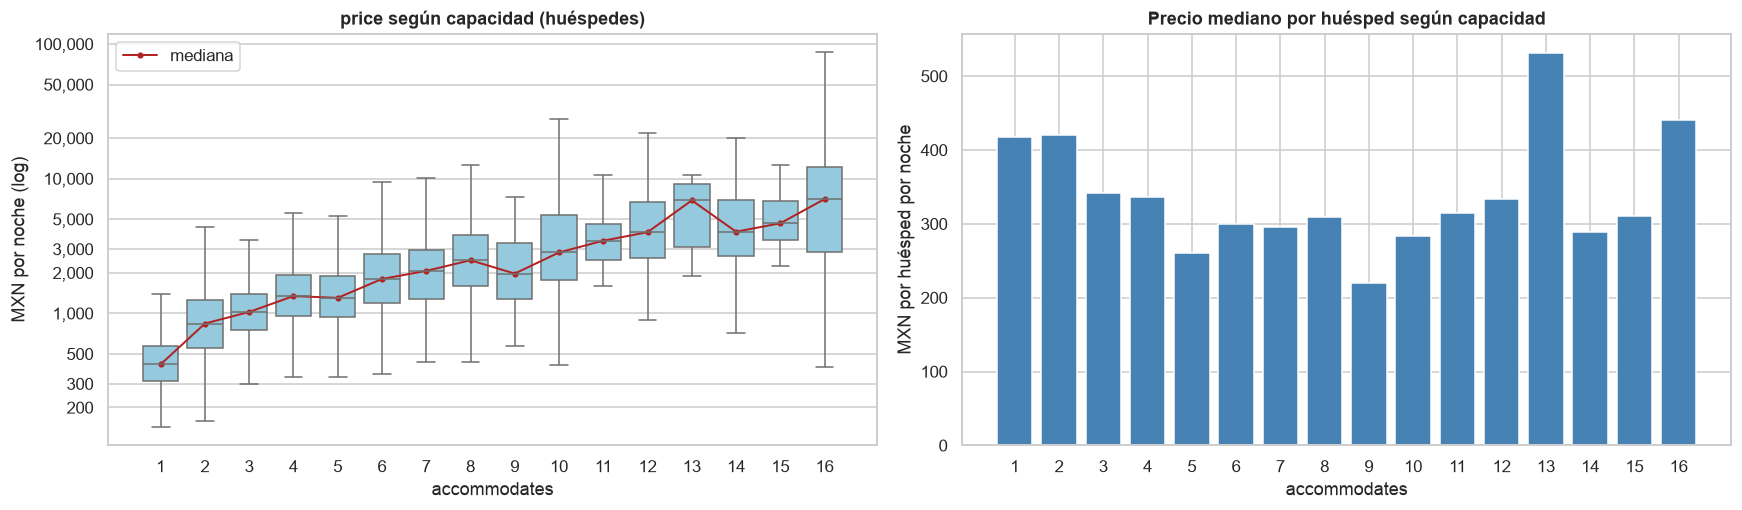

Spearman accommodates ~ price: rho = 0.56


accommodates,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
precio_mediano,418.00,840.00,"1,024.00","1,343.00","1,303.00","1,800.00","2,067.00","2,479.00","1,974.00","2,832.00","3,463.00","4,004.00","6,900.00","4,038.00","4,665.00","7,058.00"
precio_por_huesped,418.00,420.00,341.00,336.00,261.00,300.00,295.00,310.00,219.00,283.00,315.00,334.00,531.00,288.00,311.00,441.00
anuncios,"2,282.00","9,425.00","2,175.00","4,955.00","1,208.00","1,621.00",270.00,448.00,66.00,196.00,20.00,105.00,17.00,56.00,28.00,185.00


In [109]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
sns.boxplot(data=df_p, x="accommodates", y="price", color=AZUL_CLARO, log_scale=True,
            showfliers=False, ax=axes[0])
med = df_p.groupby("accommodates")["price"].median()
axes[0].plot(range(len(med)), med.values, color=ACENTO, marker="o", ms=3, lw=1.3, label="mediana")
axes[0].set_title("price según capacidad (huéspedes)"); axes[0].set_ylabel("MXN por noche (log)")
eje_log_plano(axes[0])
axes[0].legend()

ppg = df_p.groupby("accommodates")["price_per_guest"].median()
axes[1].bar(ppg.index.astype(str), ppg.values, color=AZUL)
axes[1].set_title("Precio mediano por huésped según capacidad")
axes[1].set_xlabel("accommodates"); axes[1].set_ylabel("MXN por huésped por noche")
fig.tight_layout()
guardar(fig, "07_capacidad_precio.png")
plt.show()

rho = stats.spearmanr(df_p["accommodates"], df_p["price"])
print(f"Spearman accommodates ~ price: rho = {rho.statistic:.2f}")
display(pd.DataFrame({"precio_mediano": med, "precio_por_huesped": ppg, "anuncios": df_p["accommodates"].value_counts()}).T.round(0))

**i. Tipo de gráfico y observaciones.** Boxplots por cada valor de `accommodates` (variable discreta de 1 a 16) con la mediana unida por una línea para ver la tendencia, y barras del precio mediano por huésped. Se eligió boxplot y no dispersión porque con valores enteros los puntos se apilan en columnas y ocultan la densidad. La mediana crece de \$418 (1 huésped) a \$840 (2), \$1,343 (4), \$1,800 (6), \$2,479 (8) y \$7,058 (16). Con una correlación de Spearman de 0.56, la capacidad es la variable numérica más asociada al precio. En cambio, el precio por huésped baja de \$418–\$420 (1–2 huéspedes) a un rango de \$220–\$340 entre 3 y 10 huéspedes.

**ii. Valores atípicos o anomalías.** El valor 16 agrupa 185 anuncios con una dispersión enorme: Airbnb limita la capacidad publicada a "16+", así que ese grupo mezcla propiedades de 16 personas con otras mucho mayores (dato censurado). Los grupos de 9, 11 y 13 huéspedes tienen menos de 70 anuncios y producen saltos en la línea (13 huéspedes: \$6,900 con solo 17 anuncios) que no deben interpretarse como tendencia.

**iii. Tendencias, patrones o agrupaciones.** Relación positiva, monótona y no lineal: cada huésped adicional suma cada vez menos en términos relativos. Existe además un patrón par/impar: las capacidades impares (5, 9) tienen precios similares o menores que la par anterior, porque suelen ser el mismo alojamiento con una cama extra.

**iv. Comparaciones entre grupos.** Pasar de 2 a 4 huéspedes aumenta la mediana 60%, y de 4 a 8 huéspedes 85%. El precio por huésped muestra economías de escala: hospedarse en grupo es más barato por persona, un argumento relevante para segmentar el mercado de viajeros individuales y de grupos.

**Implicaciones para el proyecto.** `accommodates` debe estar en el modelo, idealmente con una transformación no lineal o junto con log(price). El precio por huésped es una métrica útil para comparar anuncios de distinto tamaño.

#### Figura 8. Recámaras, baños y camas frente al precio

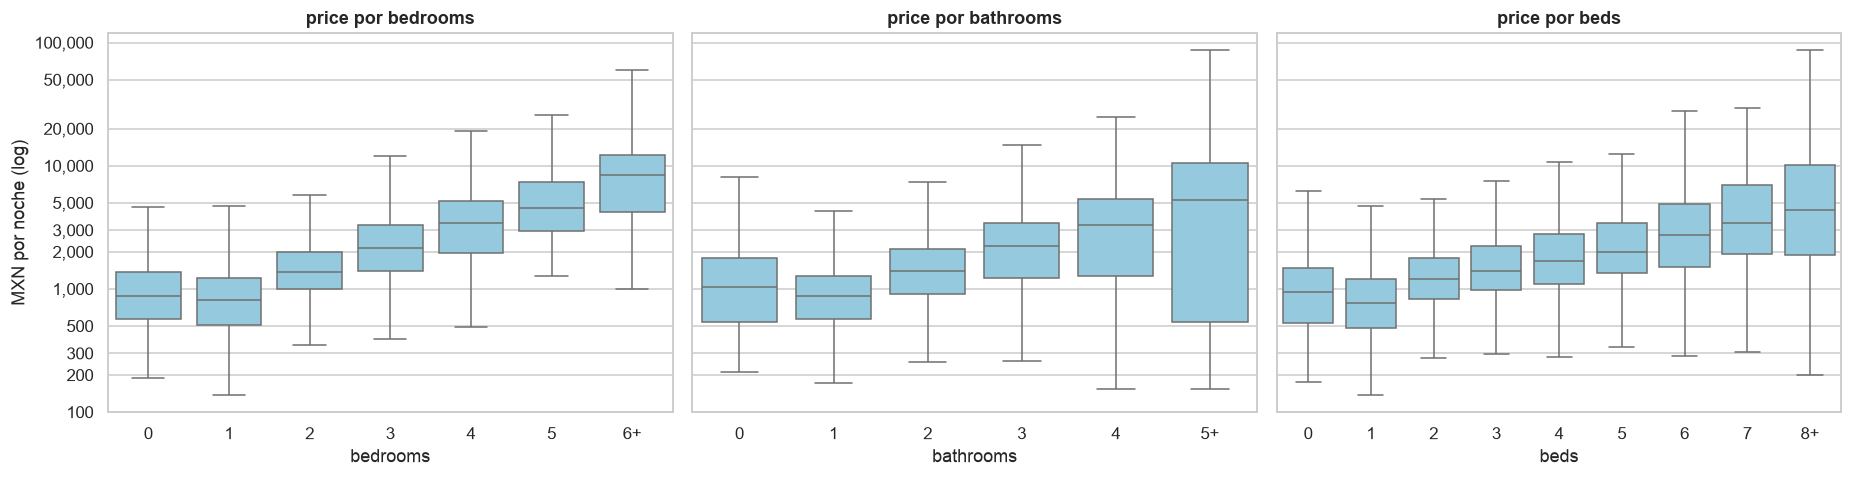

bedrooms   -> anuncios con 0:  470 | Spearman con price: 0.48
bathrooms  -> anuncios con 0:  124 | Spearman con price: 0.35
beds       -> anuncios con 0:  361 | Spearman con price: 0.44


In [110]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharey=True)
for ax, col, tope in zip(axes, ["bedrooms", "bathrooms", "beds"], [6, 5, 8]):
    datos = df_p[df_p[col].notna()].copy()
    datos[col + "_g"] = datos[col].clip(upper=tope).astype(int).astype(str).replace({str(tope): f"{tope}+"})
    orden = sorted(datos[col + "_g"].unique(), key=lambda s: int(s.rstrip("+")))
    sns.boxplot(data=datos, x=col + "_g", y="price", order=orden, color=AZUL_CLARO, log_scale=True,
                showfliers=False, ax=ax)
    ax.set_title(f"price por {col}"); ax.set_xlabel(col); ax.set_ylabel("MXN por noche (log)")
    eje_log_plano(ax)
fig.tight_layout()
guardar(fig, "08_habitaciones_banos_camas.png")
plt.show()
for col in ["bedrooms", "bathrooms", "beds"]:
    print(f"{col:10s} -> anuncios con 0: {(df_p[col] == 0).sum():4d} | Spearman con price: "
          f"{stats.spearmanr(df_p[col], df_p['price'], nan_policy='omit').statistic:.2f}")

**i. Tipo de gráfico y observaciones.** Tres boxplots en escala log con eje Y compartido, uno por variable de espacio. Las colas se agruparon (6+ recámaras, 5+ baños, 8+ camas) para no dibujar cajas con muy pocos anuncios. El precio sube con cada recámara: \$809 (1), \$1,376 (2), \$2,139 (3), \$3,400 (4), \$4,500 (5) y \$8,445 (6+). Con los baños el patrón es parecido (\$879 con 1 baño, \$1,408 con 2, \$2,230 con 3) y con las camas es más suave (\$763 con 1 cama, \$1,205 con 2). Las correlaciones de Spearman con el precio son 0.48 (recámaras), 0.44 (camas) y 0.35 (baños).

**ii. Valores atípicos o anomalías.** Hay 470 anuncios con 0 recámaras cuya mediana (\$882) es similar a la de 1 recámara: no es un error, son estudios o lofts. Los 124 anuncios con 0 baños y 361 con 0 camas sí son sospechosos de captura incompleta. El grupo de 5+ baños tiene una caja enorme que probablemente mezcla casas de lujo con hostales o casas de huéspedes con muchos baños compartidos.

**iii. Tendencias, patrones o agrupaciones.** Las tres relaciones son positivas y monótonas a partir de 1, pero el número de recámaras es el que mejor separa los niveles de precio (cajas casi sin traslape a partir de 3).

**iv. Comparaciones entre grupos.** Comparando las tres variables, recámaras discrimina mejor que baños o camas: el número de camas puede aumentar con sofás cama o literas sin que el espacio cambie.

**Implicaciones para el proyecto.** Estas variables están muy correlacionadas entre sí y con `accommodates` (Spearman 0.74–0.80), lo que generaría multicolinealidad en un modelo lineal. Conviene elegir una o dos (accommodates y bedrooms) o combinarlas en un índice de tamaño.

#### Figura 9. Matrices de correlación de Pearson y de Spearman

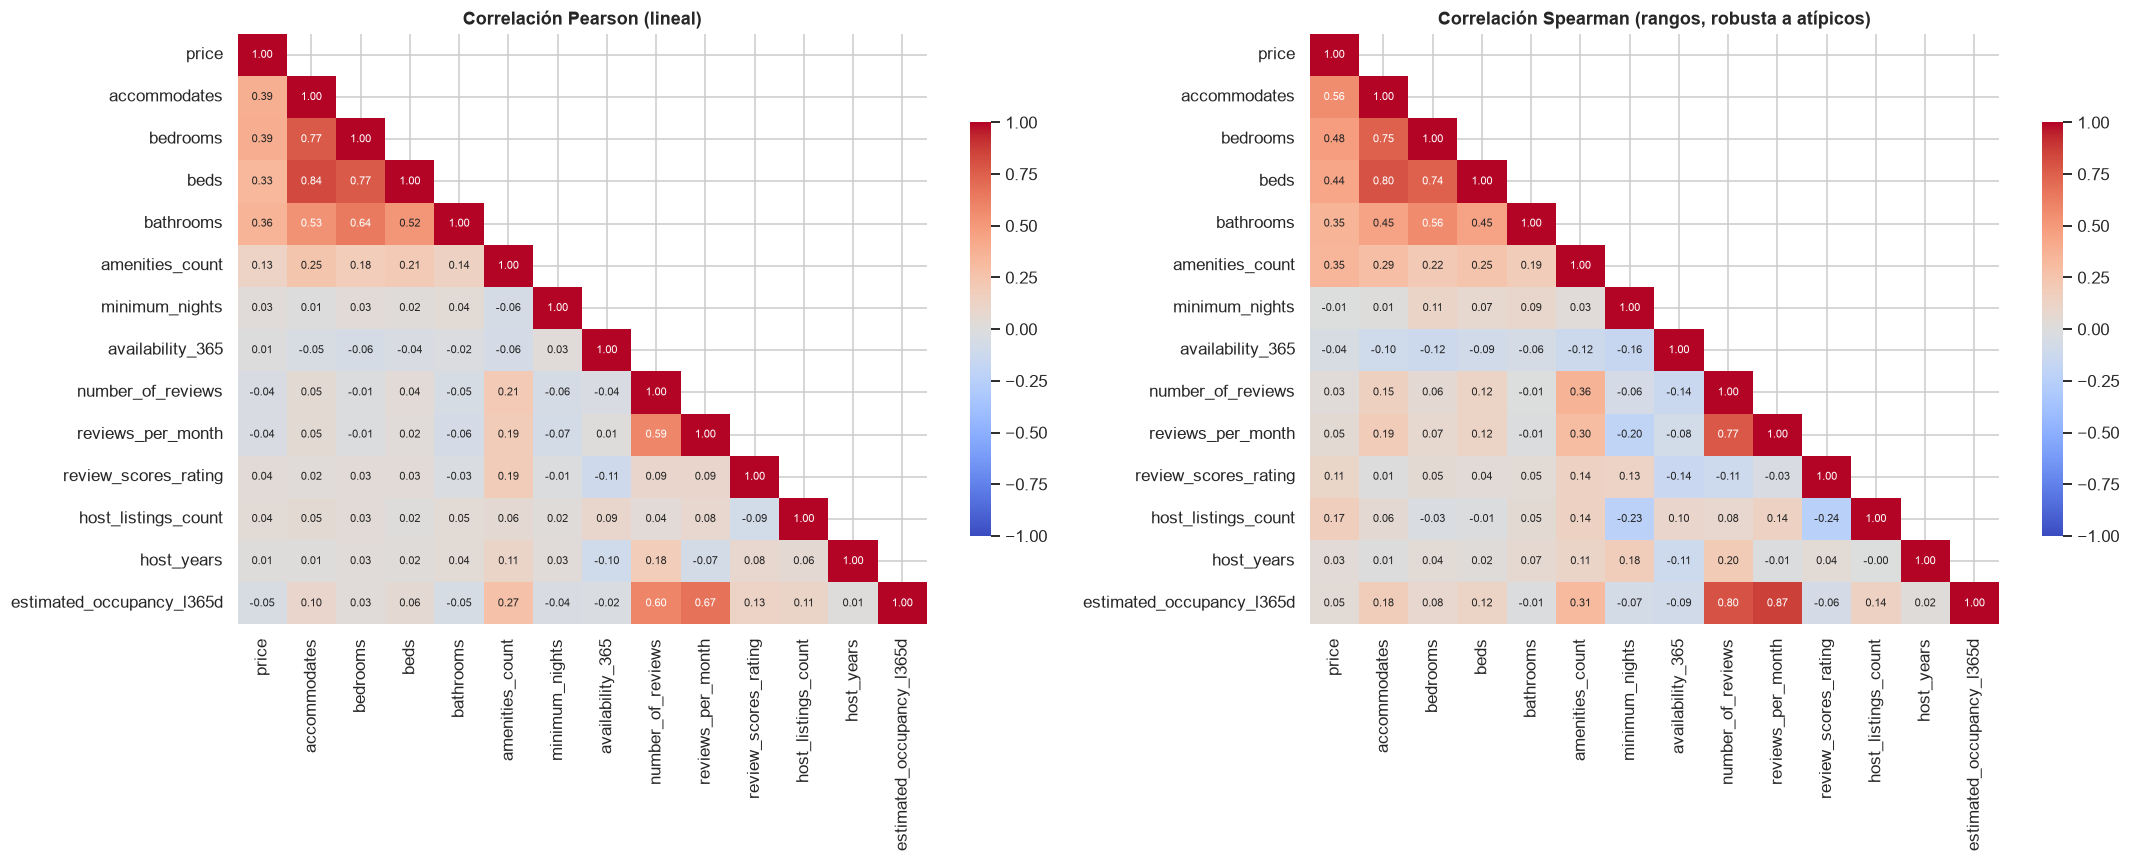

,pearson,spearman
accommodates,0.39,0.56
bedrooms,0.39,0.48
beds,0.33,0.44
bathrooms,0.36,0.35
amenities_count,0.13,0.35
host_listings_count,0.04,0.17
review_scores_rating,0.04,0.11
reviews_per_month,-0.04,0.05
estimated_occupancy_l365d,-0.05,0.05
host_years,0.01,0.03


In [111]:
cols_corr = ["price", "accommodates", "bedrooms", "beds", "bathrooms", "amenities_count",
             "minimum_nights", "availability_365", "number_of_reviews", "reviews_per_month",
             "review_scores_rating", "host_listings_count", "host_years", "estimated_occupancy_l365d"]
pearson = df_p[cols_corr].corr(method="pearson")
spearman = df_p[cols_corr].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(20, 8))
mascara = np.triu(np.ones_like(spearman, dtype=bool), k=1)
for ax, m, t in zip(axes, [pearson, spearman], ["Pearson (lineal)", "Spearman (rangos, robusta a atípicos)"]):
    sns.heatmap(m, mask=mascara, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
                annot_kws={"size": 7.5}, cbar_kws={"shrink": 0.7}, ax=ax)
    ax.set_title(f"Correlación {t}")
fig.tight_layout()
guardar(fig, "09_correlaciones.png")
plt.show()

comp_corr = pd.DataFrame({"pearson": pearson["price"], "spearman": spearman["price"]}).drop("price")
comp_corr.sort_values("spearman", ascending=False).round(2)

**i. Tipo de gráfico y observaciones.** Mapas de calor triangulares con la correlación anotada: son la forma estándar de revisar de un vistazo las relaciones lineales entre muchas variables. Se presentan dos métodos lado a lado porque Pearson mide relación lineal y es sensible a atípicos, mientras que Spearman trabaja con rangos y capta relaciones monótonas aunque no sean lineales. Con Spearman, las variables más asociadas al precio son accommodates (0.56), bedrooms (0.48), beds (0.44), amenities_count (0.35) y bathrooms (0.35). Las variables de demanda y reputación (número de reseñas, ocupación, disponibilidad, calificación) tienen correlaciones cercanas a cero (−0.04 a 0.11).

**ii. Valores atípicos o anomalías.** La diferencia entre ambos métodos es en sí una evidencia del efecto de los atípicos: `amenities_count` pasa de 0.13 con Pearson a 0.35 con Spearman y `accommodates` de 0.39 a 0.56. Los precios extremos debilitan la correlación lineal; si solo se mirara Pearson se subestimaría la importancia de estas variables.

**iii. Tendencias, patrones o agrupaciones.** Se distinguen dos bloques de variables: un bloque de tamaño (accommodates, bedrooms, beds, bathrooms, entre 0.45 y 0.80) y un bloque de demanda (number_of_reviews, reviews_per_month y estimated_occupancy_l365d, entre 0.77 y 0.87). Los dos bloques casi no se relacionan entre sí.

**iv. Comparaciones entre grupos.** El bloque de tamaño se asocia con el precio; el de demanda, no. Es decir, en este mercado un anuncio más caro no es necesariamente más o menos demandado: precio y ocupación responden a factores distintos.

**Implicaciones para el proyecto.** Para el modelo de precio las variables de tamaño, ubicación y equipamiento son las candidatas principales; dentro del bloque de tamaño hay que controlar la multicolinealidad. Las variables de demanda podrían ser objetivo de un análisis distinto (predecir ocupación).

#### Figura 10. Cantidad de amenities y precio

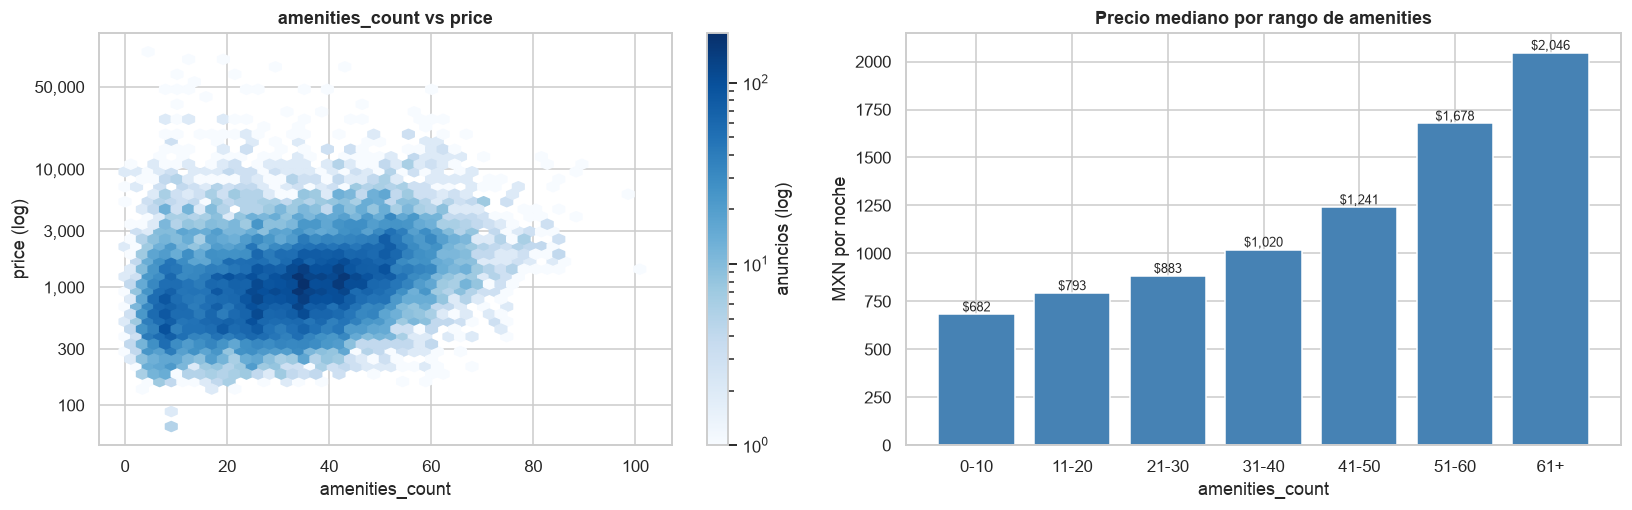

amen_bin,0-10,11-20,21-30,31-40,41-50,51-60,61+
anuncios,"2,346.00","3,175.00","4,591.00","5,657.00","4,401.00","2,128.00",759.00
mediana,682.00,793.00,883.00,"1,020.00","1,241.00","1,678.00","2,046.00"


In [112]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
hb = axes[0].hexbin(df_p["amenities_count"], df_p["log_price"], gridsize=45, cmap="Blues", mincnt=1, bins="log")
fig.colorbar(hb, ax=axes[0], label="anuncios (log)")
axes[0].set_yticks(np.log10([100, 300, 1000, 3000, 10000, 50000]))
axes[0].set_yticklabels(["100", "300", "1,000", "3,000", "10,000", "50,000"])
axes[0].set_title("amenities_count vs price"); axes[0].set_xlabel("amenities_count"); axes[0].set_ylabel("price (log)")

df_p["amen_bin"] = pd.cut(df_p["amenities_count"], bins=[-1, 10, 20, 30, 40, 50, 60, 110],
                          labels=["0-10", "11-20", "21-30", "31-40", "41-50", "51-60", "61+"])
med_amen = df_p.groupby("amen_bin", observed=True)["price"].median()
axes[1].bar(med_amen.index.astype(str), med_amen.values, color=AZUL)
for x, v in enumerate(med_amen.values):
    axes[1].text(x, v + 15, f"${v:,.0f}", ha="center", fontsize=8.5)
axes[1].set_title("Precio mediano por rango de amenities"); axes[1].set_xlabel("amenities_count"); axes[1].set_ylabel("MXN por noche")
fig.tight_layout()
guardar(fig, "10_amenities_precio.png")
plt.show()
display(df_p.groupby("amen_bin", observed=True)["price"].agg(anuncios="count", mediana="median").T.round(0))

**i. Tipo de gráfico y observaciones.** Un hexbin de `amenities_count` contra el precio (log), que evita la saturación de un gráfico de dispersión con 23,000 puntos, y barras con el precio mediano por rango de amenities, que resumen la tendencia de forma más directa. El precio mediano aumenta en todos los rangos: \$682 con 0–10 amenities, \$883 con 21–30, \$1,241 con 41–50 y \$2,046 con más de 60, es decir, se triplica de un extremo al otro. La mayor parte de los anuncios declara entre 20 y 50 amenities.

**ii. Valores atípicos o anomalías.** Hay anuncios con muy pocos amenities (0–5) y precios altos, que probablemente son anuncios con la ficha incompleta más que alojamientos sin equipamiento. Los anuncios con más de 80 amenities son muy pocos y dispersos.

**iii. Tendencias, patrones o agrupaciones.** Relación positiva y cada vez más pronunciada: el salto de precio es mayor a partir de 40 amenities, donde aparecen servicios de gama alta.

**iv. Comparaciones entre grupos.** El hexbin muestra que, para una misma cantidad de amenities, el precio varía casi un orden de magnitud; el pairplot (figura 21) confirma que los espacios completos declaran más amenities que las habitaciones, de modo que parte de este efecto es en realidad el efecto del tipo de alojamiento.

**Implicaciones para el proyecto.** `amenities_count` es un buen candidato para el modelo, pero su efecto debe evaluarse controlando por room_type y tamaño para no atribuirle al equipamiento lo que se debe al tipo de espacio.

#### Figura 11. Diferencia de precio asociada a cada amenity del top 10

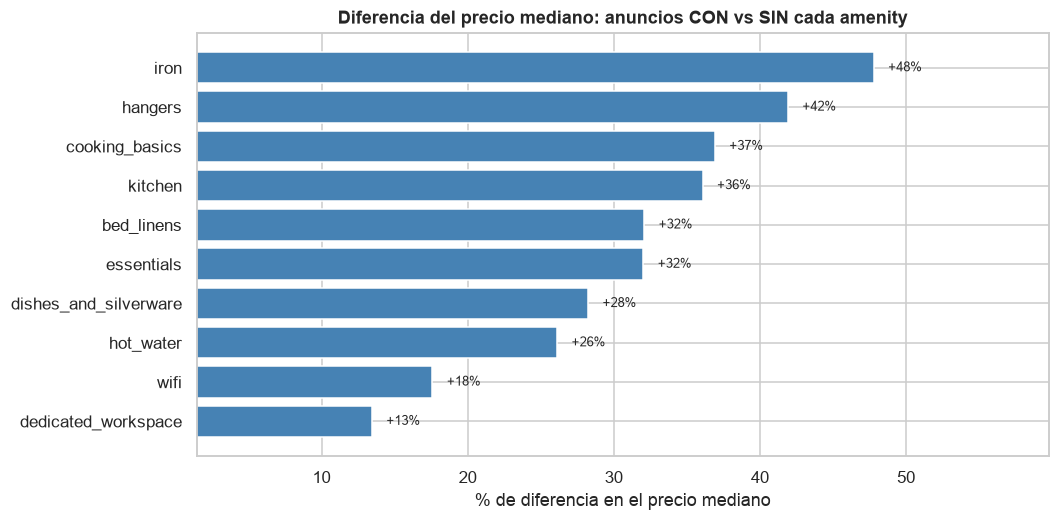

,con,sin,% anuncios con,diferencia %
dedicated_workspace,"1,080.00",952.00,69.10,13.40
wifi,"1,043.00",887.00,96.90,17.60
hot_water,"1,072.00",850.00,83.00,26.10
dishes_and_silverware,"1,090.00",850.00,74.90,28.20
essentials,"1,105.00",837.00,74.60,32.00
bed_linens,"1,124.00",851.00,68.80,32.10
kitchen,"1,075.00",790.00,87.30,36.10
cooking_basics,"1,109.00",810.00,74.70,36.90
hangers,"1,114.00",785.00,76.60,41.90
iron,"1,133.50",767.00,73.70,47.80


In [113]:
cols_amen = sorted(c for c in df_p.columns if c.startswith("amen_") and c != "amen_bin")
prima = pd.DataFrame({
    "con": [df_p.loc[df_p[c] == 1, "price"].median() for c in cols_amen],
    "sin": [df_p.loc[df_p[c] == 0, "price"].median() for c in cols_amen],
    "% anuncios con": [df_p[c].mean() * 100 for c in cols_amen],
}, index=[c.replace("amen_", "") for c in cols_amen])
prima["diferencia %"] = (prima["con"] / prima["sin"] - 1) * 100
prima = prima.sort_values("diferencia %")

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(prima.index, prima["diferencia %"], color=[ACENTO if v < 0 else AZUL for v in prima["diferencia %"]])
for y, v in enumerate(prima["diferencia %"]):
    ax.text(v + (1 if v >= 0 else -1), y, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8.5)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Diferencia del precio mediano: anuncios CON vs SIN cada amenity")
ax.set_xlabel("% de diferencia en el precio mediano")
ax.set_xlim(prima["diferencia %"].min() - 12, prima["diferencia %"].max() + 12)
guardar(fig, "11_prima_amenities.png")
plt.show()
prima.round(1)

**i. Tipo de gráfico y observaciones.** Barras horizontales divergentes con la diferencia porcentual entre el precio mediano de los anuncios que ofrecen cada amenity y los que no. Las barras divergentes muestran de inmediato el signo y la magnitud de la diferencia, y se ordenan para comparar amenities entre sí. Todos los amenities del top 10 se asocian con un precio mayor: iron (+48%), hangers (+42%), cooking basics (+37%) y kitchen (+36%) encabezan la lista; wifi (+18%) y dedicated workspace (+13%) son los de menor diferencia.

**ii. Valores atípicos o anomalías.** La primera versión de esta gráfica mostraba a wifi con −6%, un resultado sin sentido de negocio. Al investigar la anomalía se encontró que la binaria de la entrega 1 solo reconocía el texto exacto `wifi`, y 2,477 anuncios lo declaraban como `fast wifi – XX mbps`. Tras corregirlo (sección 1.2) la diferencia pasó a +18%. Aun así, solo el 3.1% de los anuncios no tiene wifi, por lo que su grupo de comparación es pequeño.

**iii. Tendencias, patrones o agrupaciones.** Los amenities con mayor diferencia son servicios básicos de una vivienda completa (plancha, ganchos, cocina), lo que indica que funcionan como señal de "alojamiento completo y equipado" más que como un lujo que se cobre por separado.

**iv. Comparaciones entre grupos.** La comparación con/sin está afectada por el tipo de alojamiento: las habitaciones privadas, más baratas, suelen no ofrecer cocina ni utensilios. Por eso la diferencia no debe leerse como lo que un anfitrión ganaría al agregar ese amenity.

**Implicaciones para el proyecto.** Las binarias de amenities aportan información, pero son asociaciones y no efectos causales. El hallazgo de wifi muestra además que la limpieza es un proceso continuo: un error de codificación invirtió una conclusión.

#### Figura 12. Calificaciones de los huéspedes

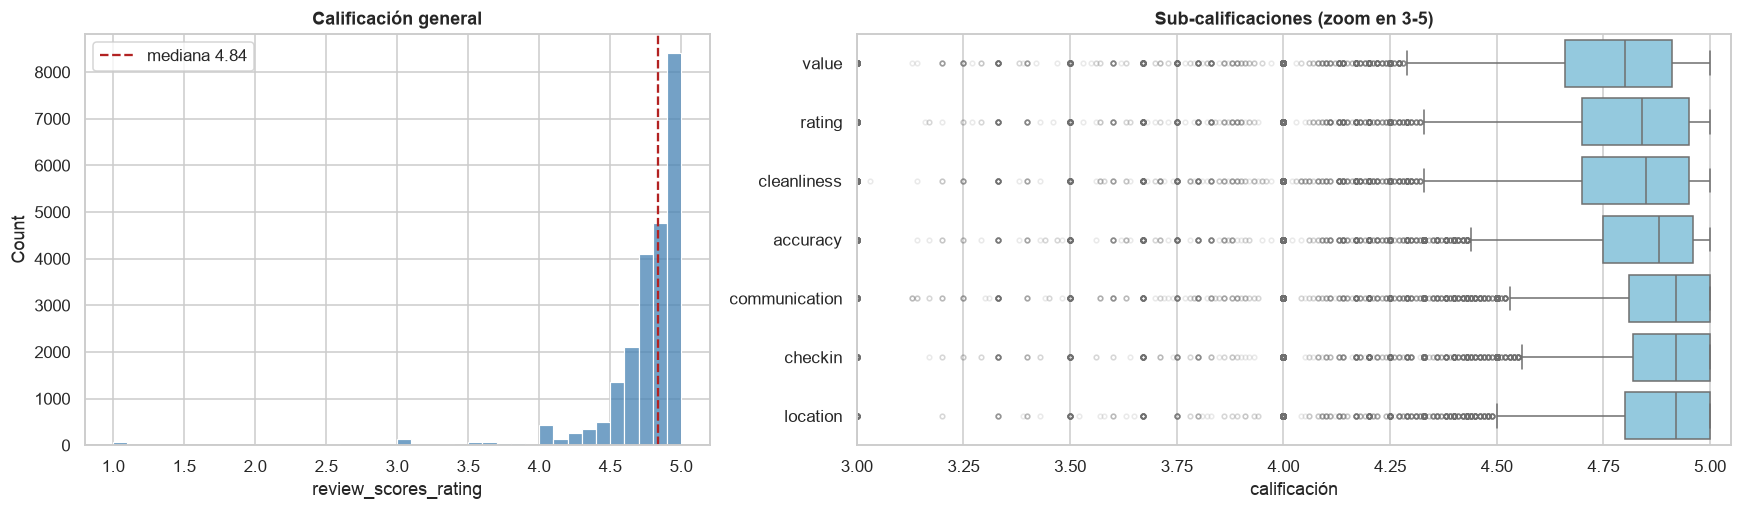

Anuncios con reseñas: 22,987 | rating >= 4.5: 90.2% | rating < 4: 2.5%


,mean,median,std
review_scores_rating,4.75,4.84,0.38
review_scores_accuracy,4.78,4.88,0.37
review_scores_cleanliness,4.75,4.85,0.38
review_scores_checkin,4.84,4.92,0.32
review_scores_communication,4.82,4.92,0.36
review_scores_location,4.84,4.92,0.29
review_scores_value,4.71,4.80,0.39


In [114]:
subscores = ["review_scores_rating", "review_scores_accuracy", "review_scores_cleanliness",
             "review_scores_checkin", "review_scores_communication", "review_scores_location", "review_scores_value"]
con_reviews = df[df["number_of_reviews"] > 0]

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.4]})
sns.histplot(con_reviews["review_scores_rating"], bins=40, color=AZUL, ax=axes[0])
axes[0].axvline(con_reviews["review_scores_rating"].median(), color=ACENTO, ls="--",
                label=f"mediana {con_reviews['review_scores_rating'].median():.2f}")
axes[0].set_title("Calificación general"); axes[0].legend(); axes[0].set_xlabel("review_scores_rating")

largo = con_reviews[subscores].melt(var_name="dimensión", value_name="calificación")
largo["dimensión"] = largo["dimensión"].str.replace("review_scores_", "")
orden_sub = largo.groupby("dimensión")["calificación"].mean().sort_values().index
sns.boxplot(data=largo, x="calificación", y="dimensión", order=orden_sub, color=AZUL_CLARO,
            flierprops={"marker": ".", "alpha": 0.15}, ax=axes[1])
axes[1].set_xlim(3, 5.05); axes[1].set_title("Sub-calificaciones (zoom en 3-5)"); axes[1].set_ylabel("")
fig.tight_layout()
guardar(fig, "12_calificaciones.png")
plt.show()

r = con_reviews["review_scores_rating"]
print(f"Anuncios con reseñas: {len(con_reviews):,} | rating >= 4.5: {(r >= 4.5).mean():.1%} | rating < 4: {(r < 4).mean():.1%}")
display(con_reviews[subscores].agg(["mean", "median", "std"]).T.round(3))

**i. Tipo de gráfico y observaciones.** Un histograma de la calificación general y boxplots horizontales de las siete sub-calificaciones con zoom entre 3 y 5, porque casi todos los valores están en ese rango y a escala completa las cajas se verían como líneas. La mediana es 4.84 y el 90.2% de los anuncios con reseñas tiene 4.5 o más; solo el 2.5% está por debajo de 4. El 16.5% tiene exactamente 5.0. Entre las sub-calificaciones, value (relación calidad-precio, mediana 4.80) y cleanliness (4.85) son las más bajas, y check-in, communication y location (4.92) las más altas.

**ii. Valores atípicos o anomalías.** Hay acumulaciones en 1.0, 3.0 y 4.0 (75 anuncios con 1.0): son anuncios con una o muy pocas reseñas, donde una sola opinión define el promedio. Estos valores tiran la media hacia abajo (asimetría −5.23) y pueden hacer parecer malo un anuncio que simplemente tiene poco historial.

**iii. Tendencias, patrones o agrupaciones.** Se observa un efecto techo: las calificaciones están comprimidas cerca de 5, de modo que la escala de 1 a 5 en la práctica funciona entre 4.5 y 5.

**iv. Comparaciones entre grupos.** Los huéspedes son más exigentes con la relación calidad-precio y la limpieza que con la ubicación o la comunicación; para un anfitrión, esas dos dimensiones son las que más margen de mejora tienen.

**Implicaciones para el proyecto.** Por la poca variabilidad, la calificación discrimina mal entre anuncios (correlación con el precio de 0.11). Si se usa, conviene transformarla en percentiles o en una calificación ajustada por número de reseñas.

#### Figura 13. Número de reseñas y confiabilidad de la calificación

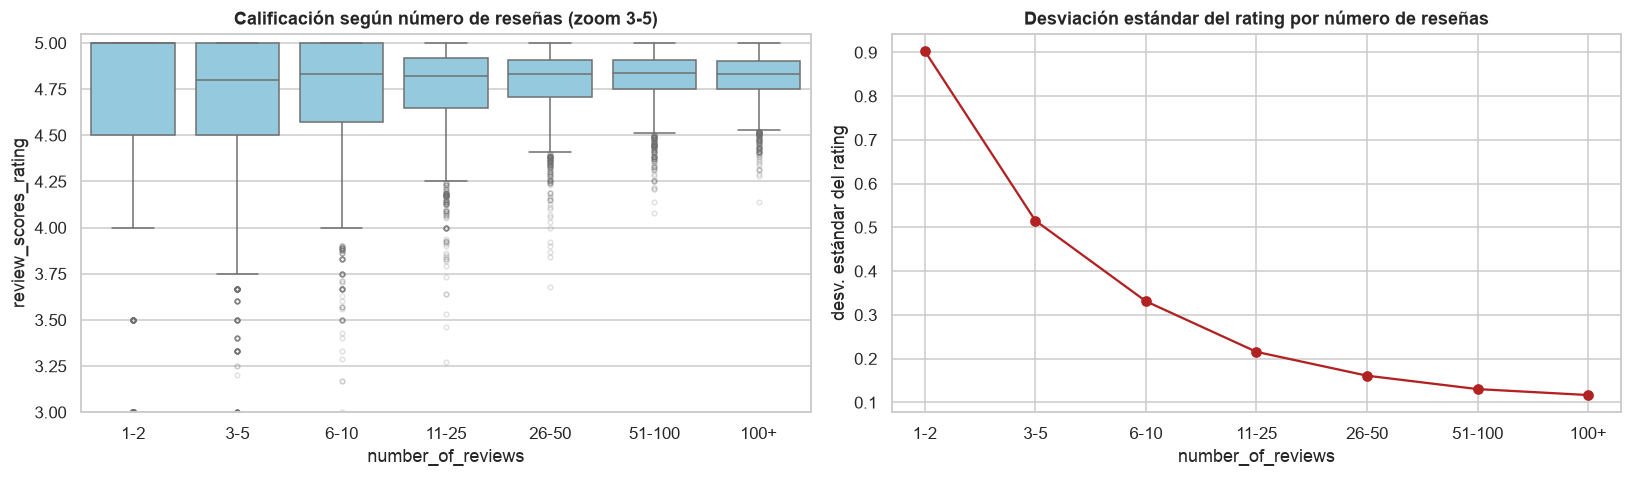

reviews_bin,1-2,3-5,6-10,11-25,26-50,51-100,100+
std,0.90,0.52,0.33,0.22,0.16,0.13,0.12
median,5.00,4.80,4.83,4.82,4.83,4.84,4.83
count,"1,924.00","1,749.00","1,947.00","3,662.00","3,526.00","3,612.00","4,159.00"


In [115]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
datos = df_p[(df_p["number_of_reviews"] > 0) & df_p["review_scores_rating"].notna()]
datos = datos.assign(reviews_bin=pd.cut(datos["number_of_reviews"], [0, 2, 5, 10, 25, 50, 100, 2000],
                                        labels=["1-2", "3-5", "6-10", "11-25", "26-50", "51-100", "100+"]))
sns.boxplot(data=datos, x="reviews_bin", y="review_scores_rating", color=AZUL_CLARO,
            flierprops={"marker": ".", "alpha": 0.2}, ax=axes[0])
axes[0].set_ylim(3, 5.05)
axes[0].set_title("Calificación según número de reseñas (zoom 3-5)")
axes[0].set_xlabel("number_of_reviews"); axes[0].set_ylabel("review_scores_rating")

dispersion = datos.groupby("reviews_bin", observed=True)["review_scores_rating"].agg(["std", "median", "count"])
axes[1].plot(dispersion.index.astype(str), dispersion["std"], marker="o", color=ACENTO)
axes[1].set_title("Desviación estándar del rating por número de reseñas")
axes[1].set_xlabel("number_of_reviews"); axes[1].set_ylabel("desv. estándar del rating")
fig.tight_layout()
guardar(fig, "13_reviews_vs_rating.png")
plt.show()
dispersion.round(3).T

**i. Tipo de gráfico y observaciones.** Boxplots de la calificación por rangos de número de reseñas y una línea con la desviación estándar de cada rango. Los rangos convierten una variable muy asimétrica en grupos comparables y la línea resume cómo cambia la dispersión. La desviación estándar de la calificación cae de 0.90 (1–2 reseñas) a 0.12 (más de 100). Los anuncios con 1–2 reseñas tienen mediana de 5.00 (el 71% tiene calificación perfecta), mientras que a partir de 6 reseñas la mediana se estabiliza en 4.82–4.84.

**ii. Valores atípicos o anomalías.** Los valores extremos bajos (1 a 3.5) aparecen casi solo en los grupos con pocas reseñas; en anuncios con más de 50 reseñas prácticamente no hay calificaciones menores a 4.

**iii. Tendencias, patrones o agrupaciones.** El gráfico tiene forma de embudo: con más reseñas la calificación converge hacia el valor típico del mercado, como predice la ley de los grandes números.

**iv. Comparaciones entre grupos.** Comparar un anuncio con 2 reseñas y 5.0 contra uno con 200 reseñas y 4.8 es engañoso: el segundo tiene una reputación mucho más sólida aunque su promedio sea menor.

**Implicaciones para el proyecto.** Las calificaciones con menos de unas 10 reseñas no son confiables; para usarlas en un modelo se recomienda un promedio bayesiano (que acerca a la media del mercado los anuncios con pocas reseñas) o ponderar por el número de reseñas.

#### Figura 14. Superhost frente a no superhost

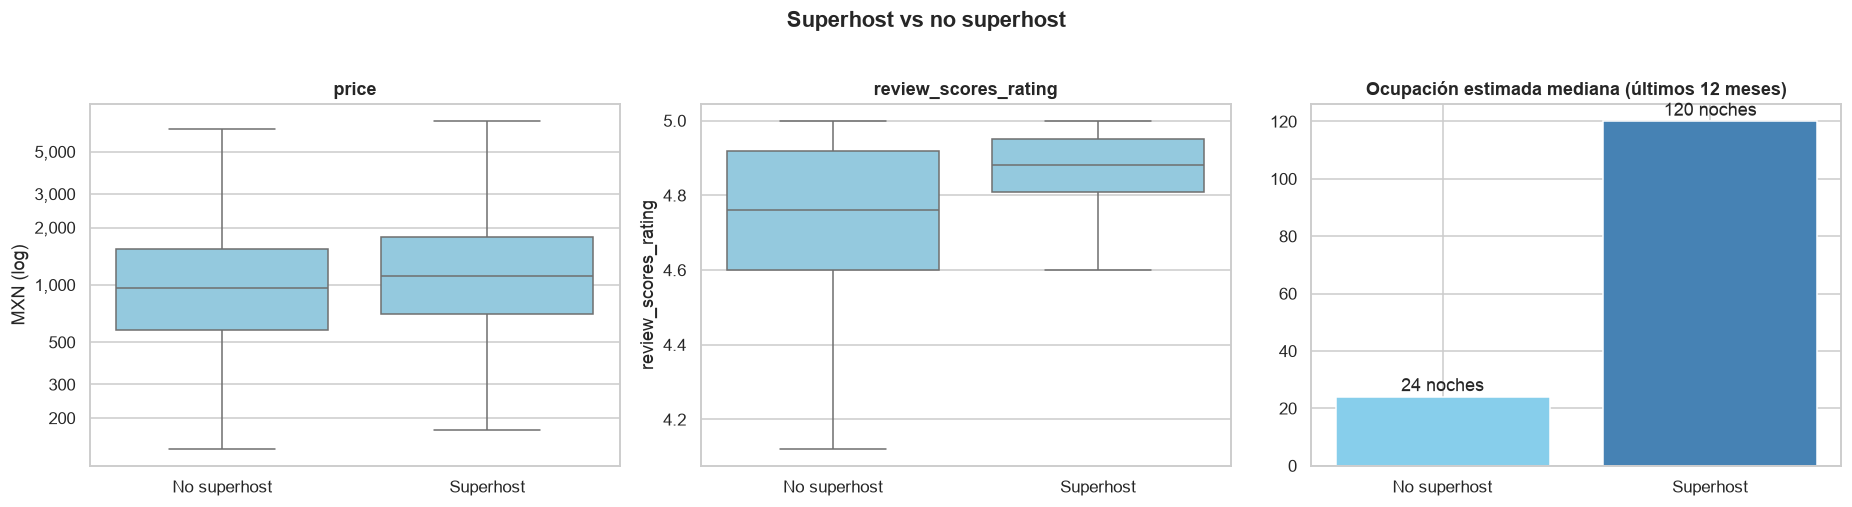

,anuncios,precio_mediano,rating_mediano,reviews_medianas,ocupacion_mediana,ingreso_mediano
superhost,,,,,,
No superhost,12670,963.00,4.76,11.00,24.00,"20,820.00"
Superhost,9169,"1,115.00",4.88,47.00,120.00,"120,360.00"


Mann-Whitney price superhost vs no superhost: p < 0.001


In [116]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
grupo = df_p.assign(superhost=df_p["host_is_superhost"].map({True: "Superhost", False: "No superhost"})).dropna(subset=["superhost"])

sns.boxplot(data=grupo, x="superhost", y="price", color=AZUL_CLARO, log_scale=True, showfliers=False, ax=axes[0])
axes[0].set_title("price"); axes[0].set_xlabel(""); axes[0].set_ylabel("MXN (log)"); eje_log_plano(axes[0])
sns.boxplot(data=grupo, x="superhost", y="review_scores_rating", color=AZUL_CLARO, showfliers=False, ax=axes[1])
axes[1].set_title("review_scores_rating"); axes[1].set_xlabel("")
ocup = grupo.groupby("superhost")["estimated_occupancy_l365d"].median()
axes[2].bar(ocup.index, ocup.values, color=[AZUL_CLARO, AZUL])
for x, v in enumerate(ocup.values):
    axes[2].text(x, v + 2, f"{v:.0f} noches", ha="center")
axes[2].set_title("Ocupación estimada mediana (últimos 12 meses)")
fig.suptitle("Superhost vs no superhost", y=1.02, fontweight="bold")
fig.tight_layout()
guardar(fig, "14_superhost.png")
plt.show()

tabla_sh = grupo.groupby("superhost").agg(
    anuncios=("id", "count"), precio_mediano=("price", "median"), rating_mediano=("review_scores_rating", "median"),
    reviews_medianas=("number_of_reviews", "median"), ocupacion_mediana=("estimated_occupancy_l365d", "median"),
    ingreso_mediano=("estimated_revenue_l365d", "median"))
display(tabla_sh.round(2))
u = stats.mannwhitneyu(grupo.loc[grupo["superhost"] == "Superhost", "price"],
                       grupo.loc[grupo["superhost"] == "No superhost", "price"])
print(f"Mann-Whitney price superhost vs no superhost: p {'< 0.001' if u.pvalue < 0.001 else f'= {u.pvalue:.3f}'}")

**i. Tipo de gráfico y observaciones.** Dos boxplots (precio en log y calificación) y una barra de ocupación mediana para comparar dos grupos en tres dimensiones distintas: tarifa, reputación y demanda. Los superhost (38.8% de los anuncios) cobran una mediana de \$1,115 frente a \$963 (+16%) y tienen mejor calificación (4.88 vs. 4.76). La diferencia grande está en la demanda: 120 noches de ocupación estimada frente a 24 y un ingreso anual mediano de \$120,360 frente a \$20,820 (5.8 veces). Mann-Whitney para el precio: p < 0.001.

**ii. Valores atípicos o anomalías.** El grupo no superhost tiene una distribución de calificaciones mucho más amplia (bigote inferior cerca de 4.1), porque incluye anuncios nuevos o inactivos con pocas reseñas.

**iii. Tendencias, patrones o agrupaciones.** El estatus de superhost se asocia más con actividad que con precio: los superhost tienen 4 veces más reseñas en mediana (47 vs. 11).

**iv. Comparaciones entre grupos.** La diferencia de precio entre grupos es modesta y estadísticamente significativa, pero la de ocupación es cinco veces mayor. La comparación también tiene causalidad inversa: para ser superhost se necesita haber recibido estancias, así que la ocupación alta es en parte requisito y no solo consecuencia.

**Implicaciones para el proyecto.** `host_is_superhost` aporta poco para predecir el precio, pero mucho para explicar ocupación e ingresos; es útil si más adelante el proyecto busca recomendar estrategias a los anfitriones.

#### Figura 15. Tipos de anfitrión y concentración de la oferta

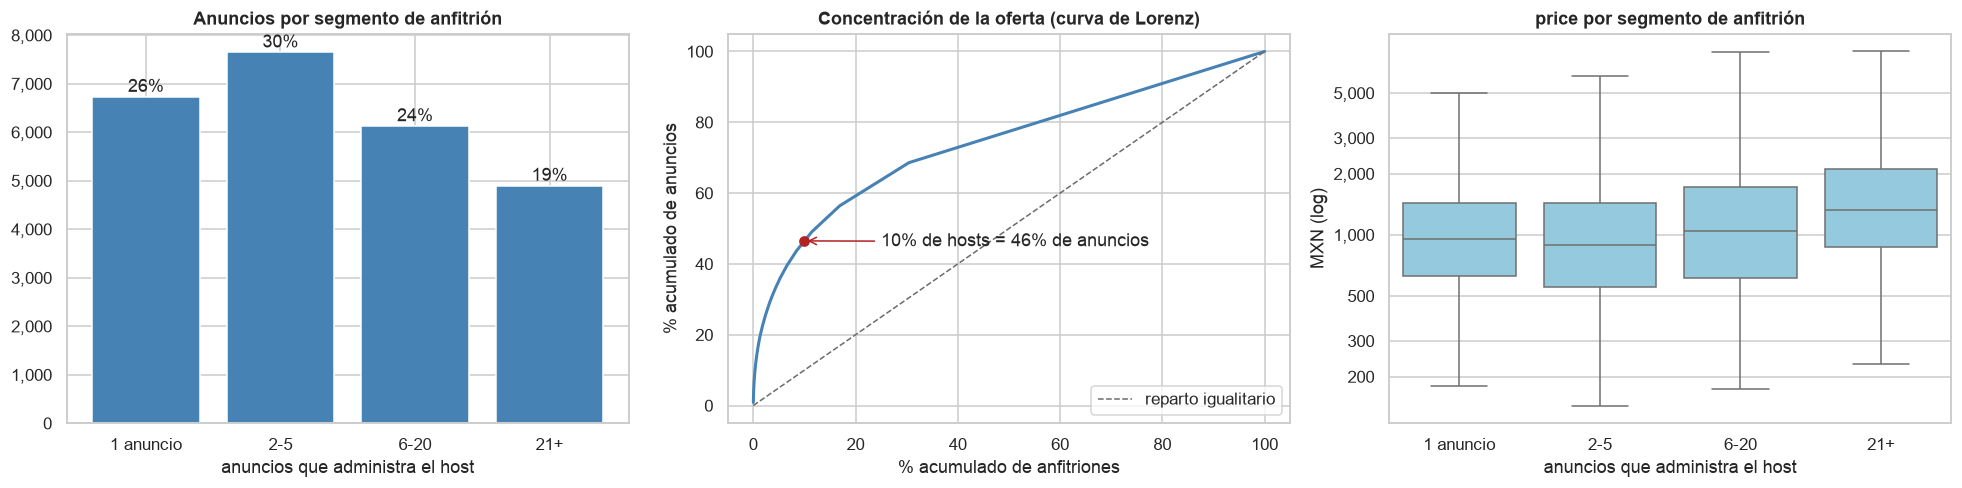

Anfitriones: 11,882 | con 1 solo anuncio en el dataset: 69.6% | Gini: 0.48


,anuncios,precio_mediano,rating_mediano,superhost_pct,entire_home_pct
host_segment,,,,,
1 anuncio,5317,952.00,4.89,0.33,0.71
2-5,6717,893.00,4.86,0.47,0.62
6-20,5550,"1,048.00",4.81,0.46,0.63
21+,4587,"1,322.00",4.77,0.40,0.76


In [117]:
hosts = df.drop_duplicates("host_id")[["host_id", "host_listings_count"]].dropna()
anuncios_por_host = df.groupby("host_id").size().sort_values(ascending=False)
curva = anuncios_por_host.cumsum() / anuncios_por_host.sum()
x_pct = np.arange(1, len(curva) + 1) / len(curva)

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
seg = df["host_segment"].value_counts().reindex(["1 anuncio", "2-5", "6-20", "21+"])
axes[0].bar(seg.index.astype(str), seg.values, color=AZUL)
for x, v in enumerate(seg.values):
    axes[0].text(x, v + 100, f"{v / seg.sum():.0%}", ha="center")
axes[0].set_title("Anuncios por segmento de anfitrión"); axes[0].set_xlabel("anuncios que administra el host"); fmt_miles(axes[0])

axes[1].plot(x_pct * 100, curva.values * 100, color=AZUL, lw=2)
axes[1].plot([0, 100], [0, 100], color=GRIS, ls="--", lw=1, label="reparto igualitario")
top10 = curva.iloc[int(len(curva) * 0.10) - 1]
axes[1].scatter([10], [top10 * 100], color=ACENTO, zorder=3)
axes[1].annotate(f"10% de hosts = {top10:.0%} de anuncios", (10, top10 * 100), xytext=(25, 45),
                 arrowprops={"arrowstyle": "->", "color": ACENTO})
axes[1].set_title("Concentración de la oferta (curva de Lorenz)")
axes[1].set_xlabel("% acumulado de anfitriones"); axes[1].set_ylabel("% acumulado de anuncios"); axes[1].legend(loc="lower right")

sns.boxplot(data=df_p.dropna(subset=["host_segment"]), x="host_segment", y="price", color=AZUL_CLARO,
            log_scale=True, showfliers=False, ax=axes[2])
axes[2].set_title("price por segmento de anfitrión"); axes[2].set_xlabel("anuncios que administra el host"); axes[2].set_ylabel("MXN (log)")
eje_log_plano(axes[2])
fig.tight_layout()
guardar(fig, "15_anfitriones_concentracion.png")
plt.show()

n = len(anuncios_por_host)
gini = 1 - 2 * np.trapezoid(np.r_[0, np.sort(anuncios_por_host.values).cumsum() / anuncios_por_host.sum()], dx=1 / n)
print(f"Anfitriones: {n:,} | con 1 solo anuncio en el dataset: {(anuncios_por_host == 1).mean():.1%} | Gini: {gini:.2f}")
display(df_p.groupby("host_segment", observed=True).agg(anuncios=("id", "count"), precio_mediano=("price", "median"),
        rating_mediano=("review_scores_rating", "median"), superhost_pct=("host_is_superhost", "mean"),
        entire_home_pct=("room_type", lambda s: (s == "Entire home/apt").mean())).round(2))

**i. Tipo de gráfico y observaciones.** Barras con los anuncios por segmento de anfitrión, una curva de Lorenz (estándar para medir concentración) y boxplots del precio por segmento. Los segmentos se definen con `host_listings_count`, el total de anuncios que el anfitrión administra en Airbnb. Los anuncios se reparten así: 1 anuncio 26%, 2–5 30%, 6–20 24% y 21 o más 19%. La curva de Lorenz muestra que el 10% de los anfitriones controla el 46% de los anuncios (índice de Gini 0.48) y que el 69.6% de los anfitriones tiene un solo anuncio en el dataset. El precio mediano sube en los segmentos profesionales: \$952 (1 anuncio) frente a \$1,322 (21+).

**ii. Valores atípicos o anomalías.** Hay anfitriones con hasta 896 anuncios (`host_listings_count`): son operadores corporativos de alojamiento, no errores de captura. Su peso explica la desviación estándar de 87 frente a una mediana de 5.

**iii. Tendencias, patrones o agrupaciones.** El mercado muestra un patrón de profesionalización: una minoría de anfitriones concentra gran parte de la oferta, con más espacios completos (76% en el segmento 21+ contra 62% en 2–5).

**iv. Comparaciones entre grupos.** Los anfitriones individuales (1 anuncio) tienen la mejor calificación mediana (4.89 vs. 4.77 en 21+), mientras que los profesionales cobran 39% más. Es decir, el trato personal se refleja en la reputación y la escala en el precio.

**Implicaciones para el proyecto.** El segmento de anfitrión es una variable explicativa útil y el nivel de concentración es un dato de contexto relevante para el análisis de mercado del proyecto.

#### Figura 16. Evolución temporal de la oferta

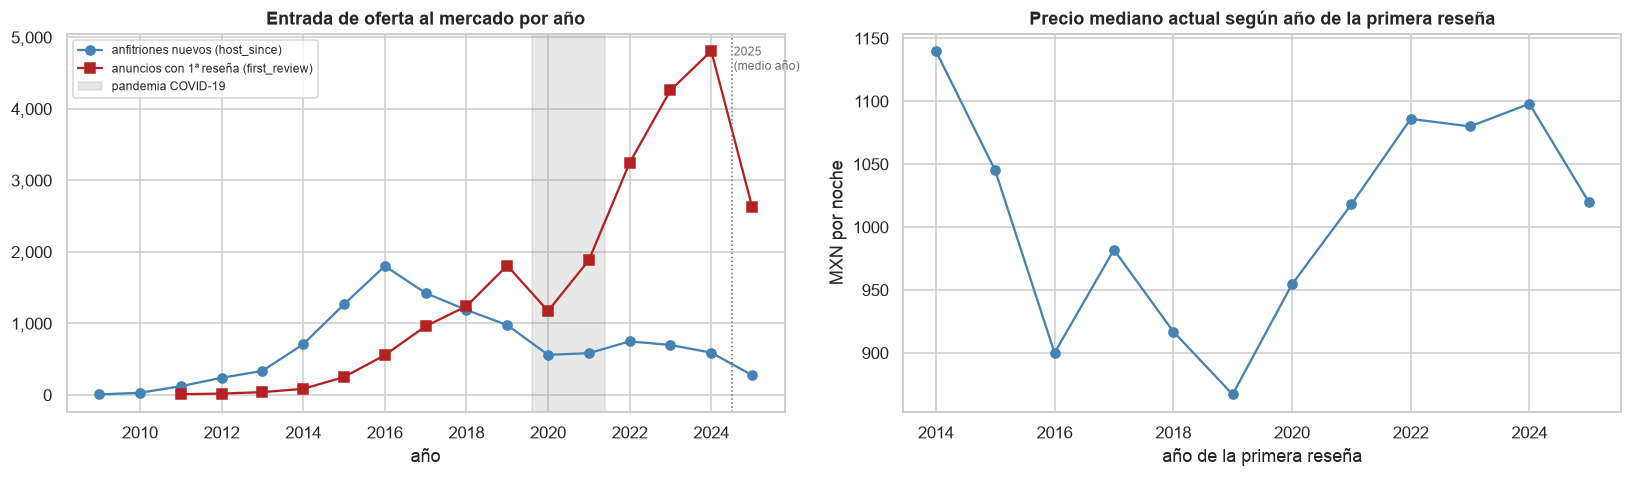

,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
hosts_nuevos,8,31,123,240,337,710,1267,1803,1425,1189,978,562,584,750,699,592,278
primeras_reseñas,<NA>,<NA>,11,20,40,86,251,557,962,1241,1810,1174,1885,3247,4260,4810,2633


In [118]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
anio_max = int(df["last_scraped"].dt.year.max())
hosts_unicos = df.drop_duplicates("host_id")
altas = hosts_unicos["host_since_year"].value_counts().sort_index()
primeras = df["first_review_year"].value_counts().sort_index()

axes[0].plot(altas.index, altas.values, marker="o", color=AZUL, label="anfitriones nuevos (host_since)")
axes[0].plot(primeras.index, primeras.values, marker="s", color=ACENTO, label="anuncios con 1ª reseña (first_review)")
axes[0].axvspan(2019.6, 2021.4, color=GRIS, alpha=0.15, label="pandemia COVID-19")
axes[0].axvline(anio_max - 0.5, color=GRIS, ls=":", lw=1)
axes[0].text(anio_max - 0.45, axes[0].get_ylim()[1] * 0.9, f"{anio_max}\n(medio año)", fontsize=8, color=GRIS)
axes[0].set_title("Entrada de oferta al mercado por año"); axes[0].set_xlabel("año"); axes[0].legend(fontsize=8)
fmt_miles(axes[0])

precio_anio = df_p.groupby("first_review_year")["price"].median()
precio_anio = precio_anio[precio_anio.index >= 2014]
axes[1].plot(precio_anio.index.astype(int), precio_anio.values, marker="o", color=AZUL)
axes[1].set_title("Precio mediano actual según año de la primera reseña")
axes[1].set_xlabel("año de la primera reseña"); axes[1].set_ylabel("MXN por noche")
fig.tight_layout()
guardar(fig, "16_evolucion_temporal.png")
plt.show()
display(pd.DataFrame({"hosts_nuevos": altas, "primeras_reseñas": primeras}).T)

**i. Tipo de gráfico y observaciones.** Gráficos de líneas por año, la forma adecuada para mostrar una evolución temporal; se sombrea el periodo de la pandemia y se marca que 2025 es un año incompleto. Las primeras reseñas por año crecieron de 1,174 en 2020 a 4,810 en 2024 (4 veces), mientras que los anfitriones nuevos tuvieron su pico en 2016 (1,803) y desde 2020 se mantienen entre 560 y 750 por año. En 2020 las primeras reseñas cayeron 35% respecto a 2019. A la derecha, el precio mediano según el año de la primera reseña baja de \$1,140 (2014) a \$866 (2019) y vuelve a ~\$1,090 en 2022–2024.

**ii. Valores atípicos o anomalías.** El valor de 2025 (2,633) no es una caída: el scrape se hizo a inicios de julio, así que es medio año. Los años 2009–2013 tienen muy pocos registros y sus valores son poco representativos.

**iii. Tendencias, patrones o agrupaciones.** Hay un auge posterior a la pandemia (2021–2024) en la entrada de anuncios al mercado. Como la oferta crece mucho más rápido que los anfitriones nuevos, el crecimiento proviene en buena medida de anfitriones existentes que suman anuncios, lo que es coherente con la profesionalización vista en la figura 15.

**iv. Comparaciones entre grupos.** Comparando las dos series: hasta 2017 entraban más anfitriones que anuncios con primera reseña; desde 2018 la relación se invierte y la brecha se amplía cada año.

**Implicaciones para el proyecto.** El dataset es una foto de los anuncios vigentes en 2025: los anuncios antiguos que salieron del mercado no aparecen (sesgo de supervivencia), así que la serie no debe leerse como el tamaño histórico del mercado. La antigüedad del anfitrión casi no se relaciona con el precio (Spearman 0.03).

#### Figura 17. Disponibilidad del calendario y ocupación estimada

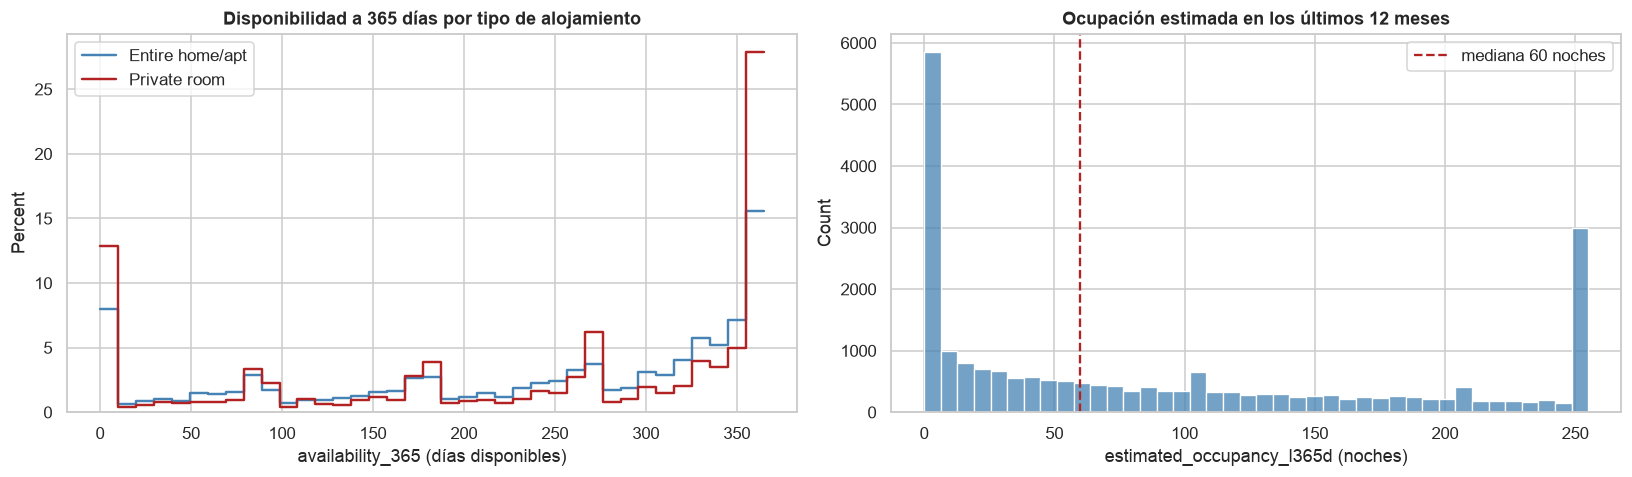

availability_365 = 0: 8.8% | >= 300: 43.7% | entre 1 y 299: 47.5%
Ocupación estimada = 0: 20.3% | >= 200 noches: 19.3%


In [119]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for r, color in zip(["Entire home/apt", "Private room"], [AZUL, ACENTO]):
    sns.histplot(df.loc[df["room_type"] == r, "availability_365"], bins=37, stat="percent", element="step",
                 fill=False, color=color, lw=1.6, label=r, ax=axes[0])
axes[0].set_title("Disponibilidad a 365 días por tipo de alojamiento"); axes[0].legend()
axes[0].set_xlabel("availability_365 (días disponibles)")

sns.histplot(df_p["estimated_occupancy_l365d"], bins=40, color=AZUL, ax=axes[1])
axes[1].axvline(df_p["estimated_occupancy_l365d"].median(), color=ACENTO, ls="--",
                label=f"mediana {df_p['estimated_occupancy_l365d'].median():.0f} noches")
axes[1].set_title("Ocupación estimada en los últimos 12 meses"); axes[1].legend()
axes[1].set_xlabel("estimated_occupancy_l365d (noches)")
fig.tight_layout()
guardar(fig, "17_disponibilidad_ocupacion.png")
plt.show()

a = df["availability_365"]
print(f"availability_365 = 0: {(a == 0).mean():.1%} | >= 300: {(a >= 300).mean():.1%} | entre 1 y 299: {a.between(1, 299).mean():.1%}")
print(f"Ocupación estimada = 0: {(df_p['estimated_occupancy_l365d'] == 0).mean():.1%} | >= 200 noches: {(df_p['estimated_occupancy_l365d'] >= 200).mean():.1%}")

**i. Tipo de gráfico y observaciones.** Histogramas escalonados normalizados a porcentaje para comparar la disponibilidad de dos grupos de tamaño muy distinto (completos y habitaciones privadas) y un histograma de la ocupación estimada con su mediana. La disponibilidad es bimodal: el 8.8% de los anuncios tiene 0 días disponibles y el 43.7% tiene 300 o más. La ocupación estimada tiene mediana de 60 noches, con un 20.3% de anuncios en 0 y una acumulación en 255 noches.

**ii. Valores atípicos o anomalías.** La barra en 255 noches (12.4% de los anuncios) es un tope de la estimación (255/365 ≈ 70% del año), no ocupación real: el dato está censurado y la ocupación verdadera de esos anuncios puede ser mayor. Los anuncios con 0 noches de ocupación y calendario abierto todo el año son candidatos a estar inactivos.

**iii. Tendencias, patrones o agrupaciones.** Dos comportamientos opuestos: anuncios siempre abiertos y anuncios bloqueados (fuera de temporada, ocupados por estancias largas o inactivos). La zona intermedia está poco poblada.

**iv. Comparaciones entre grupos.** Las habitaciones privadas tienen el calendario abierto todo el año con más frecuencia (28.7% con 355 días o más) que los espacios completos (16.4%), y también más anuncios con 0 días.

**Implicaciones para el proyecto.** `availability_365` mide días libres, no demanda; no debe usarse como ocupación. Para cualquier análisis de ingresos conviene excluir los anuncios inactivos y tratar el tope de 255 como censura.

#### Figura 18. Estancia mínima exigida

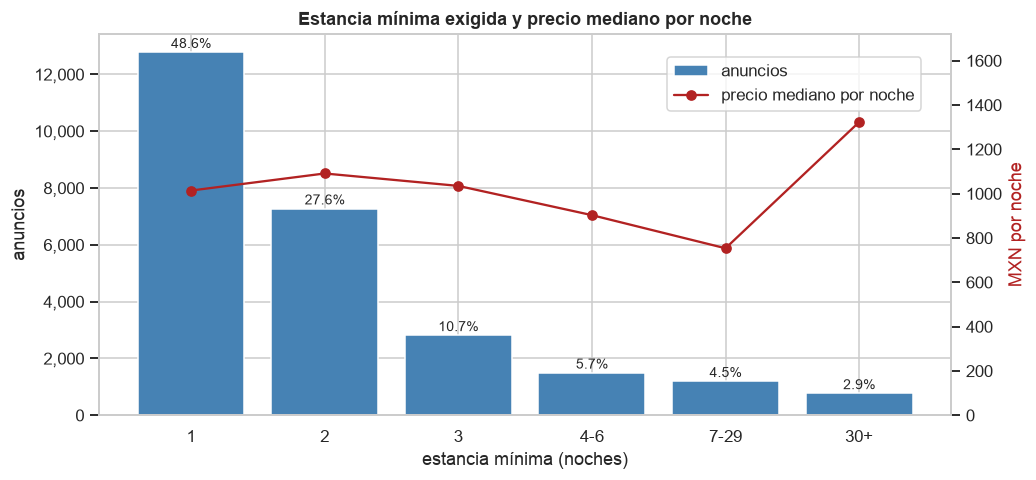

,1,2,3,4-6,7-29,30+
anuncios,"12,780.00","7,273.00","2,812.00","1,492.00","1,196.00",769.00
precio_mediano,"1,014.00","1,091.00","1,035.00",903.00,754.00,"1,323.00"


In [120]:
cats = pd.cut(df["minimum_nights"], bins=[0, 1, 2, 3, 6, 29, 365],
              labels=["1", "2", "3", "4-6", "7-29", "30+"])
conteo_mn = cats.value_counts().sort_index()
precio_mn = df_p.assign(mn=cats).groupby("mn", observed=True)["price"].median()

fig, ax1 = plt.subplots(figsize=(10, 4.5))
ax1.bar(conteo_mn.index.astype(str), conteo_mn.values, color=AZUL, label="anuncios")
for x, v in enumerate(conteo_mn.values):
    ax1.text(x, v + 150, f"{v / conteo_mn.sum():.1%}", ha="center", fontsize=9)
ax1.set_xlabel("estancia mínima (noches)"); ax1.set_ylabel("anuncios"); fmt_miles(ax1)
ax2 = ax1.twinx()
ax2.plot(precio_mn.index.astype(str), precio_mn.values, color=ACENTO, marker="o", label="precio mediano por noche")
ax2.set_ylabel("MXN por noche", color=ACENTO); ax2.grid(False); ax2.set_ylim(0, precio_mn.max() * 1.3)
ax1.set_title("Estancia mínima exigida y precio mediano por noche")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.85))
guardar(fig, "18_minimum_nights.png")
plt.show()
display(pd.DataFrame({"anuncios": conteo_mn, "precio_mediano": precio_mn}).T.round(0))

**i. Tipo de gráfico y observaciones.** Gráfico combinado: barras para la cantidad de anuncios por rango de estancia mínima y una línea en un eje secundario con el precio mediano por noche. Así se ven en una sola figura la estructura de la oferta y su relación con la tarifa. El mercado es de estancias cortas: el 48.6% acepta 1 noche, el 27.6% exige 2 y el 10.7% exige 3 (86.9% en total con 3 noches o menos). Solo el 2.9% (769 anuncios) exige 30 noches o más.

**ii. Valores atípicos o anomalías.** En la sección 1.1 se eliminaron 7 anuncios con estancia mínima superior a 365 noches. El segmento 30+ tiene un precio por noche mayor (\$1,323) que el de 7–29 noches (\$754), un comportamiento inesperado que conviene revisar: puede tratarse de rentas de mediano plazo de alta gama (83% son espacios completos) o de anuncios que publican una tarifa que no es por noche.

**iii. Tendencias, patrones o agrupaciones.** De 2 a 29 noches el precio por noche disminuye (\$1,091 → \$903 → \$754): los anfitriones que exigen estancias más largas ofrecen tarifas menores, coherente con un descuento por duración.

**iv. Comparaciones entre grupos.** El segmento de 30+ noches se comporta como un mercado distinto (renta mensual) del de estancias turísticas cortas.

**Implicaciones para el proyecto.** Para el modelo de precio conviene marcar o analizar por separado los anuncios de 30+ noches, porque su tarifa responde a una lógica diferente.

#### Figura 19. Ingreso estimado, precio y ocupación por alcaldía

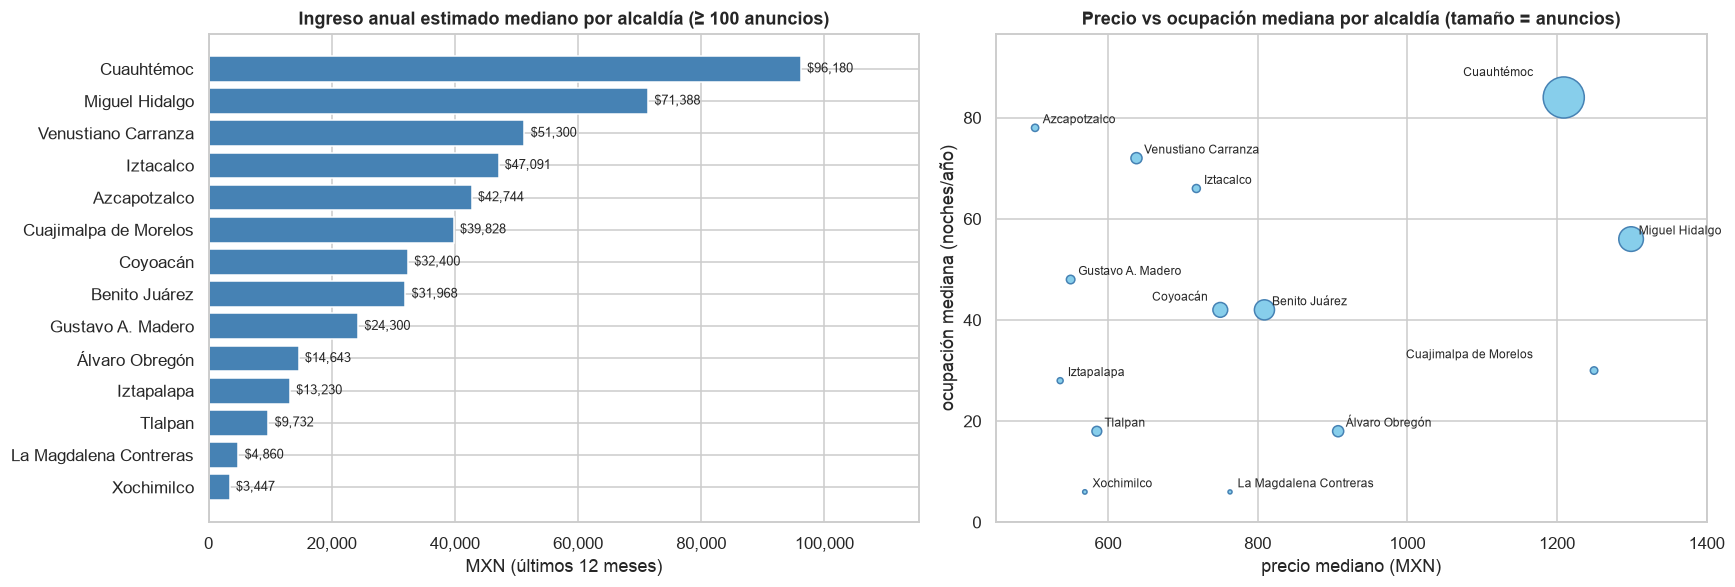

,anuncios,precio_mediano,ocupacion_mediana,ingreso_mediano
neighbourhood_cleansed,,,,
Cuauhtémoc,10858,"1,209.00",84.00,"96,180.00"
Miguel Hidalgo,3897,"1,299.00",56.00,"71,388.00"
Venustiano Carranza,795,638.00,72.00,"51,300.00"
Iztacalco,412,718.00,66.00,"47,091.00"
Azcapotzalco,338,502.00,78.00,"42,744.00"
Cuajimalpa de Morelos,358,"1,250.00",30.00,"39,828.00"
Coyoacán,1410,750.00,42.00,"32,400.00"
Benito Juárez,2599,809.00,42.00,"31,968.00"
Gustavo A. Madero,467,550.00,48.00,"24,300.00"


In [121]:
ingreso = (df_p.groupby("neighbourhood_cleansed", observed=True)
           .agg(anuncios=("id", "count"), precio_mediano=("price", "median"),
                ocupacion_mediana=("estimated_occupancy_l365d", "median"),
                ingreso_mediano=("estimated_revenue_l365d", "median"))
           .query("anuncios >= 100").sort_values("ingreso_mediano"))

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
axes[0].barh(ingreso.index, ingreso["ingreso_mediano"], color=AZUL)
for y, v in enumerate(ingreso["ingreso_mediano"]):
    axes[0].text(v + 1000, y, f"${v:,.0f}", va="center", fontsize=8.5)
axes[0].set_title("Ingreso anual estimado mediano por alcaldía (≥ 100 anuncios)")
axes[0].set_xlabel("MXN (últimos 12 meses)"); fmt_miles(axes[0], "x")
axes[0].set_xlim(0, ingreso["ingreso_mediano"].max() * 1.2)

axes[1].scatter(ingreso["precio_mediano"], ingreso["ocupacion_mediana"], s=ingreso["anuncios"] / 15,
                color=AZUL_CLARO, edgecolor=AZUL)
desplaz = {"Coyoacán": (-8, 6), "Cuajimalpa de Morelos": (-40, 8), "Cuauhtémoc": (-20, 14)}
for alc, fila in ingreso.iterrows():
    dx, dy = desplaz.get(alc, (5, 3))
    axes[1].annotate(alc, (fila["precio_mediano"], fila["ocupacion_mediana"]), fontsize=8,
                     xytext=(dx, dy), textcoords="offset points", ha="right" if dx < 0 else "left")
axes[1].set_xlim(450, 1400); axes[1].set_ylim(0, ingreso["ocupacion_mediana"].max() * 1.15)
axes[1].set_title("Precio vs ocupación mediana por alcaldía (tamaño = anuncios)")
axes[1].set_xlabel("precio mediano (MXN)"); axes[1].set_ylabel("ocupación mediana (noches/año)")
fig.tight_layout()
guardar(fig, "19_ingreso_por_alcaldia.png")
plt.show()
ingreso.sort_values("ingreso_mediano", ascending=False).round(0)

**i. Tipo de gráfico y observaciones.** Barras horizontales con el ingreso anual estimado mediano y un gráfico de burbujas (precio vs. ocupación, tamaño = número de anuncios) para entender de qué depende ese ingreso. Se incluyen solo alcaldías con 100 o más anuncios con precio. Cuauhtémoc (\$96,180) y Miguel Hidalgo (\$71,388) encabezan el ingreso mediano. Llama la atención Venustiano Carranza (\$51,300), tercera pese a tener un precio mediano bajo (\$638), gracias a una ocupación de 72 noches. En el extremo opuesto, Xochimilco (\$3,447) y La Magdalena Contreras (\$4,860) tienen ocupaciones medianas de solo 6 noches.

**ii. Valores atípicos o anomalías.** El ingreso estimado es una de las variables más asimétricas del dataset (asimetría de 7.88): media de \$129,888 frente a mediana de \$58,320 y un máximo de \$8.5 millones; por eso se usa la mediana. Cuajimalpa es un caso particular: precio alto (\$1,250) pero ocupación baja (30 noches).

**iii. Tendencias, patrones o agrupaciones.** A nivel de alcaldía no hay relación positiva entre precio y ocupación: las burbujas no siguen una diagonal. La ocupación es la que más diferencia el ingreso entre zonas.

**iv. Comparaciones entre grupos.** Benito Juárez vs. Venustiano Carranza: Benito Juárez cobra más (\$809 vs. \$638) pero ocupa menos (42 vs. 72 noches) y termina con menor ingreso (\$31,968 vs. \$51,300). Venustiano Carranza alberga el aeropuerto de la ciudad, lo que podría explicar su demanda (hipótesis por validar).

**Implicaciones para el proyecto.** Para un anfitrión, la decisión de precio no puede separarse de la ocupación. Si el proyecto evoluciona hacia recomendar tarifas, el objetivo debería ser el ingreso y no solo el precio.

#### Figura 20. Tiempo de respuesta y reserva inmediata

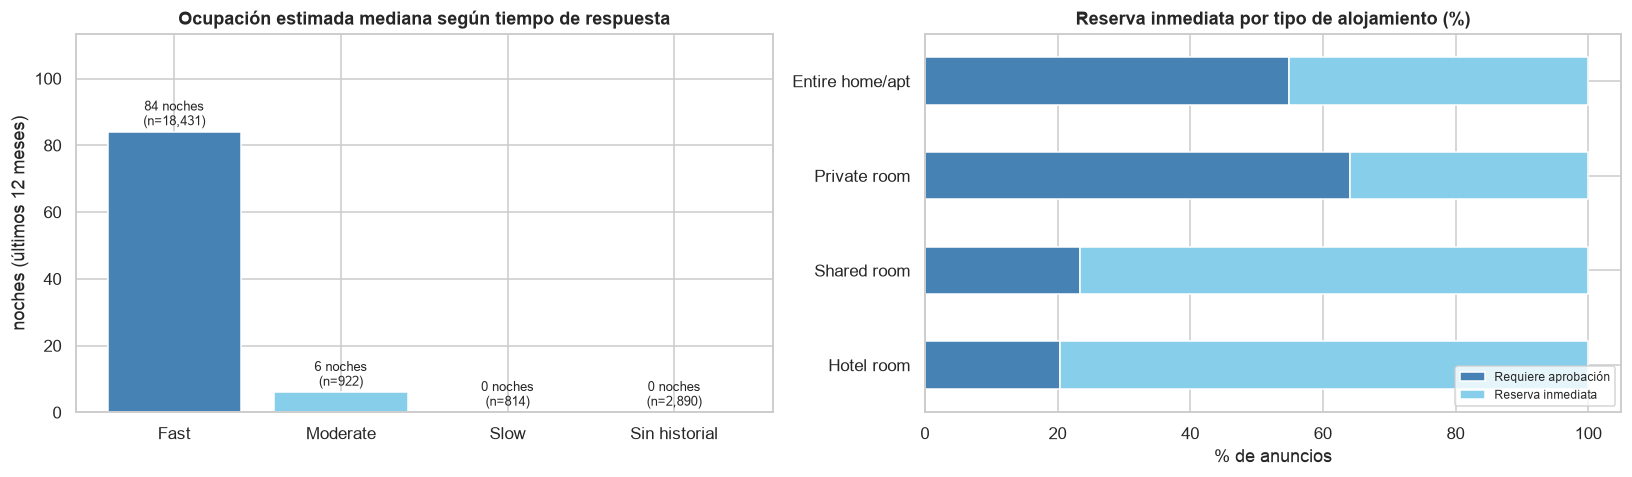

,anuncios,rating,ocupacion
respuesta,,,
Fast,18431,4.84,84.00
Moderate,922,4.86,6.00
Slow,814,4.83,0.00
Sin historial,2890,4.85,0.00


reserva,Requiere aprobación,Reserva inmediata
room_type,,
Entire home/apt,55.00,45.00
Private room,64.10,35.90
Shared room,23.40,76.60
Hotel room,20.40,79.60


In [122]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
resp = df_p.assign(respuesta=df_p["host_response_category"].astype(object).fillna("Sin historial"))
orden_resp = ["Fast", "Moderate", "Slow", "Sin historial"]
tabla_resp = resp.groupby("respuesta").agg(anuncios=("id", "count"), rating=("review_scores_rating", "median"),
                                           ocupacion=("estimated_occupancy_l365d", "median")).reindex(orden_resp)
axes[0].bar(orden_resp, tabla_resp["ocupacion"], color=[AZUL, AZUL_CLARO, ACENTO, GRIS])
for x, (v, n) in enumerate(zip(tabla_resp["ocupacion"], tabla_resp["anuncios"])):
    axes[0].text(x, v + 2, f"{v:.0f} noches\n(n={n:,})", ha="center", fontsize=8.5)
axes[0].set_title("Ocupación estimada mediana según tiempo de respuesta")
axes[0].set_ylabel("noches (últimos 12 meses)"); axes[0].set_ylim(0, tabla_resp["ocupacion"].max() * 1.35)

ib = df_p.assign(reserva=df_p["instant_bookable"].map({True: "Reserva inmediata", False: "Requiere aprobación"}))
tabla_ib = ib.groupby(["room_type", "reserva"], observed=True).size().unstack()
tabla_ib = tabla_ib.div(tabla_ib.sum(axis=1), axis=0).reindex(ORDEN_ROOM) * 100
tabla_ib.plot(kind="barh", stacked=True, color=[AZUL, AZUL_CLARO], ax=axes[1])
axes[1].set_title("Reserva inmediata por tipo de alojamiento (%)"); axes[1].set_xlabel("% de anuncios"); axes[1].set_ylabel("")
axes[1].legend(loc="lower right", fontsize=8); axes[1].invert_yaxis()
fig.tight_layout()
guardar(fig, "20_respuesta_reserva.png")
plt.show()
display(tabla_resp.round(2))
display(tabla_ib.round(1))

**i. Tipo de gráfico y observaciones.** Barras con la ocupación mediana por categoría de tiempo de respuesta y barras apiladas al 100% para comparar la proporción de reserva inmediata entre tipos de alojamiento con tamaños muy distintos. Los anuncios de anfitriones que responden rápido (Fast, 18,431 anuncios) tienen una ocupación mediana de 84 noches; los Moderate, 6 noches; y los Slow y los Sin historial (2,890), 0 noches. La calificación mediana, en cambio, es casi igual en todos los grupos (4.83–4.86). La reserva inmediata está en el 79.6% de los Hotel room y el 76.6% de los Shared room, frente al 45% de los espacios completos y el 35.9% de las habitaciones privadas.

**ii. Valores atípicos o anomalías.** El grupo Sin historial no es un faltante aleatorio: son anuncios con 0 reseñas en los últimos 12 meses y calendario casi siempre libre (mediana de 269 días disponibles), es decir, anuncios mayormente inactivos. Por eso en la codificación se conservó como categoría propia.

**iii. Tendencias, patrones o agrupaciones.** La rapidez de respuesta es un fuerte indicador de anfitrión activo: separa a los anuncios con demanda real de los que están publicados pero no operan.

**iv. Comparaciones entre grupos.** Los alojamientos profesionales (hoteles, hostales con habitaciones compartidas) usan reserva inmediata; los anfitriones particulares que rentan una habitación de su casa prefieren aprobar a cada huésped.

**Implicaciones para el proyecto.** `host_response_category` y `instant_bookable` son útiles para explicar la ocupación y para filtrar anuncios inactivos antes de analizar precios e ingresos.

#### Figura 21. Relaciones cruzadas entre variables clave (pairplot)

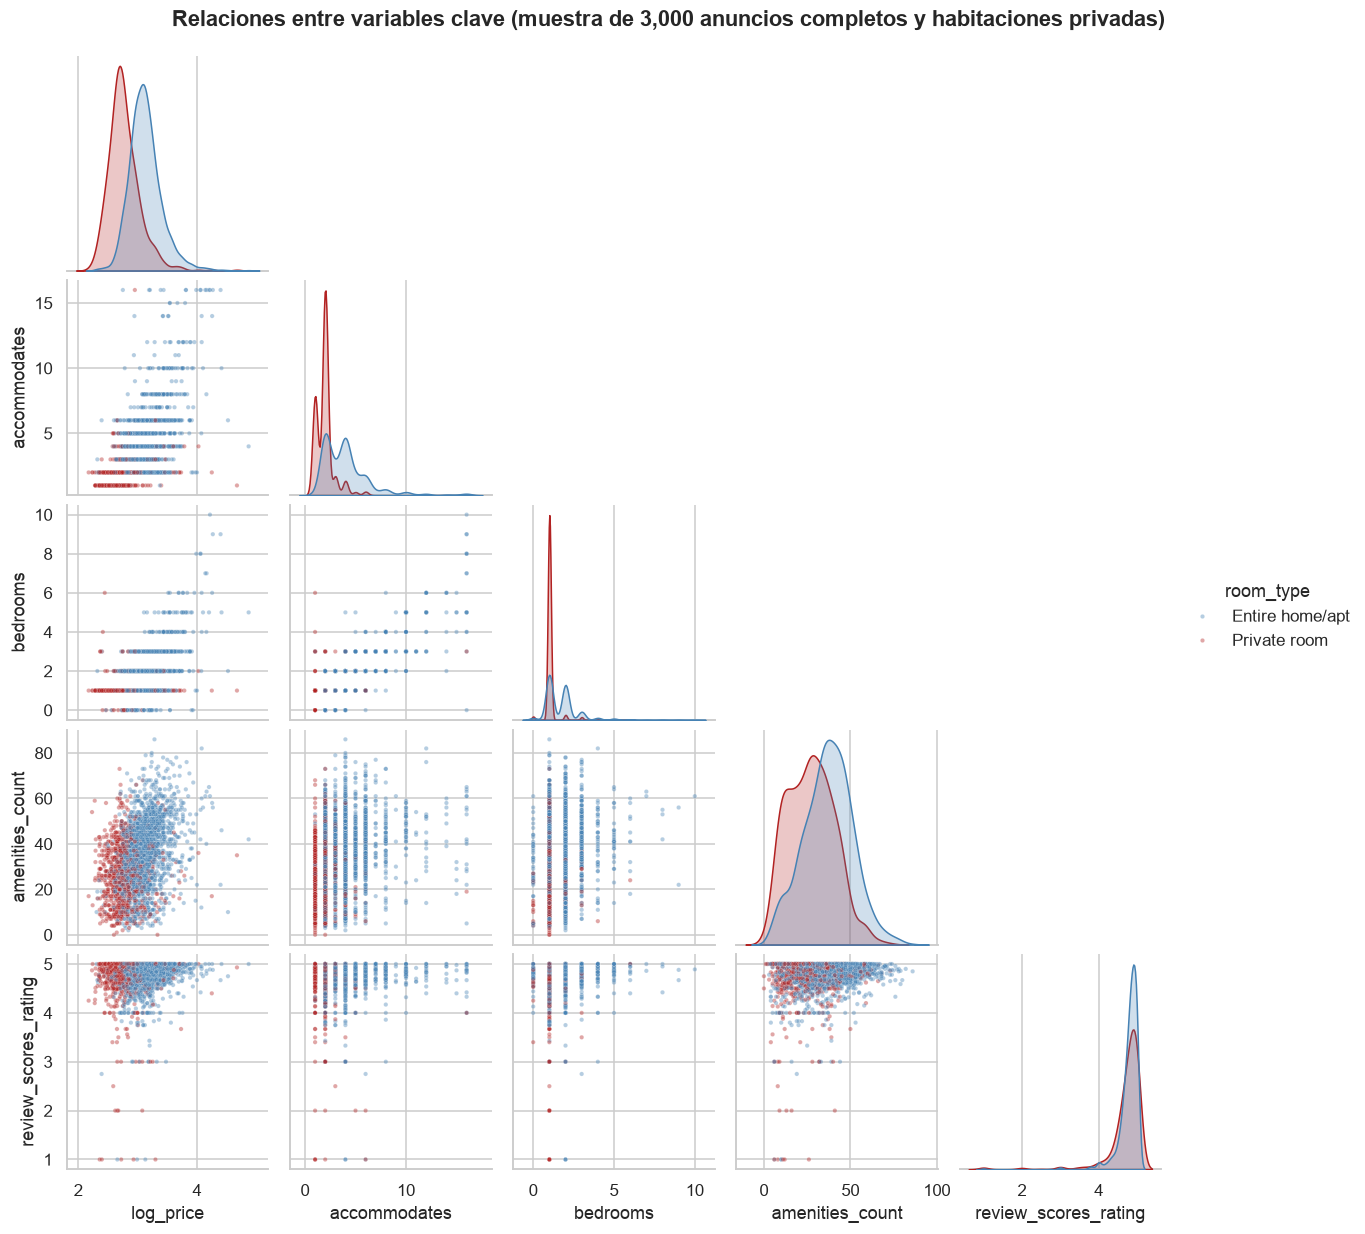

In [123]:
muestra_pp = df_p[df_p["room_type"].isin(["Entire home/apt", "Private room"])].sample(n=3000, random_state=42)
vars_pp = ["log_price", "accommodates", "bedrooms", "amenities_count", "review_scores_rating"]
g = sns.pairplot(muestra_pp[vars_pp + ["room_type"]].dropna(), hue="room_type",
                 hue_order=["Entire home/apt", "Private room"], palette=[AZUL, ACENTO],
                 corner=True, plot_kws={"s": 8, "alpha": 0.4}, diag_kws={"common_norm": False}, height=2.2)
g.figure.suptitle("Relaciones entre variables clave (muestra de 3,000 anuncios completos y habitaciones privadas)", y=1.02, fontweight="bold")
g.figure.savefig(FIG / "21_pairplot.png", bbox_inches="tight", dpi=150)
plt.show()

**i. Tipo de gráfico y observaciones.** Matriz de dispersión (pairplot) con densidades en la diagonal y color por tipo de alojamiento, sobre una muestra aleatoria de 3,000 anuncios para que los puntos sean legibles. Permite ver en una sola figura todas las relaciones de a pares y si cambian según el grupo. En la diagonal, la densidad de log_price de las habitaciones privadas está claramente desplazada a la izquierda de la de los espacios completos. Accommodates y bedrooms muestran relación positiva con log_price; los espacios completos declaran más amenities (su densidad está a la derecha) y la calificación no muestra relación con ninguna variable.

**ii. Valores atípicos o anomalías.** Aparecen habitaciones privadas con 9 o 10 recámaras (la recámara que se renta dentro de una casa grande, donde `bedrooms` describe la casa y no la habitación) y anuncios con calificación de 1 a 3, que son los de pocas reseñas vistos en la figura 13.

**iii. Tendencias, patrones o agrupaciones.** Los dos tipos de alojamiento forman nubes diferenciadas en log_price: el tipo de alojamiento actúa como una variable que desplaza toda la relación entre tamaño y precio.

**iv. Comparaciones entre grupos.** Para una misma capacidad, los espacios completos son más caros que las habitaciones; esto sugiere una interacción entre `room_type` y las variables de tamaño.

**Implicaciones para el proyecto.** El modelo debe incluir `room_type` y considerar interacciones, o entrenarse por segmento; además, el significado de `bedrooms` cambia según el tipo de alojamiento.

### g. Normalización y estandarización

- **Normalización (min-max):** $x' = \dfrac{x - \min(x)}{\max(x) - \min(x)}$. Lleva cada variable al rango
  [0, 1]. Es útil cuando el algoritmo requiere entradas acotadas (redes neuronales, KNN con variables acotadas),
  pero es muy sensible a los atípicos, porque el mínimo y el máximo definen la escala.
- **Estandarización (z-score):** $z = \dfrac{x - \mu}{\sigma}$. Deja cada variable con media 0 y desviación
  estándar 1, sin acotarla. Es la opción habitual para regresión regularizada, SVM, PCA o k-means.

Ambas son transformaciones lineales: cambian la escala y la ubicación de los datos, pero no su forma ni las
correlaciones entre variables. Se aplicaron con `MinMaxScaler` y `StandardScaler` de scikit-learn a seis variables
con escalas muy distintas: `price`, `accommodates`, `amenities_count`, `review_scores_rating`, `availability_365`
y `number_of_reviews`. scikit-learn ignora los nulos al ajustar y los conserva al transformar, así que no fue
necesario imputar. Las fórmulas se verificaron a mano contra el resultado de la librería.

In [124]:
VARS_ESC = ["price", "accommodates", "amenities_count", "review_scores_rating",
            "availability_365", "number_of_reviews"]
X = df_p[VARS_ESC].astype(float)

minmax = MinMaxScaler()            # x' = (x - min) / (max - min)        -> rango [0, 1]
zscore = StandardScaler()          # z  = (x - media) / desviación std   -> media 0, std 1
X_minmax = pd.DataFrame(minmax.fit_transform(X), columns=VARS_ESC, index=X.index)
X_zscore = pd.DataFrame(zscore.fit_transform(X), columns=VARS_ESC, index=X.index)

# scikit-learn ignora los NaN al ajustar y los conserva al transformar: no hace falta imputar
resumen = pd.concat({
    "original": X.agg(["min", "max", "mean", "std"]).T,
    "min-max": X_minmax.agg(["min", "max", "mean", "std"]).T,
    "z-score": X_zscore.agg(["min", "max", "mean", "std"]).T,
}, axis=1)
resumen.round(3)

original                             min-max            \
                          min       max     mean      std     min  max mean   
price                   66.00 99,000.00 1,506.50 2,432.12    0.00 1.00 0.01   
accommodates             1.00     16.00     3.35     2.29    0.00 1.00 0.16   
amenities_count          0.00    102.00    32.57    15.49    0.00 1.00 0.32   
review_scores_rating     1.00      5.00     4.75     0.37    0.00 1.00 0.94   
availability_365         0.00    365.00   256.23   106.62    0.00 1.00 0.70   
number_of_reviews        0.00  1,342.00    56.68    85.71    0.00 1.00 0.04   

                          z-score                   
                      std     min   max  mean  std  
price                0.03   -0.59 40.09  0.00 1.00  
accommodates         0.15   -1.02  5.52  0.00 1.00  
amenities_count      0.15   -2.10  4.48  0.00 1.00  
review_scores_rating 0.09  -10.26  0.67 -0.00 1.00  
availability_365     0.29   -2.40  1.02  0.00 1.00  
number_of_reviews    0.06   -0.66 15.00 -0.00 1.00

In [125]:
# Comprobación manual de las fórmulas sobre price
x = X["price"]
manual_mm = (x - x.min()) / (x.max() - x.min())
manual_z = (x - x.mean()) / x.std(ddof=0)
assert np.allclose(manual_mm, X_minmax["price"], equal_nan=True)
assert np.allclose(manual_z, X_zscore["price"], equal_nan=True)
print("Fórmulas verificadas contra scikit-learn")

# El precio mediano en cada escala
print(f"Precio mediano -> original: ${x.median():,.0f} | min-max: {X_minmax['price'].median():.4f} | z-score: {X_zscore['price'].median():.3f}")
print(f"Con min-max, el {(X_minmax['price'] < 0.05).mean():.1%} de los precios queda por debajo de 0.05")

Fórmulas verificadas contra scikit-learn
Precio mediano -> original: $1,037 | min-max: 0.0098 | z-score: -0.193
Con min-max, el 96.9% de los precios queda por debajo de 0.05


La tabla confirma el resultado esperado: después de min-max todas las variables tienen mínimo 0 y máximo 1, y
después del z-score media 0 y desviación 1. La media normalizada muestra dónde está la masa de cada variable:
0.01 para el precio y 0.04 para el número de reseñas (aplastadas contra el 0 por sus atípicos) y 0.94 para la
calificación (concentrada cerca del máximo). Con z-score, el precio va de −0.59 a 40.09 y la calificación de
−10.26 a 0.67: los extremos siguen presentes, ahora medidos en desviaciones estándar.

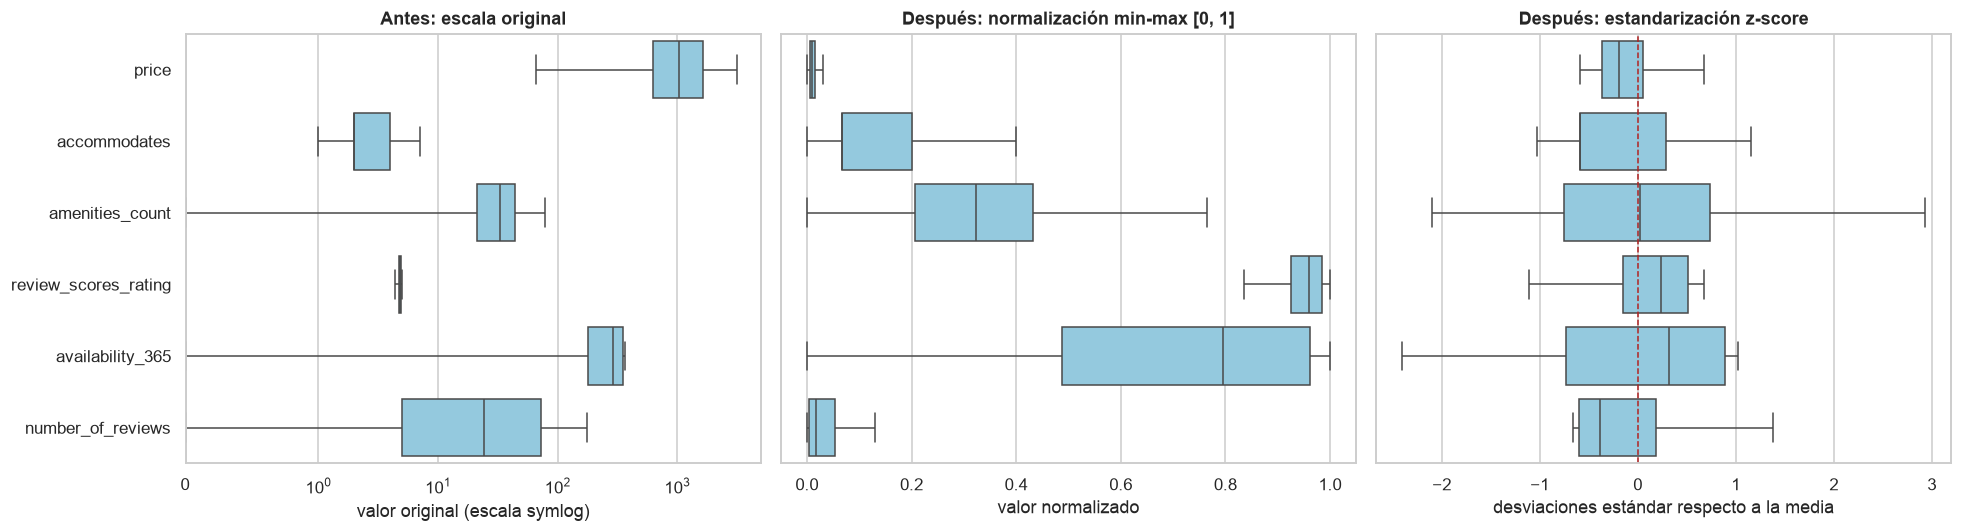

In [126]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, datos, titulo in zip(axes, [X, X_minmax, X_zscore],
                             ["Antes: escala original", "Después: normalización min-max [0, 1]",
                              "Después: estandarización z-score"]):
    sns.boxplot(data=datos, orient="h", color=AZUL_CLARO, showfliers=False, ax=ax)
    ax.set_title(titulo)
axes[0].set_xscale("symlog", linthresh=1); axes[0].set_xlim(0, 5000)
axes[0].set_xlabel("valor original (escala symlog)")
axes[1].set_xlabel("valor normalizado"); axes[2].set_xlabel("desviaciones estándar respecto a la media")
axes[2].axvline(0, color=ACENTO, ls="--", lw=1)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.tight_layout()
guardar(fig, "22_escalado_boxplots.png")
plt.show()

**Figura 22. Boxplots antes y después del escalado.**

**Antes:** cada variable vive en su propia escala (el precio en miles, la calificación entre 1 y 5, la disponibilidad entre 0 y 365) y fue necesario un eje symlog solo para poder dibujarlas juntas. En estas condiciones un algoritmo basado en distancias consideraría al precio miles de veces más importante que la calificación.

**Min-max:** todas quedan en [0, 1], pero el precio queda aplastado cerca de 0 (mediana 0.0098; el 96.9% de los anuncios por debajo de 0.05) porque el máximo de \$99,000 define el extremo de la escala. `number_of_reviews` sufre lo mismo. La normalización es muy sensible a los valores extremos.

**Z-score:** todas quedan centradas en 0 con desviación estándar 1, y las cajas son comparables. Sin embargo, el rango del precio estandarizado va de −0.59 a 40.09: los atípicos siguen ahí, ahora expresados como "40 desviaciones estándar sobre la media".

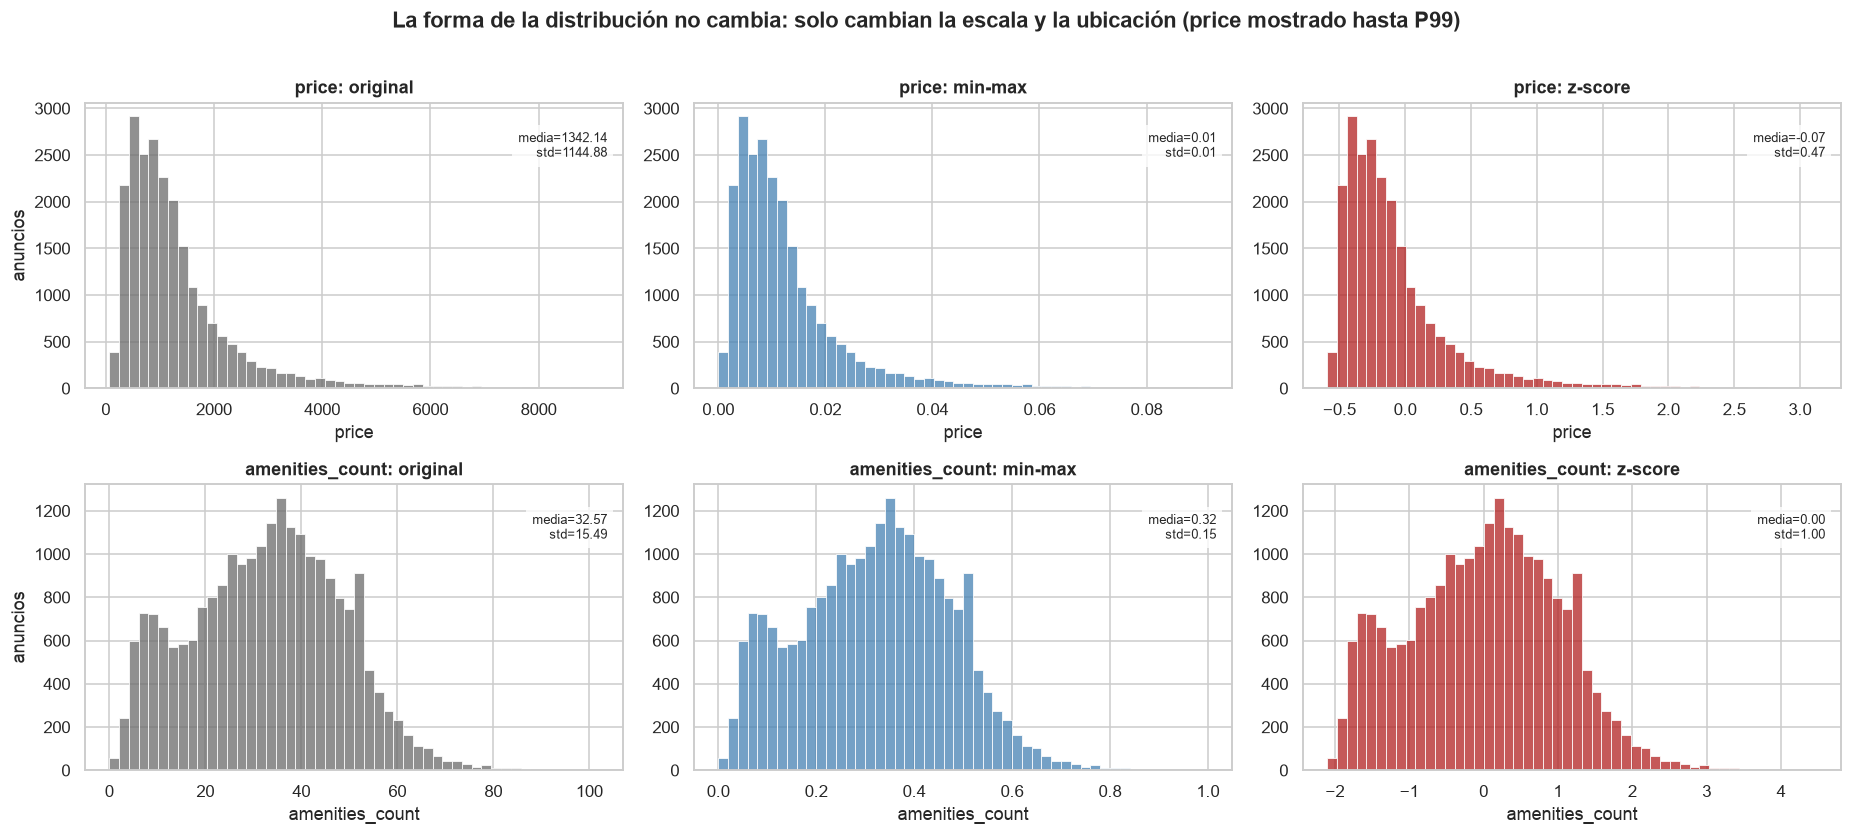

In [127]:
fig, axes = plt.subplots(2, 3, figsize=(17, 7.5))
pares = [("price", X["price"][X["price"] <= X["price"].quantile(0.99)]),
         ("amenities_count", X["amenities_count"])]
for fila, (col, original) in enumerate(pares):
    for ax, datos, titulo, color in zip(axes[fila],
                                        [original, X_minmax[col], X_zscore[col]],
                                        ["original", "min-max", "z-score"], [GRIS, AZUL, ACENTO]):
        if col == "price" and titulo != "original":
            datos = datos[X["price"] <= X["price"].quantile(0.99)]
        sns.histplot(datos.dropna(), bins=50, color=color, ax=ax)
        ax.set_title(f"{col}: {titulo}")
        ax.set_ylabel("anuncios" if titulo == "original" else "")
        ax.text(0.97, 0.9, f"media={datos.mean():.2f}\nstd={datos.std():.2f}", transform=ax.transAxes,
                ha="right", va="top", fontsize=8.5, bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"})
fig.suptitle("La forma de la distribución no cambia: solo cambian la escala y la ubicación (price mostrado hasta P99)",
             y=1.01, fontweight="bold")
fig.tight_layout()
guardar(fig, "23_escalado_histogramas.png")
plt.show()

**Figura 23. Histogramas antes y después: la forma no cambia.**

Los tres histogramas de cada fila son idénticos en forma; solo cambian los valores del eje X. Esto ocurre porque ambas técnicas son transformaciones lineales (restan una constante y dividen entre otra): no corrigen la asimetría del precio ni la bimodalidad de amenities, y tampoco alteran las correlaciones entre variables.

En `amenities_count`, que es casi simétrica, el z-score produce exactamente media 0.00 y desviación 1.00. En el precio (mostrado hasta el percentil 99) la media y la desviación del recorte difieren de 0 y 1 porque fueron calculadas con todos los datos, incluidos los atípicos.

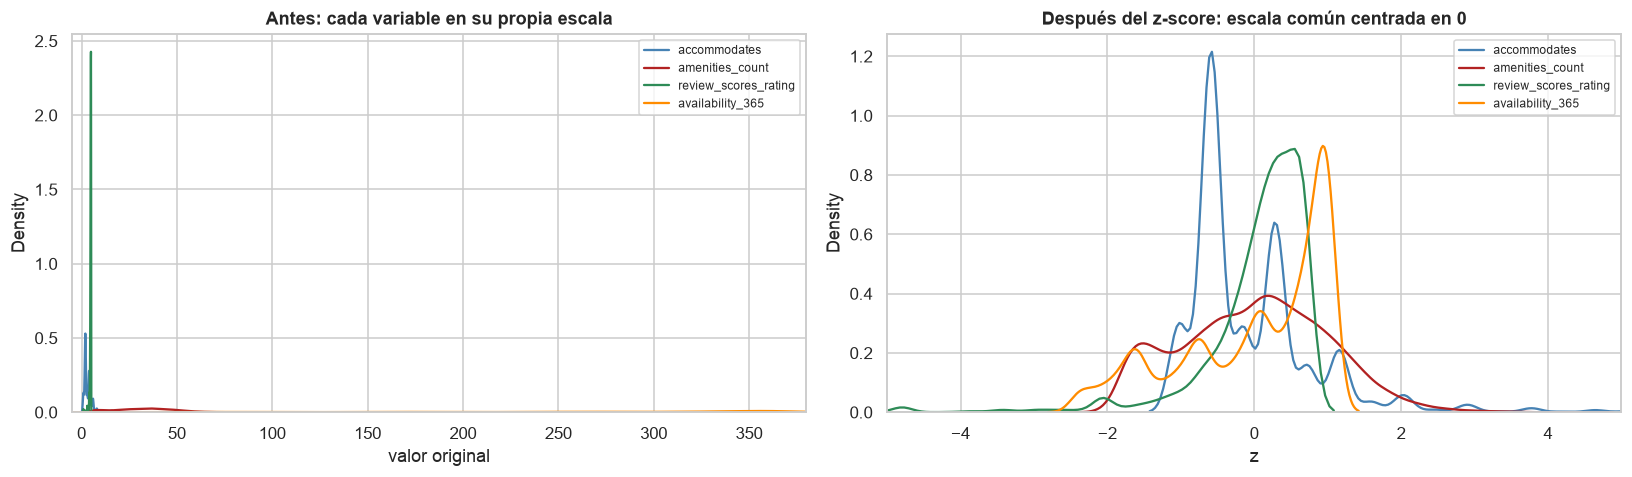

In [128]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for col, color in zip(["accommodates", "amenities_count", "review_scores_rating", "availability_365"],
                      [AZUL, ACENTO, "seagreen", "darkorange"]):
    sns.kdeplot(X[col].dropna(), ax=axes[0], color=color, label=col, warn_singular=False)
    sns.kdeplot(X_zscore[col].dropna(), ax=axes[1], color=color, label=col, warn_singular=False)
axes[0].set_title("Antes: cada variable en su propia escala"); axes[0].set_xlim(-5, 380); axes[0].legend(fontsize=8)
axes[0].set_xlabel("valor original")
axes[1].set_title("Después del z-score: escala común centrada en 0"); axes[1].set_xlim(-5, 5); axes[1].legend(fontsize=8)
axes[1].set_xlabel("z")
fig.tight_layout()
guardar(fig, "24_escalado_kde.png")
plt.show()

**Figura 24. Curvas de densidad antes y después de estandarizar.**

**Antes:** en el eje original las curvas son imposibles de comparar; la calificación aparece como un pico angosto cerca de 5 y la disponibilidad se extiende hasta 365.

Después del z-score las cuatro variables comparten la misma escala y se puede comparar su forma: accommodates es multimodal (picos en 2 y 4 huéspedes), la calificación tiene una cola larga a la izquierda, la disponibilidad se acumula en el extremo derecho (calendarios abiertos todo el año) y amenities es la más cercana a una campana.

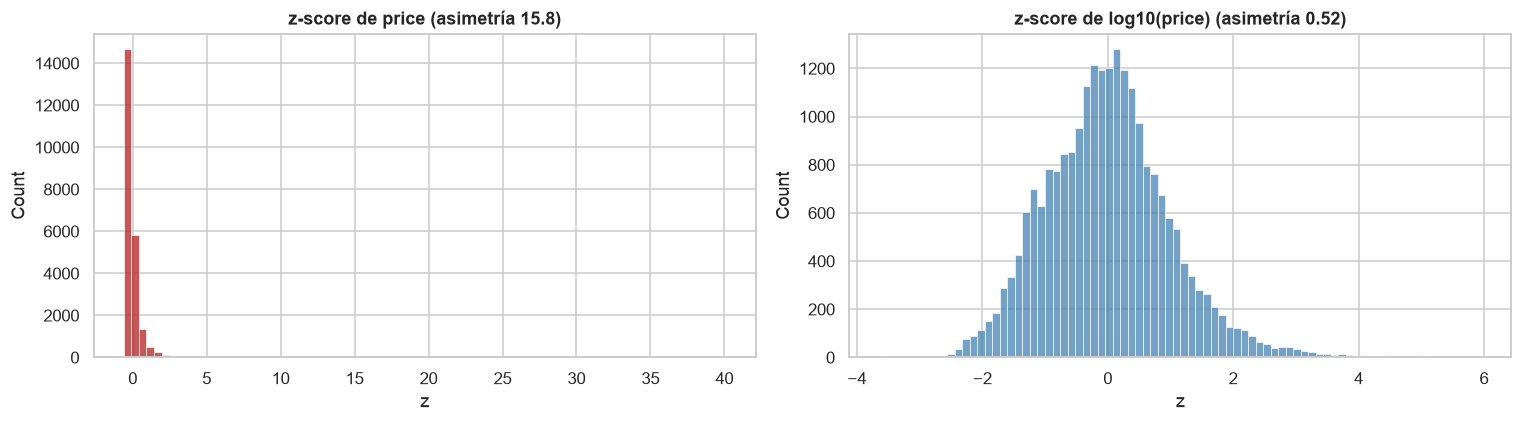

|z| > 3 en price: 249 anuncios | en log10(price): 187
Rango z de price: [-0.59, 40.09] | de log10(price): [-3.64, 5.96]


In [129]:
# Para price, que es muy asimétrico, se recomienda transformar con logaritmo ANTES de estandarizar
log_z = StandardScaler().fit_transform(np.log10(X[["price"]]))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(X_zscore["price"], bins=80, color=ACENTO, ax=axes[0])
axes[0].set_title(f"z-score de price (asimetría {stats.skew(X_zscore['price']):.1f})"); axes[0].set_xlabel("z")
sns.histplot(log_z.ravel(), bins=80, color=AZUL, ax=axes[1])
axes[1].set_title(f"z-score de log10(price) (asimetría {stats.skew(log_z.ravel()):.2f})"); axes[1].set_xlabel("z")
fig.tight_layout()
guardar(fig, "25_log_mas_zscore.png")
plt.show()
print(f"|z| > 3 en price: {(X_zscore['price'].abs() > 3).sum():,} anuncios | en log10(price): {(np.abs(log_z) > 3).sum():,}")
print(f"Rango z de price: [{X_zscore['price'].min():.2f}, {X_zscore['price'].max():.2f}] | "
      f"de log10(price): [{log_z.min():.2f}, {log_z.max():.2f}]")

**Figura 25. Transformación logarítmica + z-score para el precio.**

Para una variable tan asimétrica como el precio, estandarizar no basta: el z-score del precio crudo tiene asimetría 15.8 y casi todos los anuncios quedan apilados entre −0.6 y 1. Si primero se aplica log10 y después el z-score, la asimetría baja a 0.52, el rango queda en [−3.64, 5.96] y los anuncios con |z| > 3 bajan de 249 a 187.

**Recomendación para el proyecto:** usar log + z-score para el precio (y para conteos muy asimétricos como `number_of_reviews` u `host_listings_count`), min-max para variables acotadas por naturaleza (`availability_365`, calificaciones) cuando el algoritmo requiera entradas en [0, 1], y z-score para el resto de variables numéricas en modelos sensibles a la escala (regresión regularizada, KNN, SVM, PCA, k-means). Los modelos de árboles no requieren escalado.

## Conclusiones

La limpieza no terminó en la entrega 1. Al revisar de nuevo la capa silver aparecieron problemas que no se habían
detectado: fechas guardadas como el texto "NaT", estancias mínimas imposibles, una columna de barrio que casi no
tenía información útil y una binaria de wifi mal construida que hacía parecer más baratos a los anuncios con wifi.
También se encontró que el 12.4% de los anuncios no tiene precio porque están inactivos, así que se analizaron por
separado en lugar de imputarlos.

La distribución del precio es muy asimétrica (media de \$1,507 frente a una mediana de \$1,037) y se parece a una
log-normal, por lo que la mediana describe mejor el anuncio típico y para modelar conviene trabajar con el logaritmo.
Lo que más se relaciona con el precio es el tipo de alojamiento (un espacio completo cuesta unas 2.3 veces lo que una
habitación privada), la ubicación (la mediana de Miguel Hidalgo es casi cuatro veces la de Tláhuac, y los precios más
altos se concentran en Polanco y hacia Santa Fe), el tamaño del alojamiento y, en menor medida, la cantidad de
amenities. La calificación y las variables de demanda prácticamente no se relacionan con el precio.

El mercado está muy concentrado: tres alcaldías reúnen tres de cada cuatro anuncios y el 10% de los anfitriones maneja
casi la mitad de la oferta. La llegada de anuncios nuevos creció mucho después de la pandemia. Las calificaciones
están casi todas entre 4.5 y 5, por lo que ayudan poco a diferenciar anuncios, sobre todo cuando tienen pocas reseñas.
En cambio, la ocupación y el ingreso sí cambian mucho según la actividad del anfitrión: los superhost y quienes
responden rápido tienen muchas más noches ocupadas.

Por último, las variables categóricas quedaron convertidas con One-Hot Encoding y se compararon la normalización y la
estandarización. Para el precio funciona mejor aplicar primero el logaritmo y después estandarizar; la normalización
min-max es adecuada para variables que ya tienen un rango fijo, como la disponibilidad o la calificación.

In [130]:
print(f"Dataset analizado: {df.shape[0]:,} anuncios ({df_p.shape[0]:,} con precio) y {df.shape[1]} variables")
print(f"Dataset codificado (gold): {df_encoded.shape[0]:,} x {df_encoded.shape[1]}")
print("\nFiguras exportadas en ../reports/figures/eda:")
for f in sorted(FIG.glob("*.png")):
    print(" -", f.name)

Dataset analizado: 26,322 anuncios (23,057 con precio) y 66 variables
Dataset codificado (gold): 26,322 x 67

Figuras exportadas en ../reports/figures/eda:
 - 00_nulos_por_variable.png
 - 01_distribucion_price.png
 - 02_room_type_conteo_precio.png
 - 03_anuncios_por_alcaldia.png
 - 04_price_por_alcaldia.png
 - 05_mapa_densidad_precio.png
 - 06_property_type.png
 - 07_capacidad_precio.png
 - 08_habitaciones_banos_camas.png
 - 09_correlaciones.png
 - 10_amenities_precio.png
 - 11_prima_amenities.png
 - 12_calificaciones.png
 - 13_reviews_vs_rating.png
 - 14_superhost.png
 - 15_anfitriones_concentracion.png
 - 16_evolucion_temporal.png
 - 17_disponibilidad_ocupacion.png
 - 18_minimum_nights.png
 - 19_ingreso_por_alcaldia.png
 - 20_respuesta_reserva.png
 - 21_pairplot.png
 - 22_escalado_boxplots.png
 - 23_escalado_histogramas.png
 - 24_escalado_kde.png
 - 25_log_mas_zscore.png
